In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot
import awkward as ak

def gaus(x, A, mean, sigma):
    return A * np.exp(-((x - mean)**2) / (2*(sigma)**2))

def sigmoid(x, mean, width):
    return 1.0 / (1 + np.exp(width * (x - mean)))

['../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.7_Xpos41.25_Ypos105.000000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos43.3_Xpos41.25_Ypos105.000000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos44.8_Xpos41.25_Ypos105.000000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos40.3_Xpos41.25_Ypos105.000000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos42.1_Xpos41.25_Ypos105.000000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos41.8_Xpos41.25_Ypos105.000000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos45.4_Xpos41.25_Ypos105.000000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos45.7_Xpos41.25_Ypos105.000000.root',

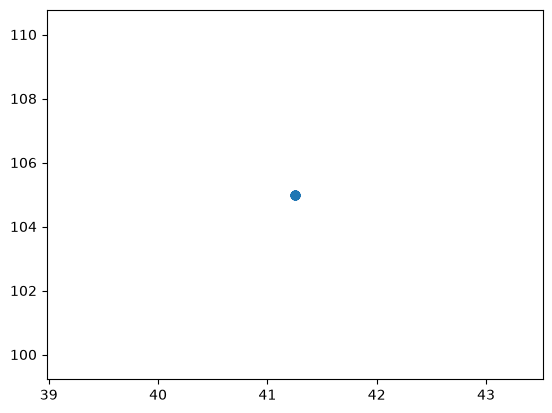

In [9]:
path = "../../Processed_data/"
files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser95pc_Temp16C_Zpos*_Xpos*00000.root")

print(files)
Z_range = [] # [41.5] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 11)
Y_range = [] # np.linspace(41.4, 41.7, 11)

map_plot_y = []
map_plot_x = []
map_plot_z = []

y_files = []

for file in files:
    filename = file.split(path)[1]

    if "Ypos" not in filename or "Zpos" not in filename or "Xpos" not in filename: 
        continue
    
    print(filename)
    y_files.append(file)
    # x_pos = np.round(float(filename.split("Xpos")[1].split("00000.root")[0]), 3)
    # x_pos = np.round(float(filename.split("Xpos")[1].split("00000.trc")[0]), 3)
    # z_pos = np.round(float(filename.split("Zpos")[1].split("_")[0])        , 3)
    
    x_pos = float(filename.split("Xpos")[1].split("_")[0])
    y_pos = float(filename.split("Ypos")[1].split("00000.root")[0])
    # x_pos = float(filename.split("Xpos")[1].split("00000.trc")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])

    # if z_pos < 40.0 and z_pos > 43.9: continue
    
    X_range.append(float(x_pos))
    Y_range.append(float(y_pos))
    Z_range.append(float(z_pos))
    map_plot_x.append(x_pos)
    map_plot_y.append(y_pos)
    map_plot_z.append(z_pos)

Z_range = np.unique(Z_range)
X_range = np.unique(X_range)
# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_y)
plt.show()

fields = [
    'i_evt',
    'channel',
    'time',
    'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    't_peak',
    'integral',
    # 'intfull',
    'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

In [10]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(y_files):
    # if map_plot_z[f_i] > 50: continue
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}_{map_plot_y[f_i]}"
    channel[l] = pulse["channel"]
    time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_42.7_41.25_105.0', 'pos_43.3_41.25_105.0', 'pos_44.8_41.25_105.0', 'pos_40.3_41.25_105.0', 'pos_42.1_41.25_105.0', 'pos_41.8_41.25_105.0', 'pos_45.4_41.25_105.0', 'pos_45.7_41.25_105.0', 'pos_43.6_41.25_105.0', 'pos_40.0_41.25_105.0', 'pos_43.9_41.25_105.0', 'pos_46.0_41.25_105.0', 'pos_44.2_41.25_105.0', 'pos_42.4_41.25_105.0', 'pos_40.6_41.25_105.0', 'pos_41.2_41.25_105.0', 'pos_43.0_41.25_105.0', 'pos_40.9_41.25_105.0', 'pos_44.5_41.25_105.0', 'pos_41.5_41.25_105.0', 'pos_45.1_41.25_105.0'])


In [11]:
plot_size = 7

def fit_gaus(hist, tag, output_folder, value_tag, plot_fits = True):
    nbins = 20
    y, x = np.histogram(hist, bins=nbins)
    x = np.array(x)
    y = np.array(y)

    hist = hist[hist != 0]

    # print(np.sum(hist != 0))
    
    mean = x[np.argmax(y)] # 
    mean = np.mean(hist)
    std  = np.std(hist)

    mask = np.ones(len(hist), dtype = bool)
    mask = (hist>(mean-3*std)) & (hist<(mean+3*std))
    
    # print(np.sum(hist != 0))
    # print()
    
    std  = np.std(hist[mask])
    mean = np.mean(hist[mask])
    y, x = np.histogram(hist[mask], bins=nbins)
    x = np.array(x)
    y = np.array(y)

    if (np.sum(mask) == 0):
        print("Discarding this fit -----------> ", mean, std)
        return 0, 0, 0

    percentage = 50
    # bounds = (
    #     ((1-percentage / 100)*np.max(y), (1-percentage / 100)*np.mean(hist[mask]), (1-percentage / 100)*np.std(hist[mask]) ),
    #     ((1+percentage / 100)*np.max(y), (1+percentage / 100)*np.mean(hist[mask]), (1+percentage / 100)*np.std(hist[mask]) )
    # )

    bounds = (
        ( (0)*np.max(y), (1-percentage / 100)*np.mean(hist[mask]), (1-percentage / 100)*np.std(hist[mask]) ),
        ( (2)*np.max(y), (1+percentage / 100)*np.mean(hist[mask]), (1+percentage / 100)*np.std(hist[mask]) )
    )
    
    # print(x[0:nbins], y[0:nbins])
    try:
        params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=( np.max(y), np.mean(x), std)) # , bounds = bounds) # , p0=( np.mean(y), mean, np.std(hist[mask]) ) )
        if (plot_fits):
            y_fit = [gaus(i, params[0][0], params[0][1], params[0][2]) for i in x[0:nbins]]
            # print(x[0:nbins])
            # print(y_fit)
            fig, ax = plt.subplots(1, 1, figsize = (plot_size, plot_size))
            ax.hist(hist[mask], bins = nbins, histtype="step")
            ax.plot([mean, mean], [0, np.max(y)], color = "black")
            ax.plot([params[0][1]-params[0][2], params[0][1]+params[0][2]], [np.max(y)/2, np.max(y)/2], color = "black")
            ax.plot(x[0:nbins], y_fit, "o", color = "red", label = f"Amplitude: {np.round(params[0][0],3)}, Mean: {np.round(params[0][1],3)}, Sigma: {np.round(params[0][2],3)}")
            ax.set_xlabel(value_tag) # "Timestamps [ns]")
            ax.set_ylabel("Number of events")
            plt.legend()
            fig.savefig(f"./{output_folder}/{tag}.png")
            return params[0][0], params[0][1], params[0][2]

    except:
        if (plot_fits):
            fig, ax = plt.subplots(1, 1, figsize = (plot_size, plot_size))
            ax.hist(hist[mask], bins = nbins, histtype="step")
            ax.set_xlabel(value_tag)
            ax.set_ylabel("Number of events")
            plt.legend()
            # plt.show()
            fig.savefig(f"./{output_folder}/{tag}.png")
            return 0, 0, 0
    
    # params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=( np.max(y), np.mean(x), std ), bounds = bounds) # , p0=( np.mean(y), mean, np.std(hist[mask]) ) )
    # print("Parameters     ----------------> ", mean, std)
    # print("Fit parameters ----------------> ", params[0][1], params[0][2])
    # print()
    # return np.max(y), mean, std 

cols = 2
rows = 1

strip_index = 0

# fig, ax = plt.subplots(rows, cols, figsize = (plot_size*cols, plot_size*rows))
# Z_range = [50.0, 50.8]
# print(Z_range)

# os.system("rm ./TimestampFits/*")
# os.system("rm ./AmplitudeFits/*")


In [12]:
channel

{'pos_42.7_41.25_105.0': <Array [[[-2.12, -2.09, ..., -6.81], ...], ...] type='500 * 8 * 4631 * float32'>,
 'pos_43.3_41.25_105.0': <Array [[[-0.98, ..., -5.32], ..., [...]], ...] type='500 * 8 * 4631 * float32'>,
 'pos_44.8_41.25_105.0': <Array [[[2.05, 2.08, ..., -3.67], ...], ...] type='500 * 8 * 4631 * float32'>,
 'pos_40.3_41.25_105.0': <Array [[[-3.56, -3.54, ..., -2.08], ...], ...] type='500 * 8 * 4631 * float32'>,
 'pos_42.1_41.25_105.0': <Array [[[0.993, 0.909, ..., -2.94], ...], ...] type='500 * 8 * 4631 * float32'>,
 'pos_41.8_41.25_105.0': <Array [[[-0.405, ..., -5.54], ...], ...] type='500 * 8 * 4631 * float32'>,
 'pos_45.4_41.25_105.0': <Array [[[-2.58, -2.46, ..., -3.95], ...], ...] type='500 * 8 * 4631 * float32'>,
 'pos_45.7_41.25_105.0': <Array [[[-1.11, -1.03, ..., -4.6], ...], ...] type='500 * 8 * 4631 * float32'>,
 'pos_43.6_41.25_105.0': <Array [[[-0.888, ..., -3.22], ...], ...] type='500 * 8 * 4631 * float32'>,
 'pos_40.0_41.25_105.0': <Array [[[-1.18, -1.06, ...

[[0.0965, 0.0924, 0.0883, 0.0844, 0.08, ..., -5.4, -5.11, -4.81, -4.5], ...] 8


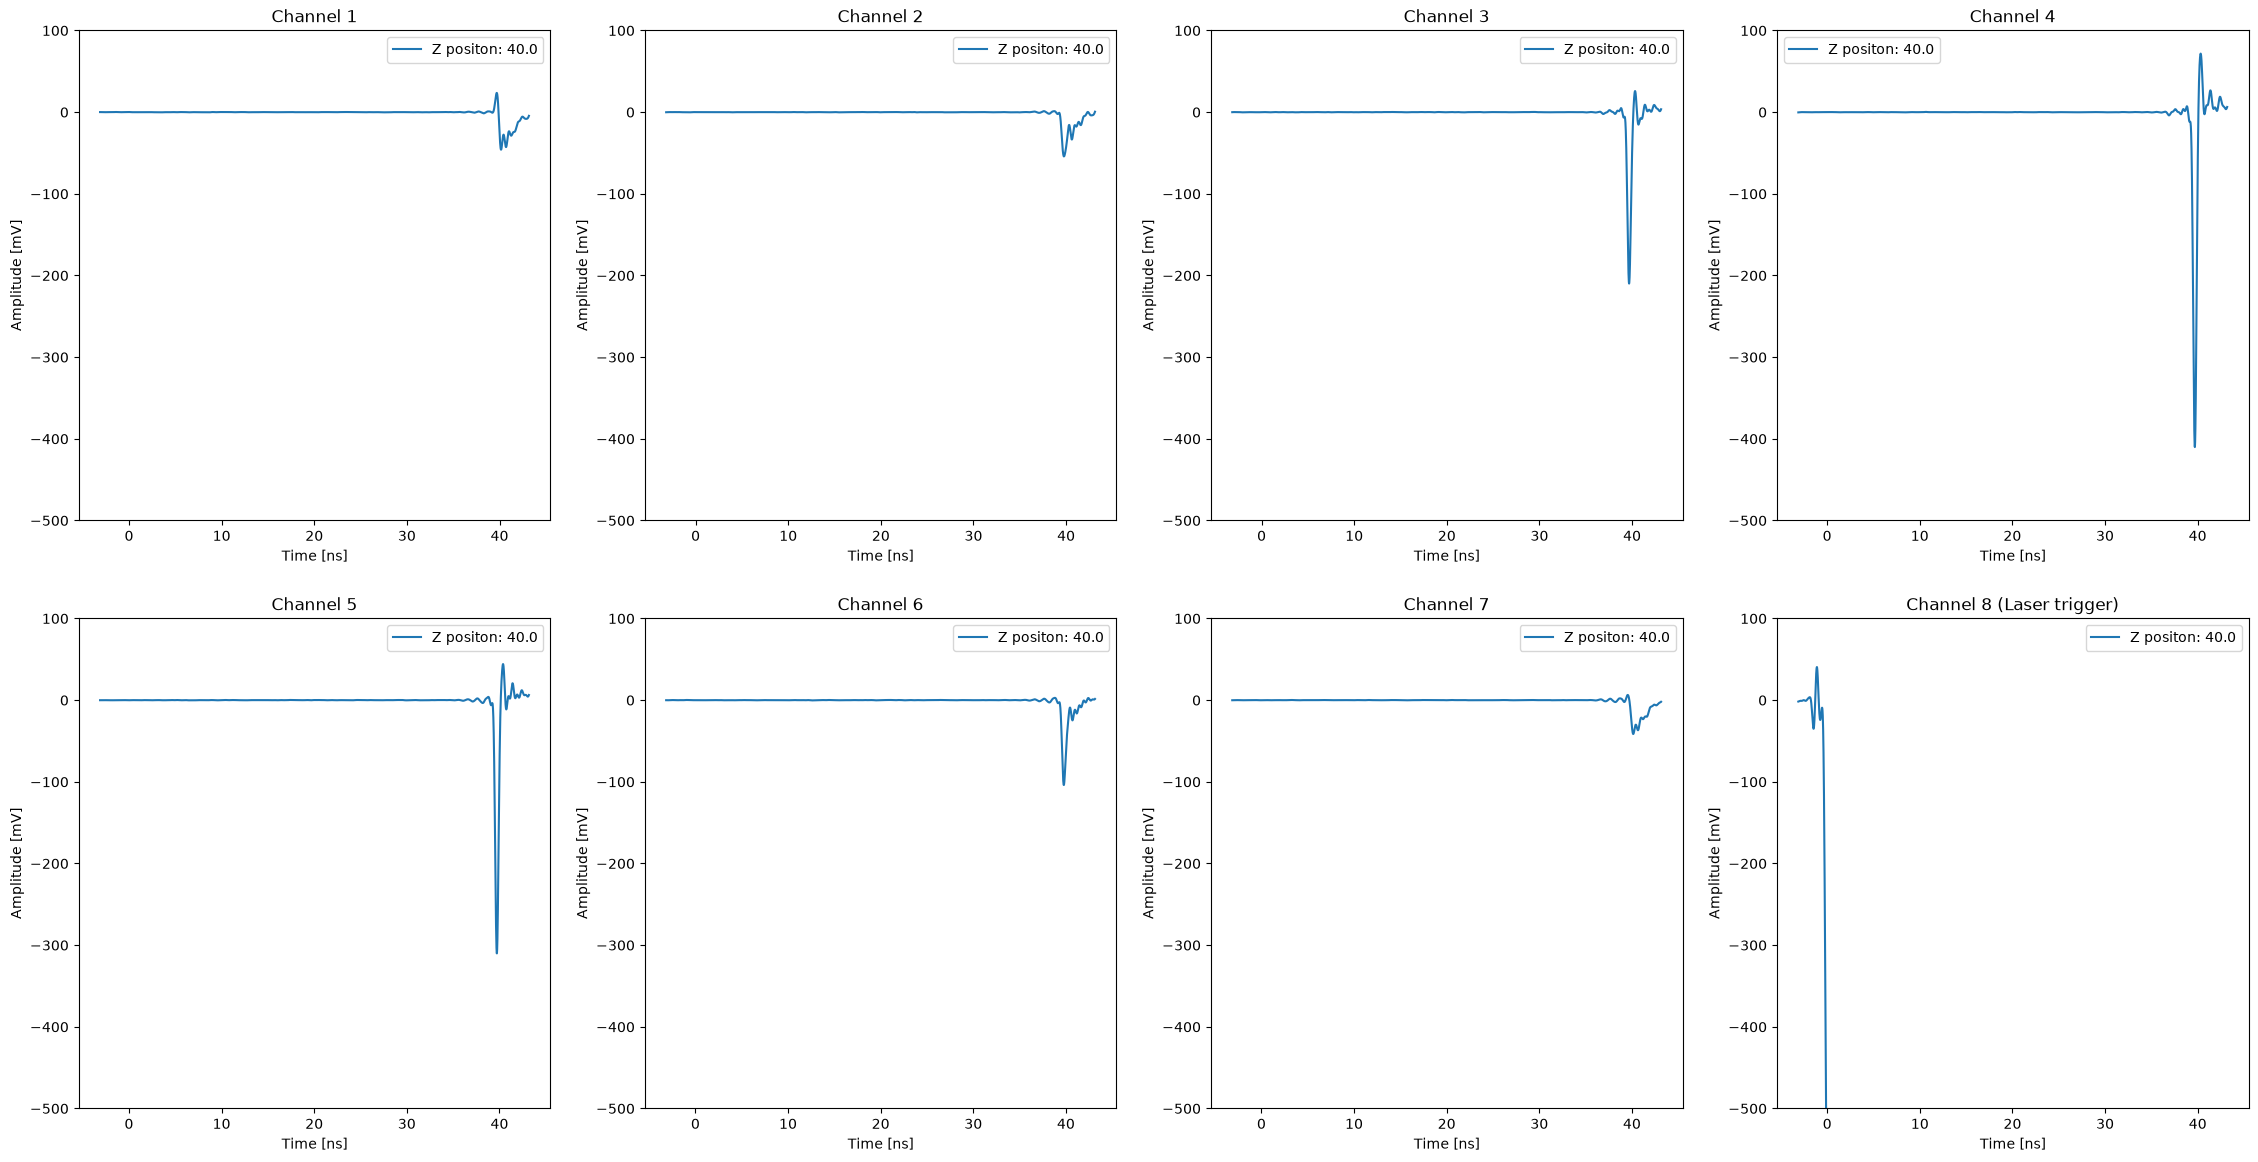





[[0.0703, 0.0665, 0.0634, 0.0604, 0.0579, ..., -6.01, -5.73, -5.43, -5.13], ...] 8


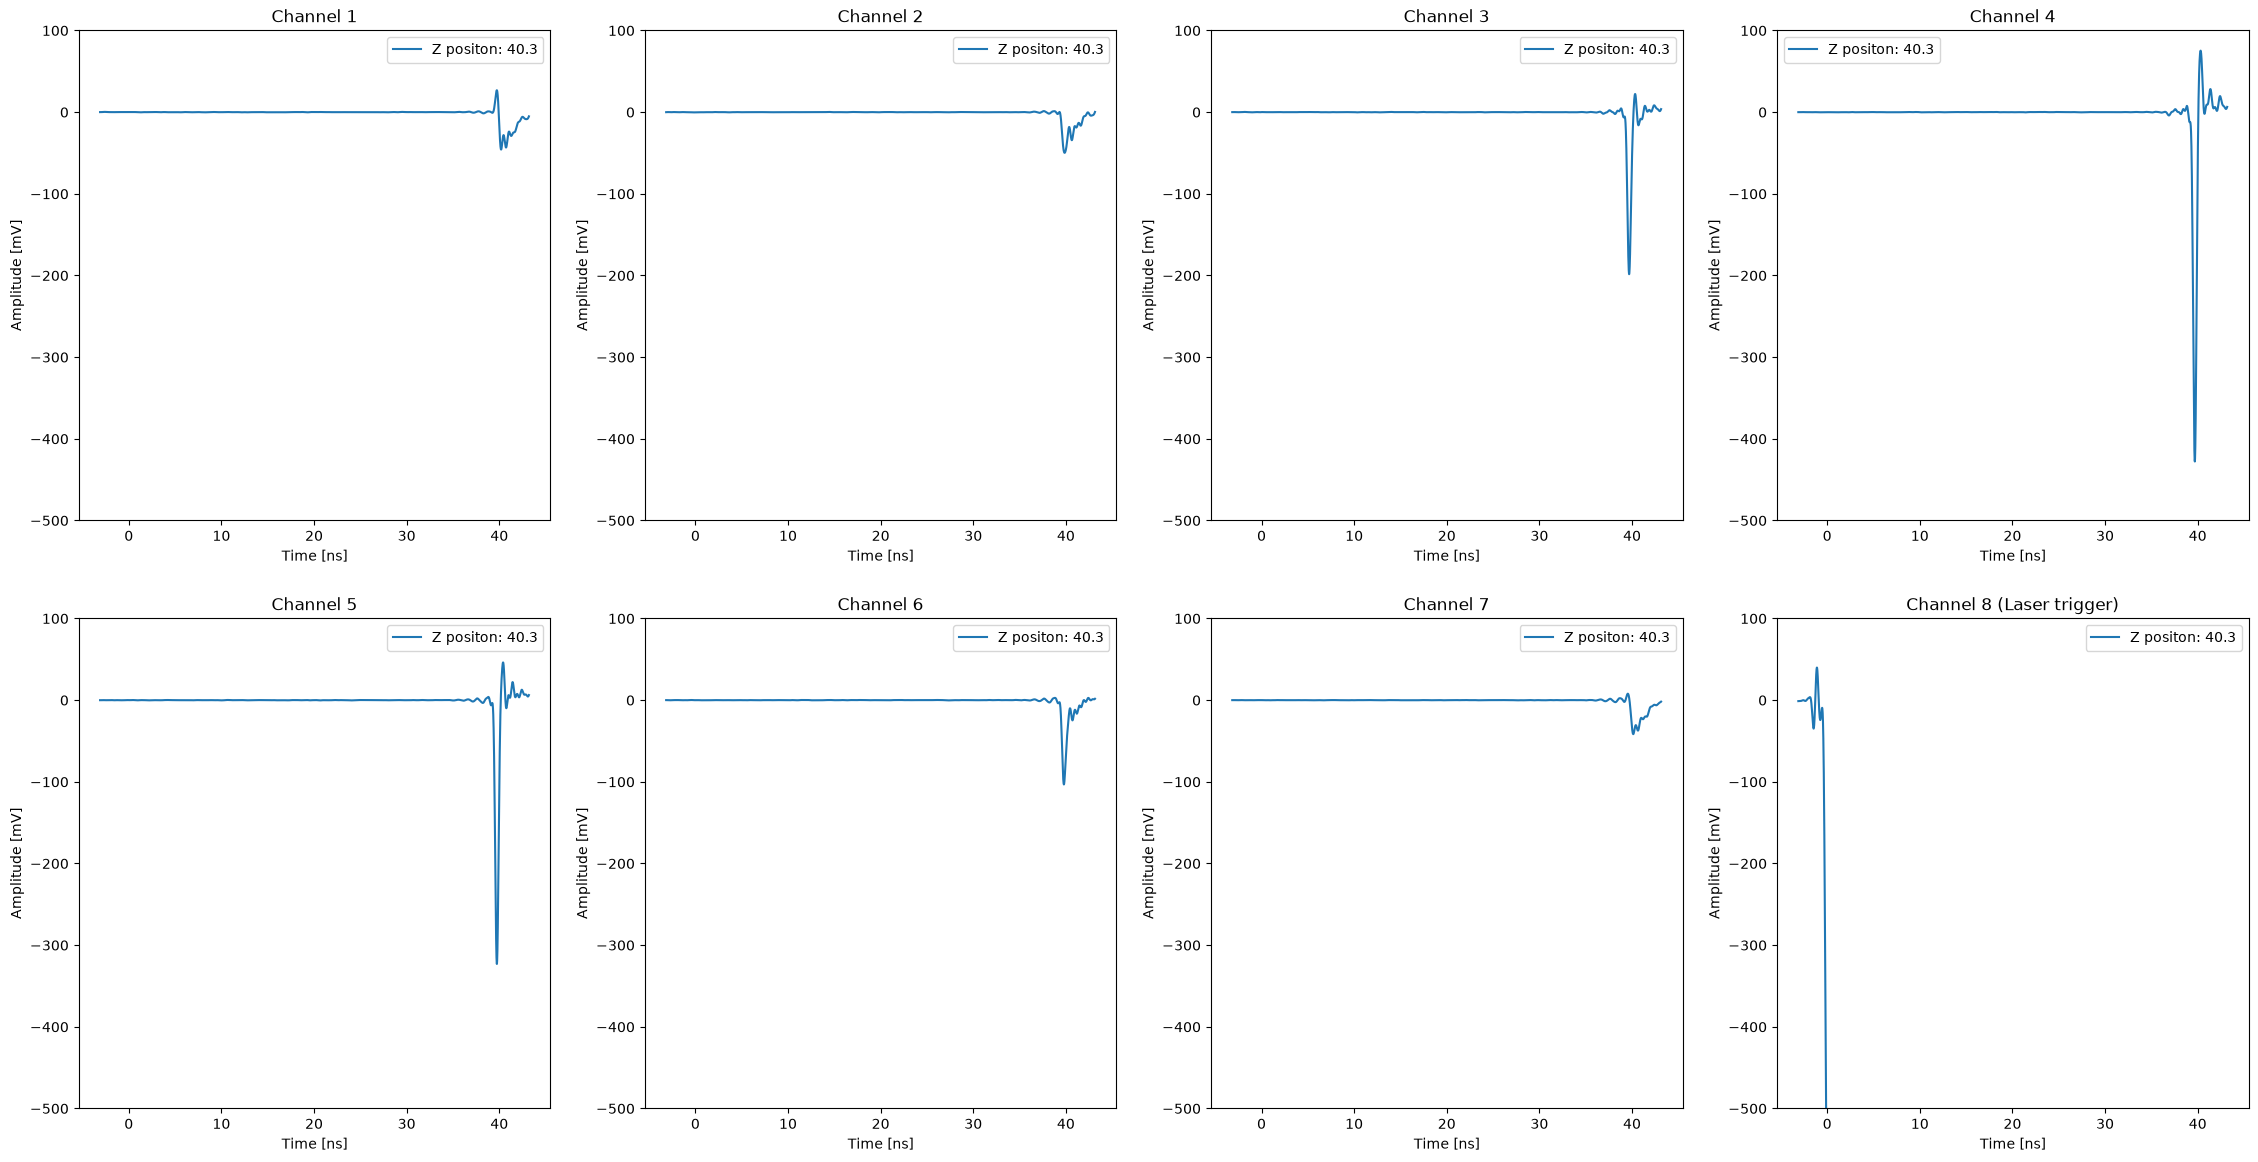





[[-0.114, -0.11, -0.107, -0.103, -0.0983, ..., -5.83, -5.55, -5.26, -4.96], ...] 8


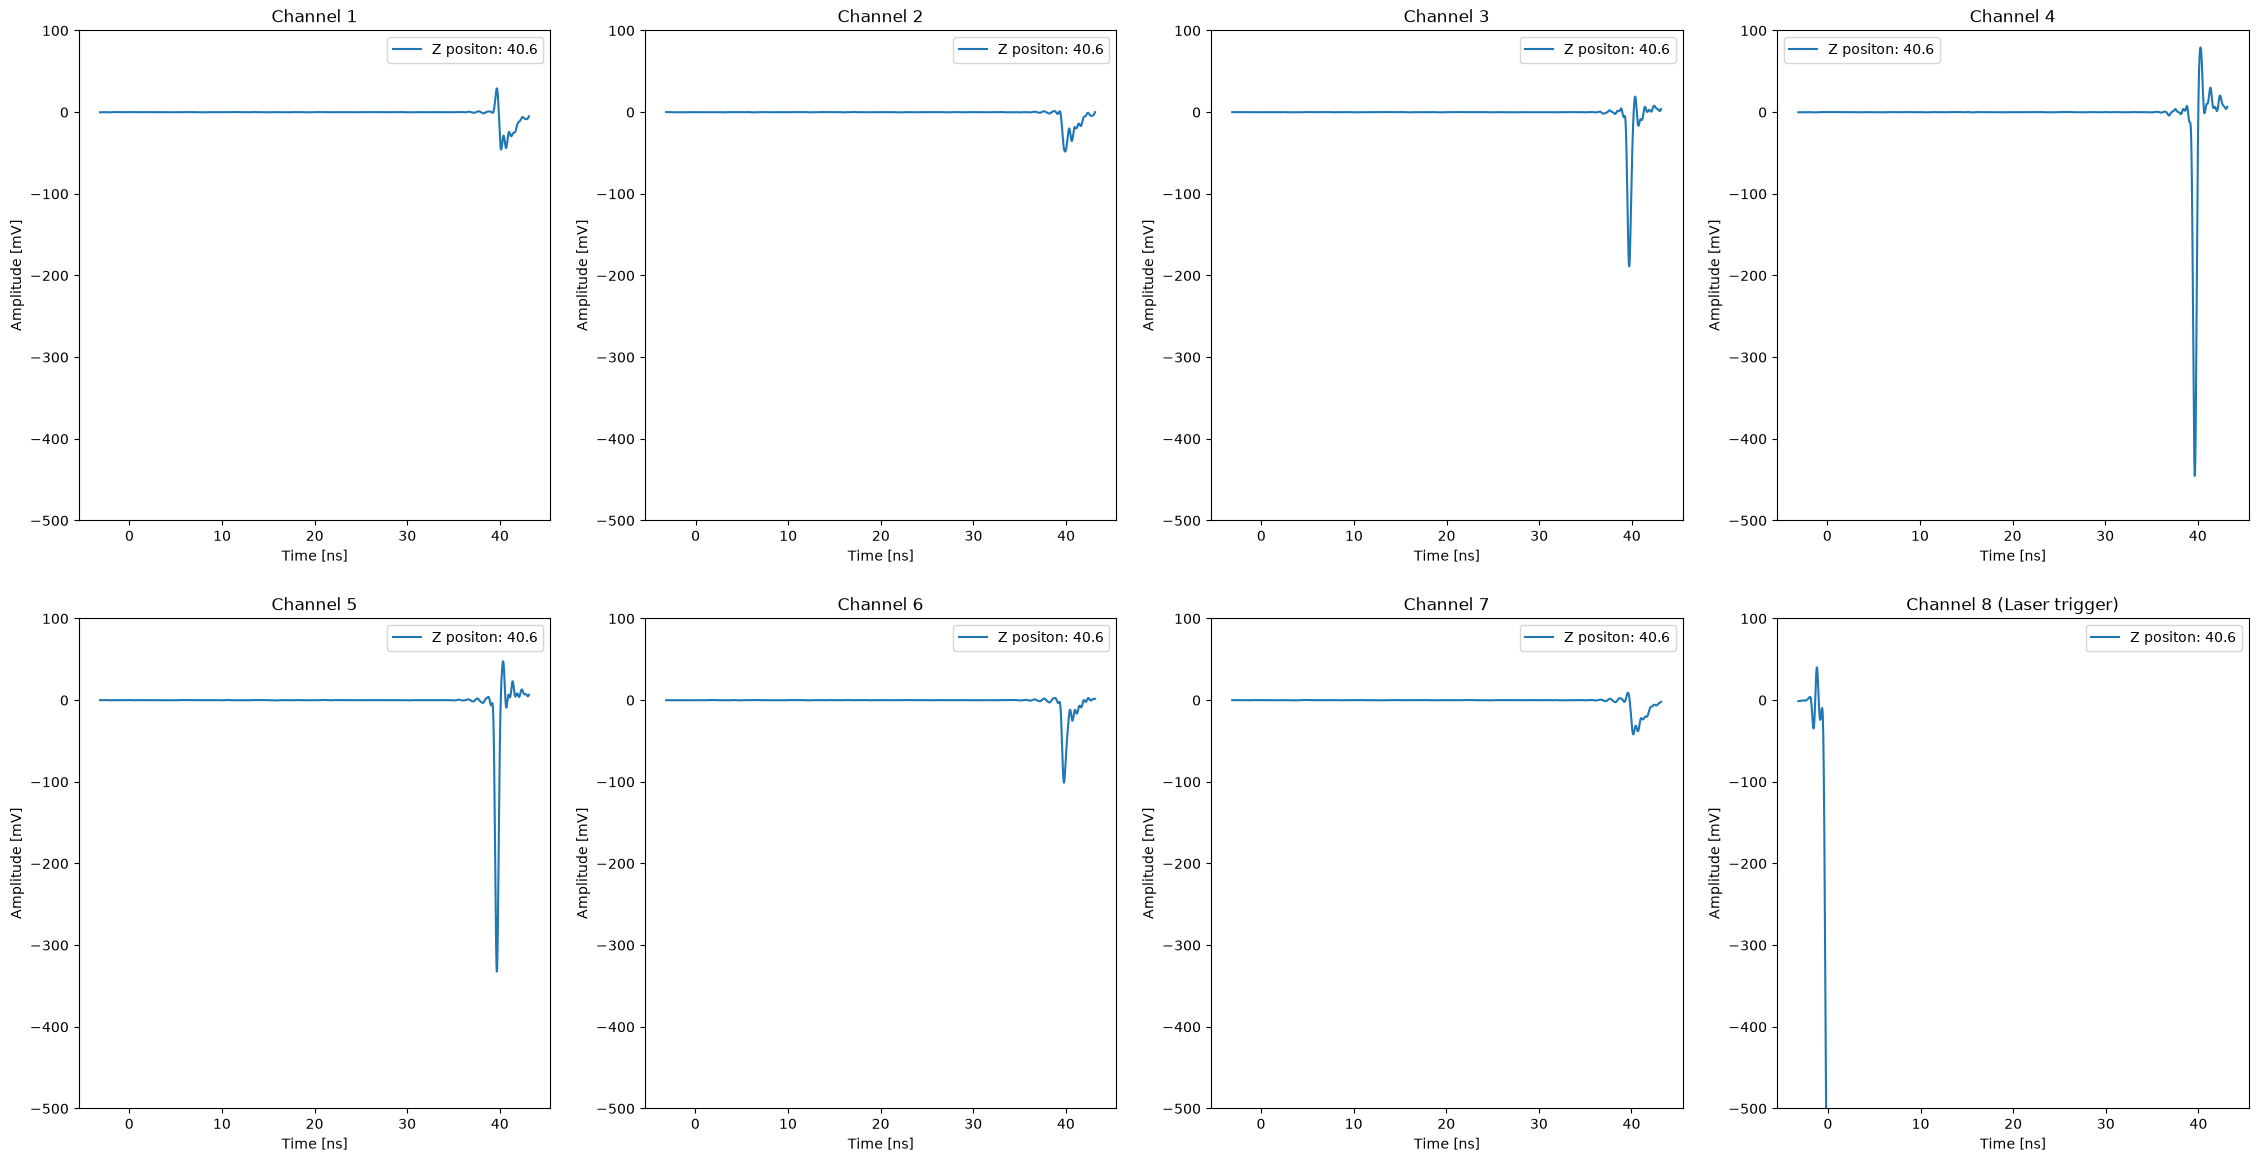





[[-0.137, -0.137, -0.137, -0.137, -0.137, ..., -6.16, -5.88, -5.6, -5.3], ...] 8


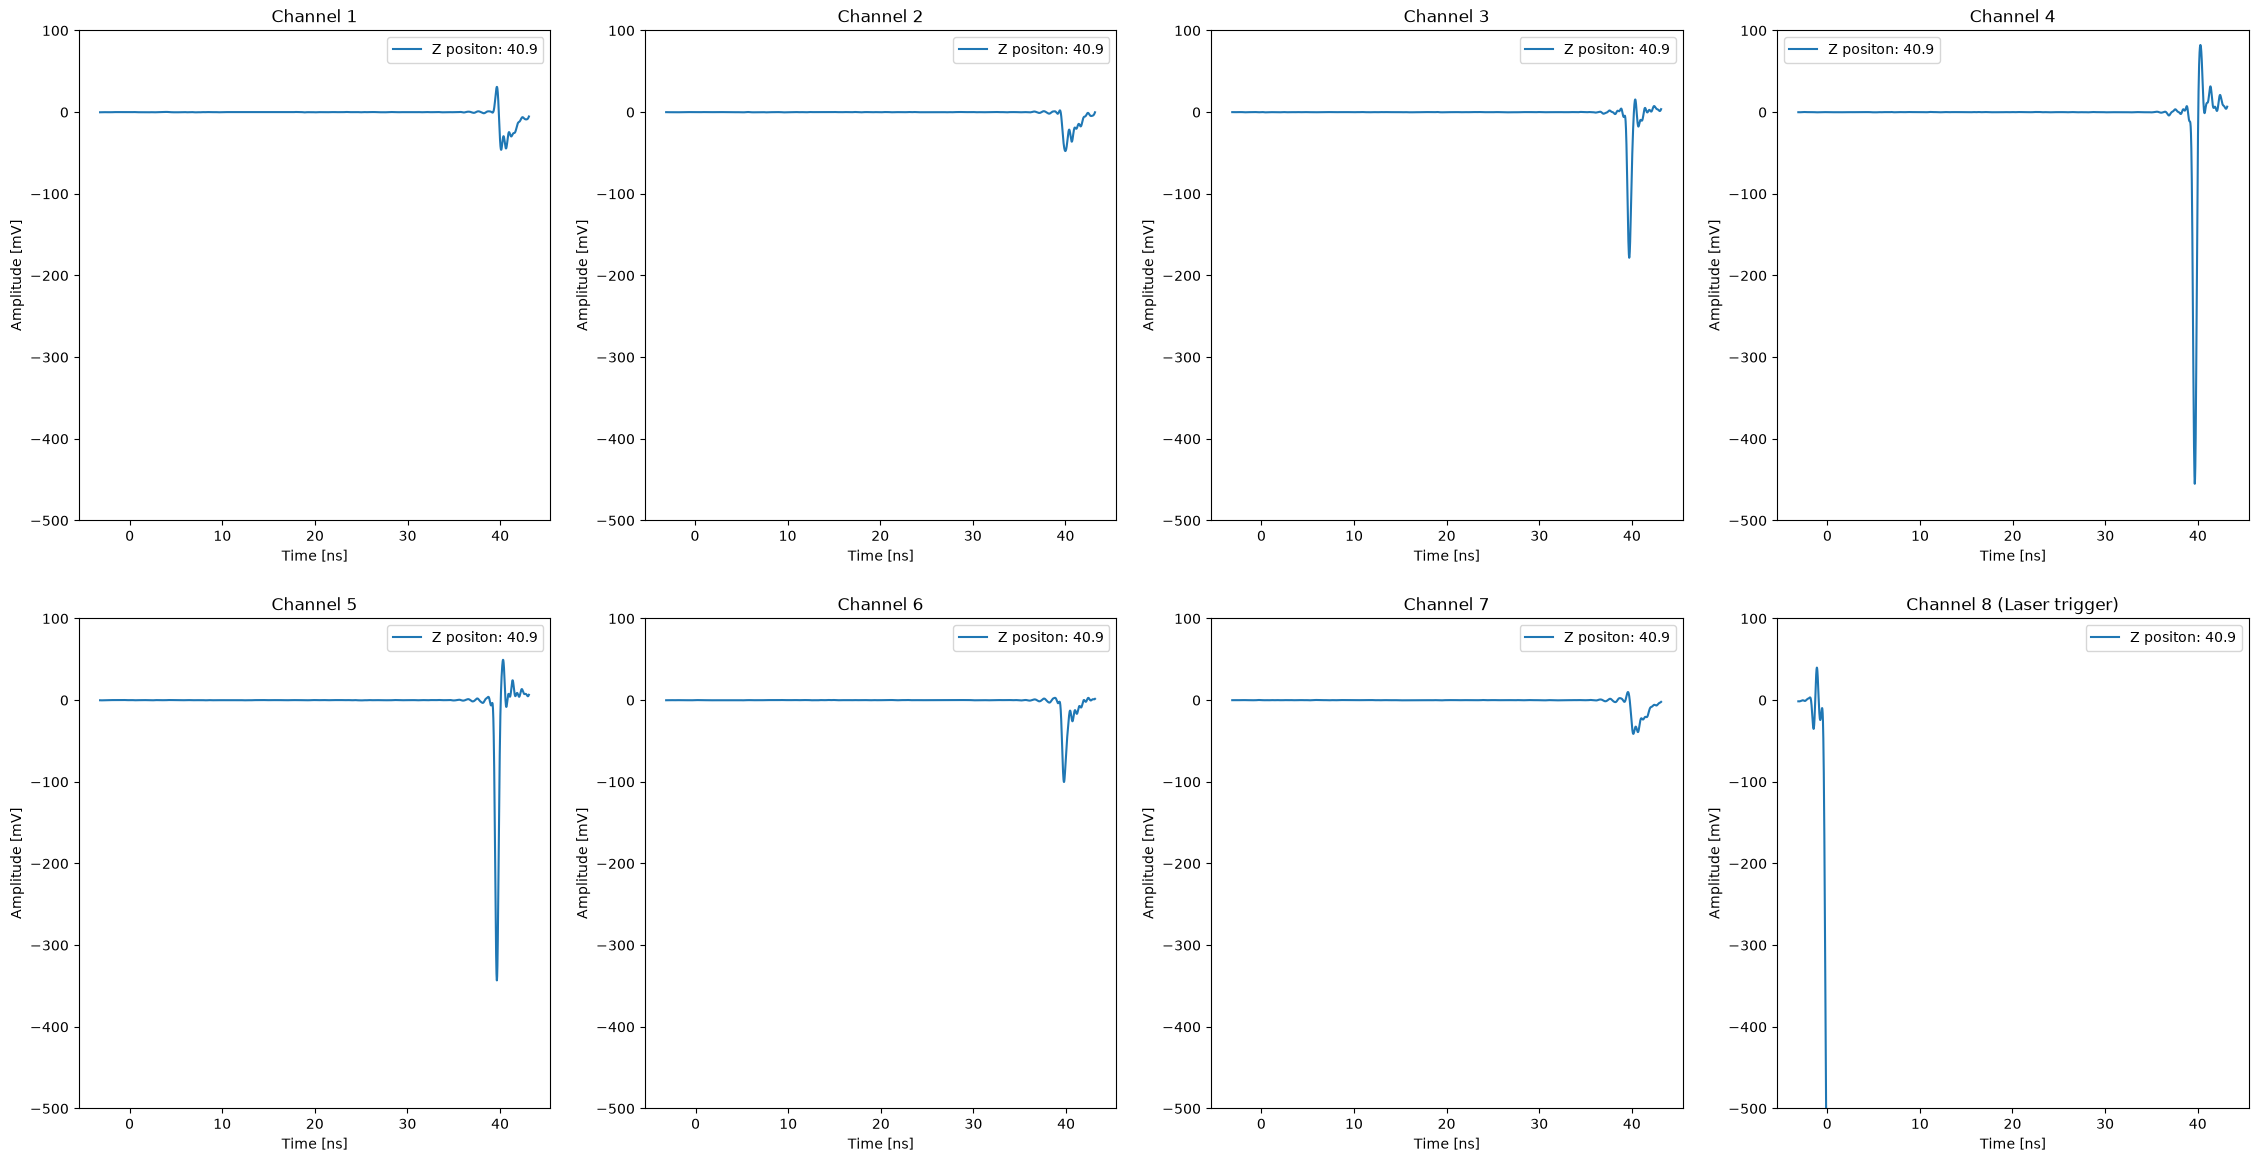





[[-0.0854, -0.0856, -0.0858, -0.0851, ..., -6.43, -6.15, -5.87, -5.57], ...] 8


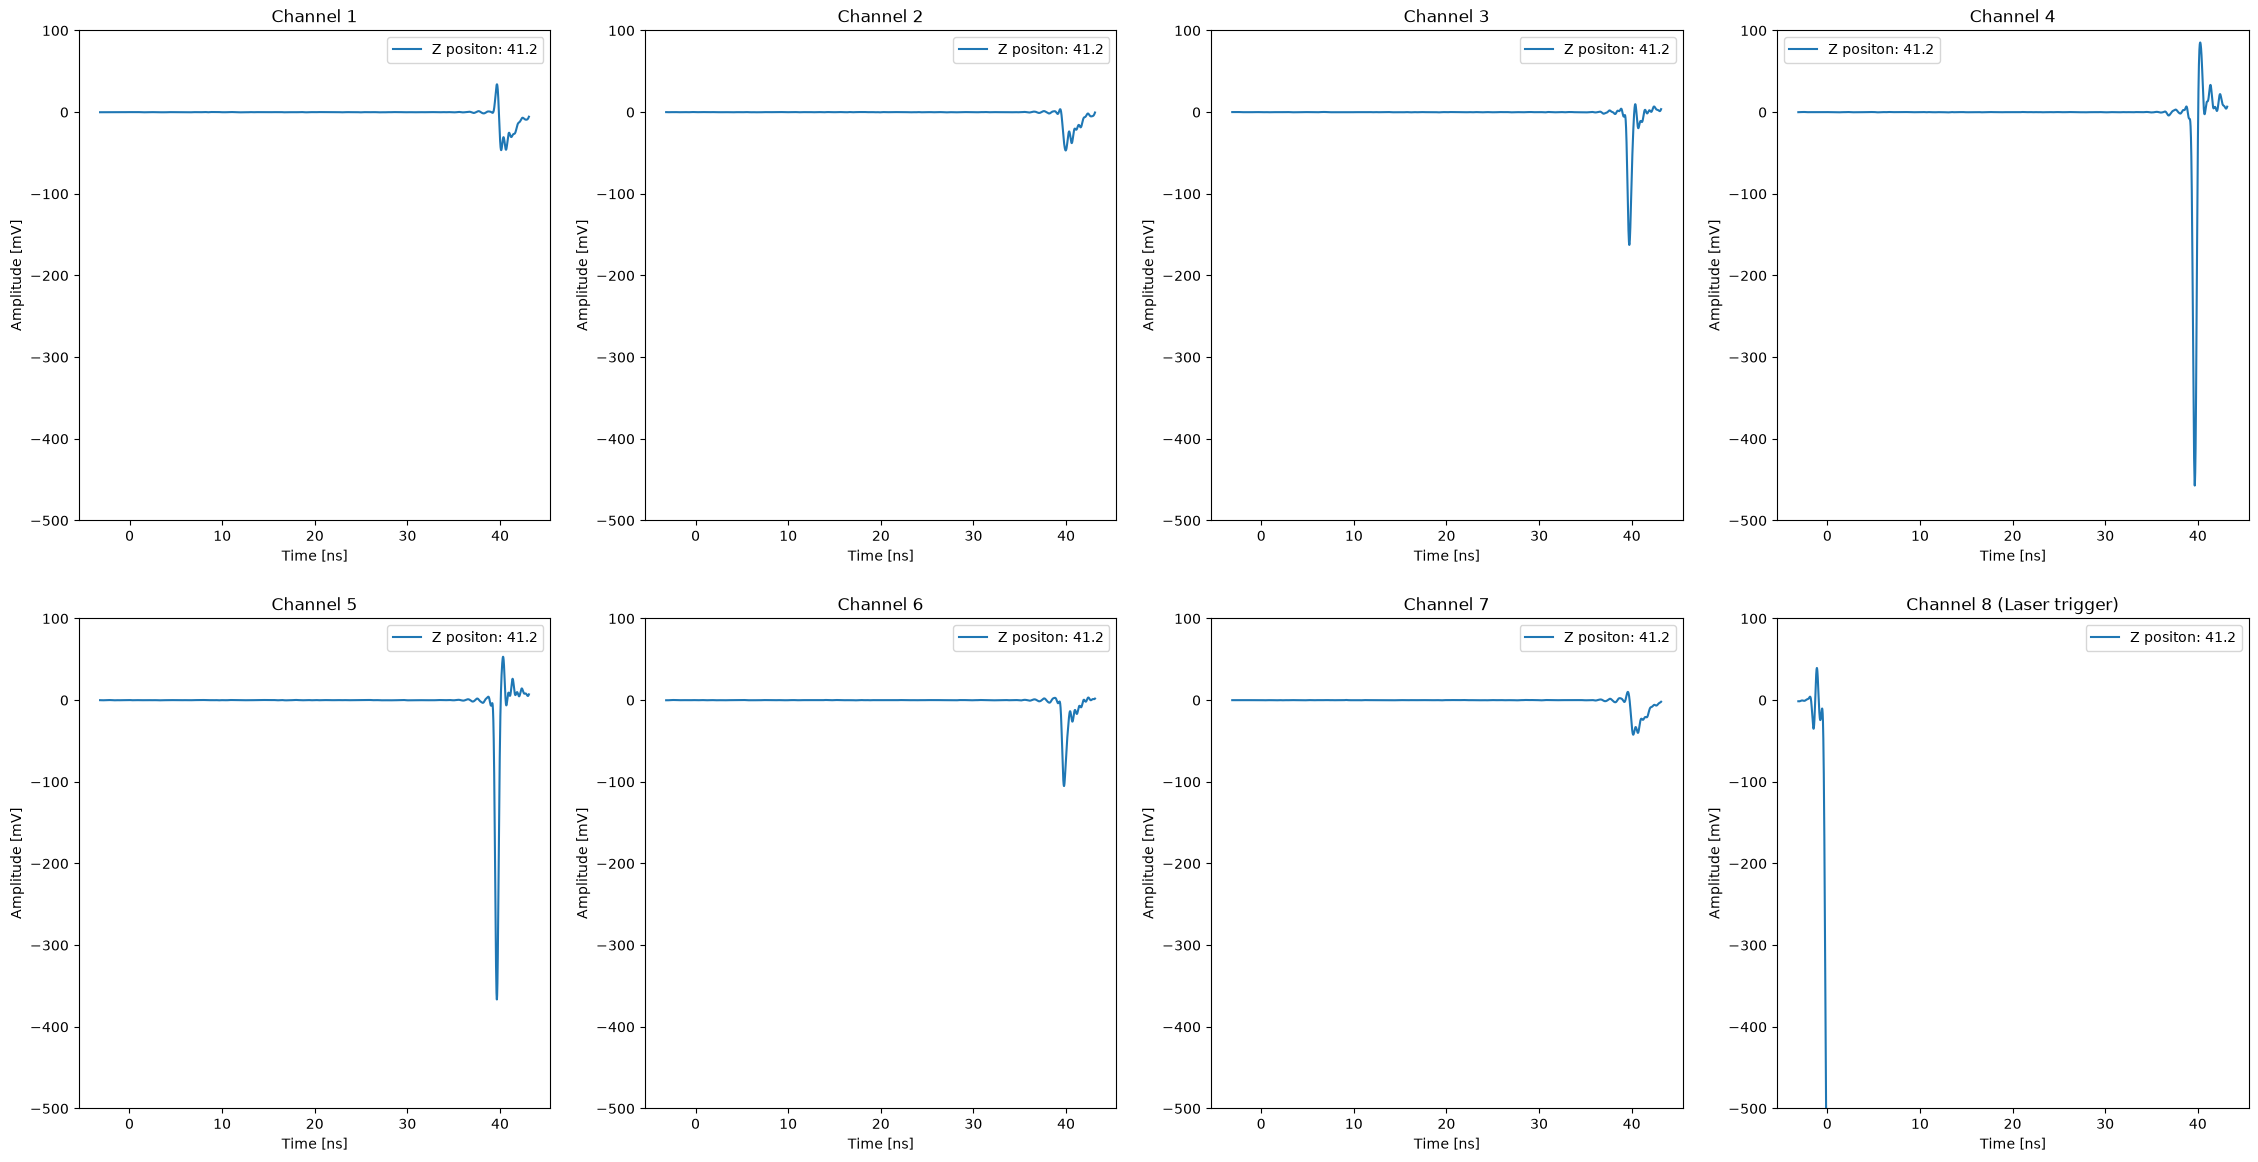





[[0.0804, 0.08, 0.0799, 0.0798, 0.0794, ..., -6.75, -6.47, -6.17, -5.85], ...] 8


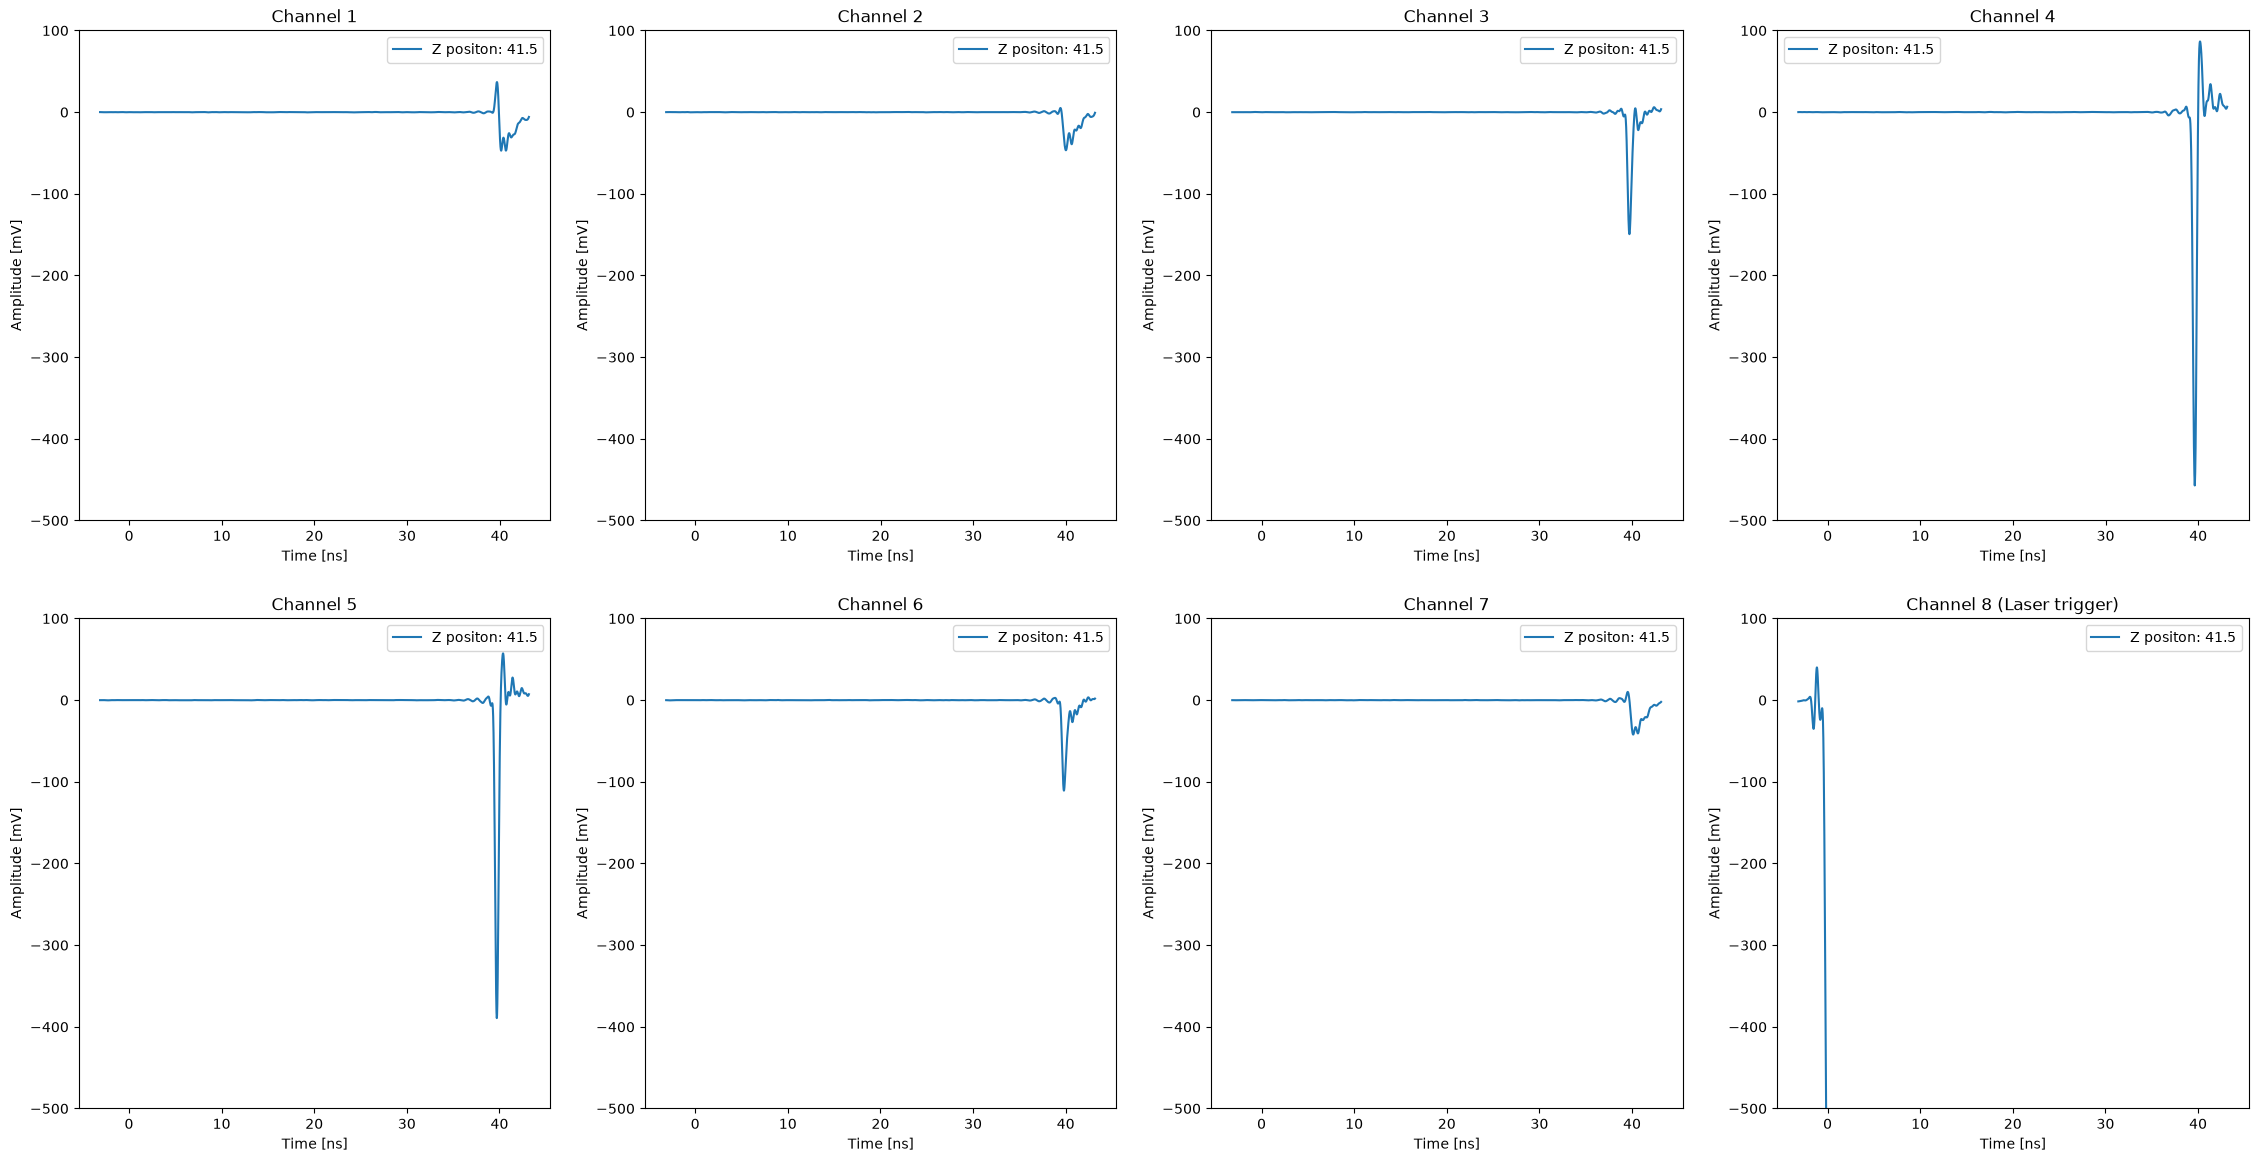





[[-0.215, -0.216, -0.215, -0.214, -0.211, ..., -6.62, -6.34, -6.05, -5.75], ...] 8


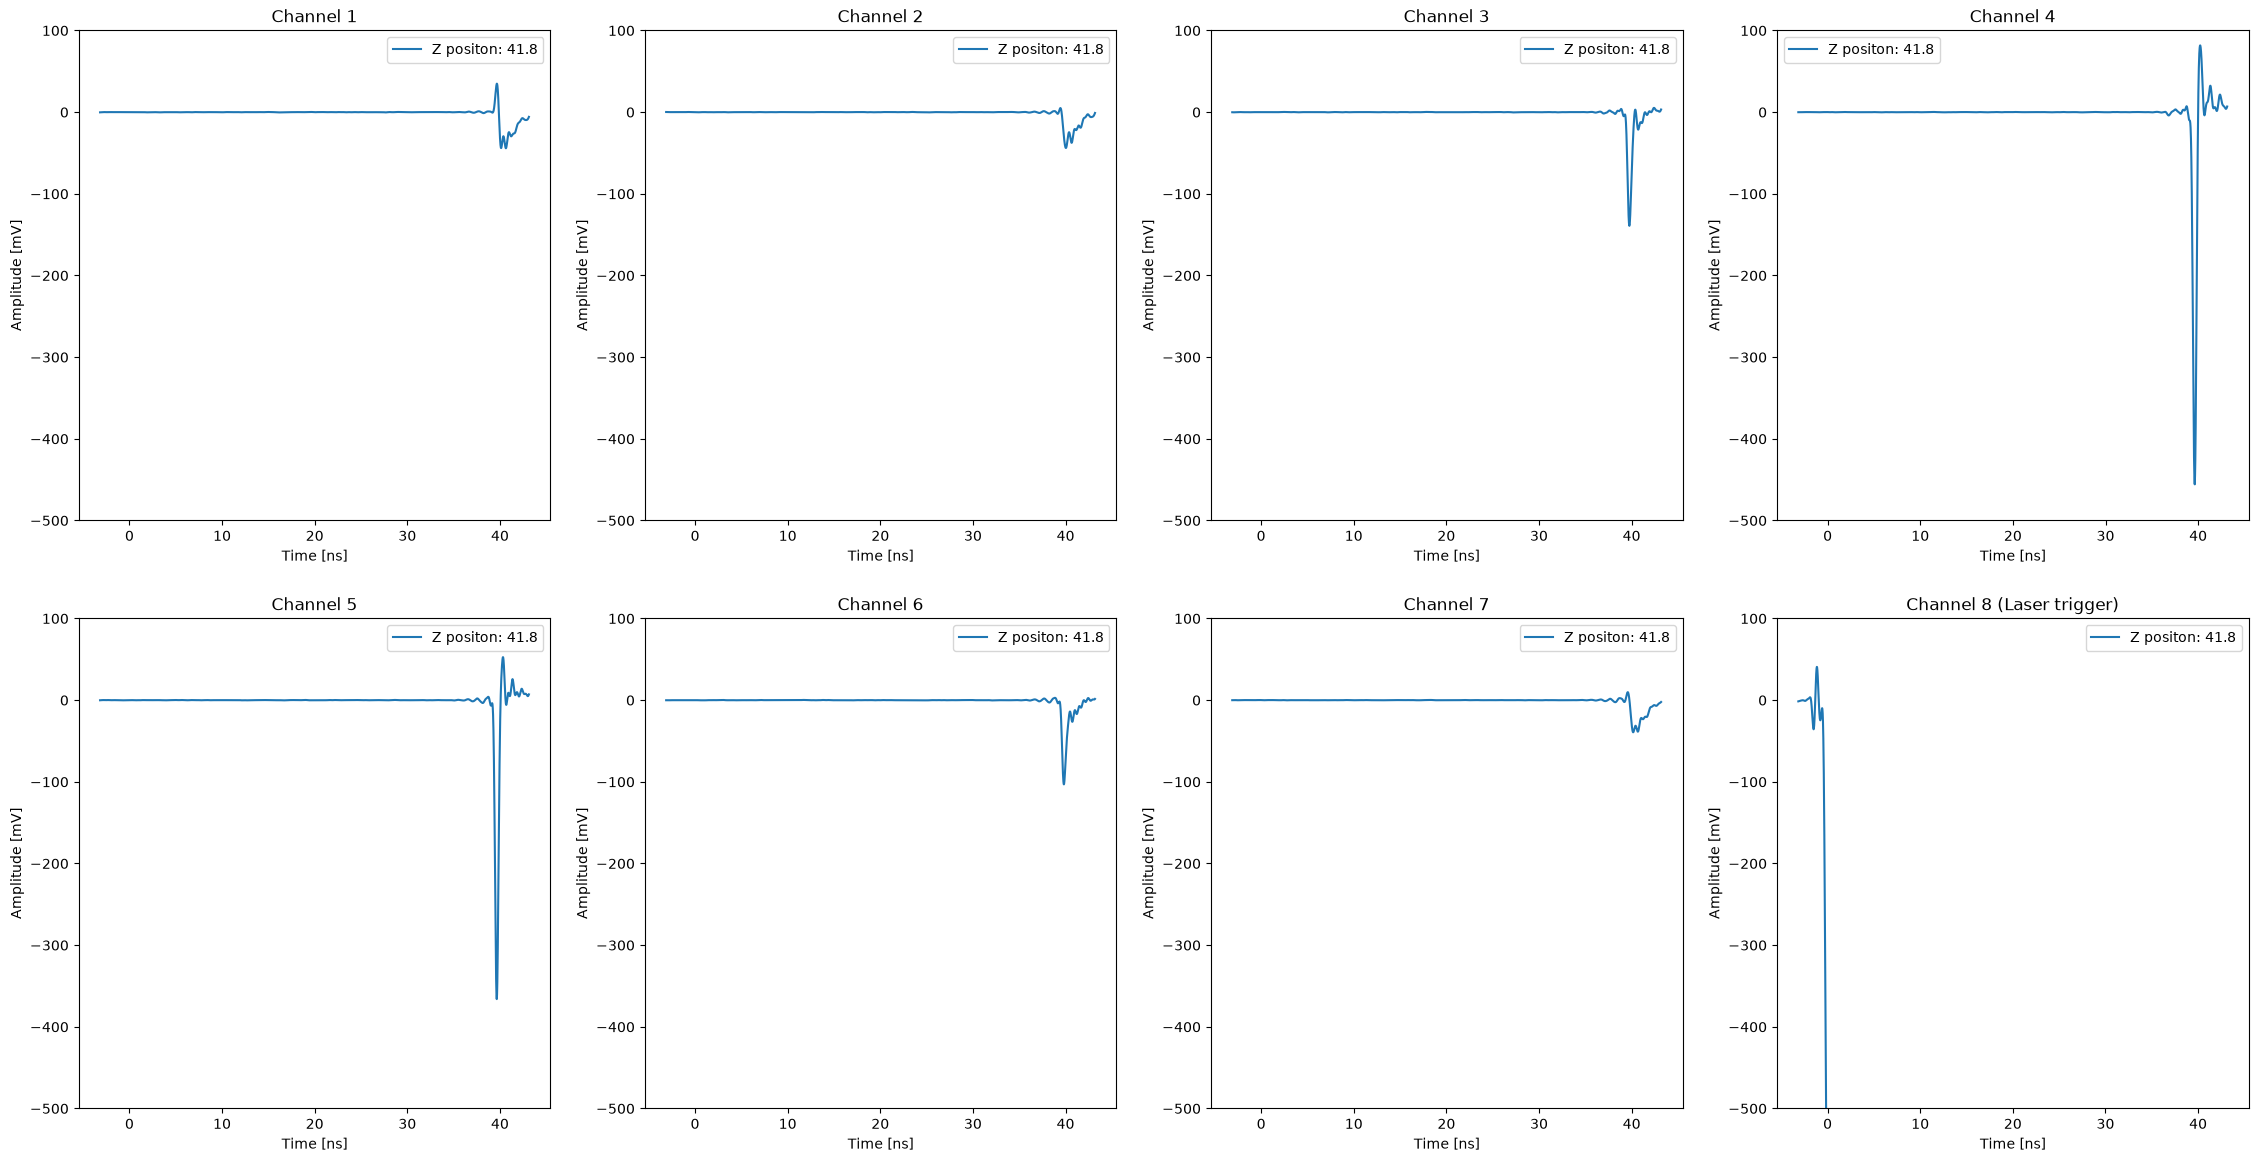





[[0.0666, 0.0657, 0.0648, 0.0642, 0.0646, ..., -5.41, -5.2, -4.97, -4.74], ...] 8


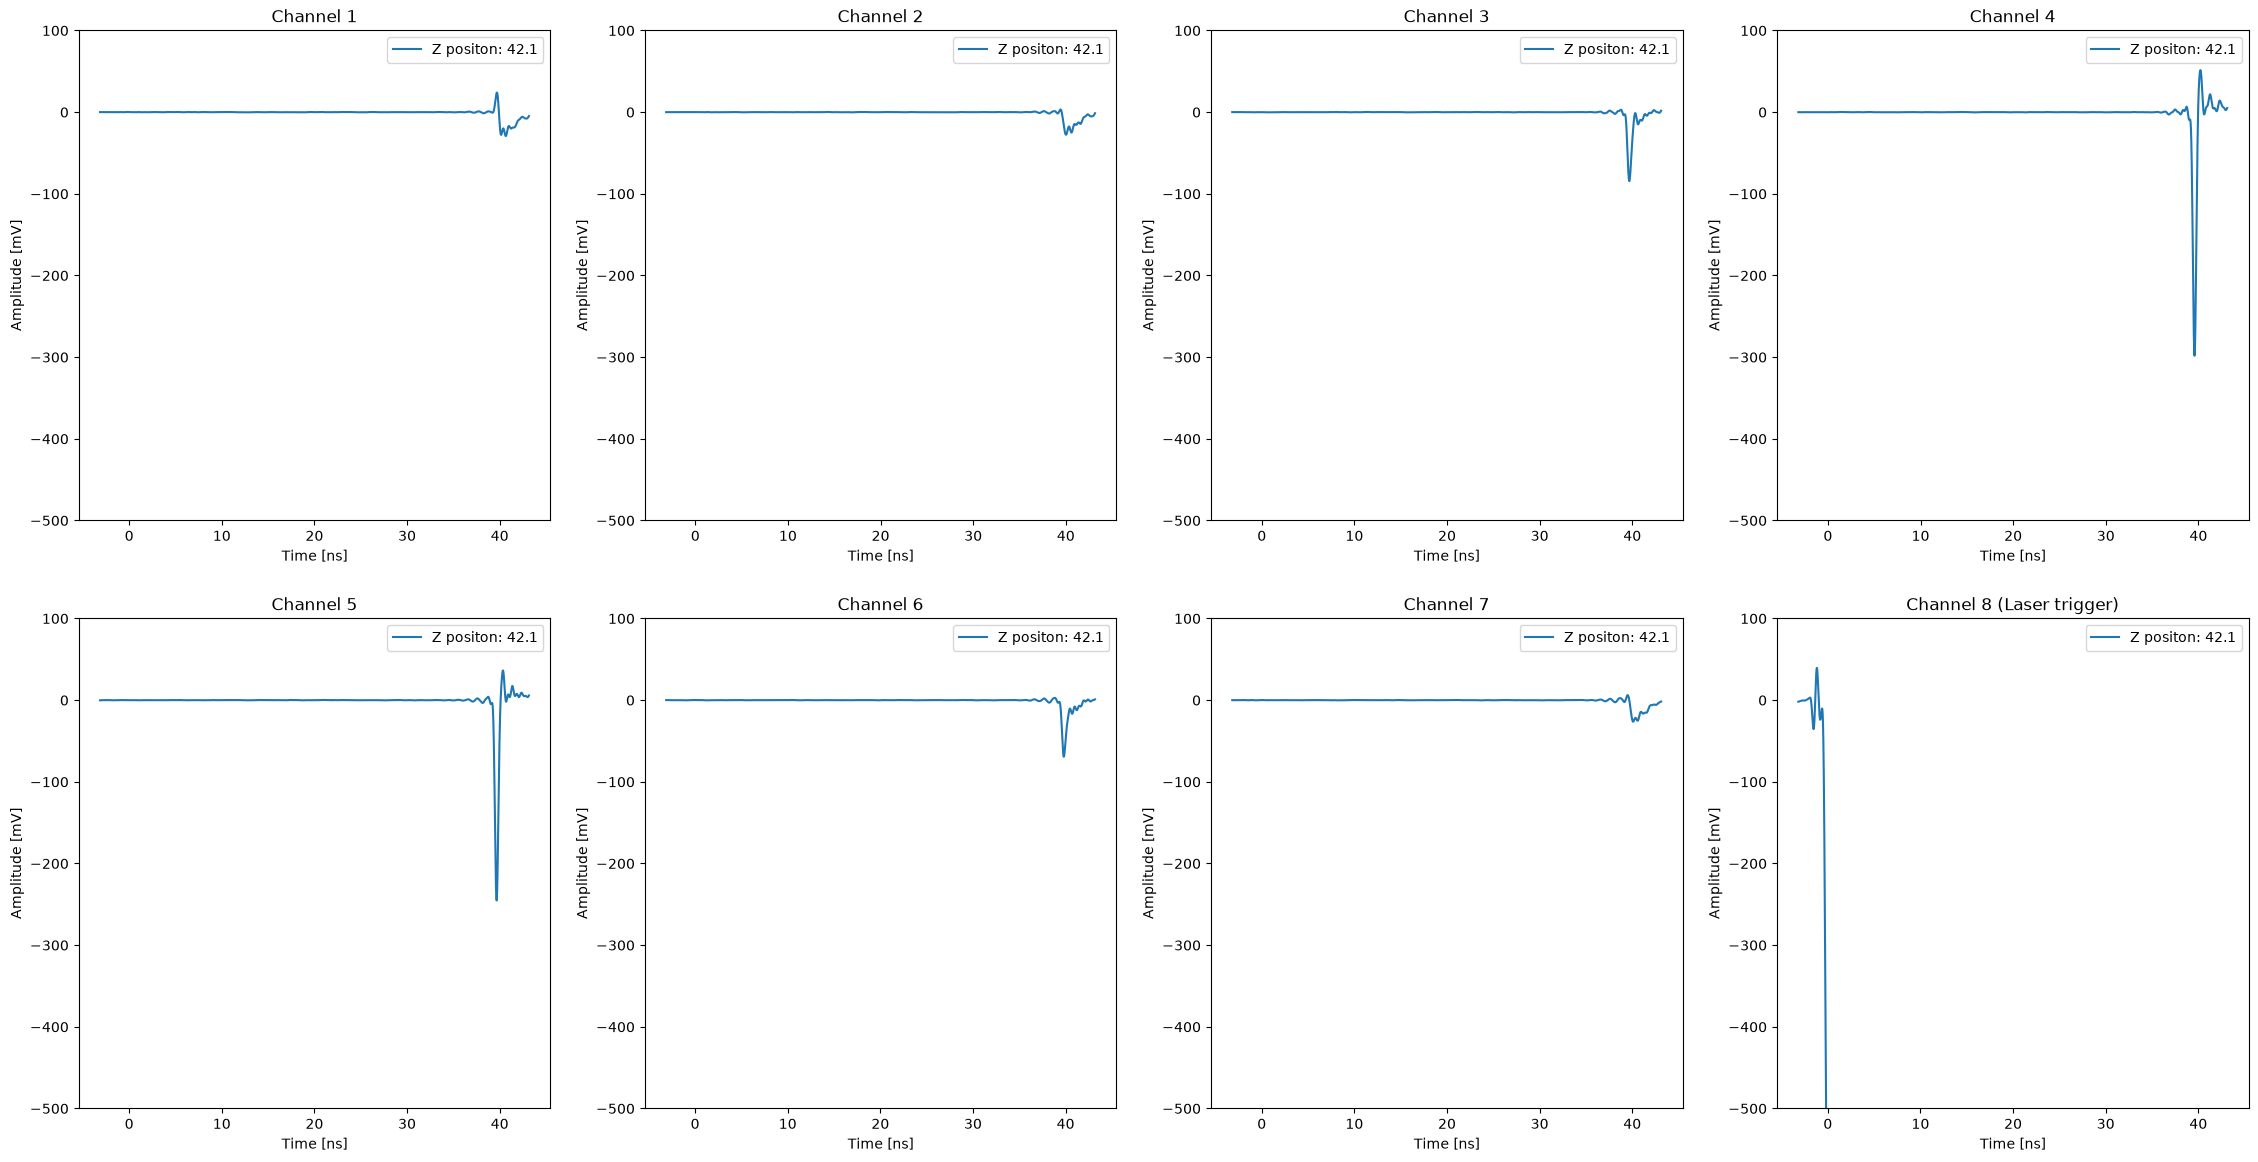





[[0.0139, 0.0144, 0.014, 0.0135, 0.0121, ..., -6.69, -6.47, -6.23, -5.99], ...] 8


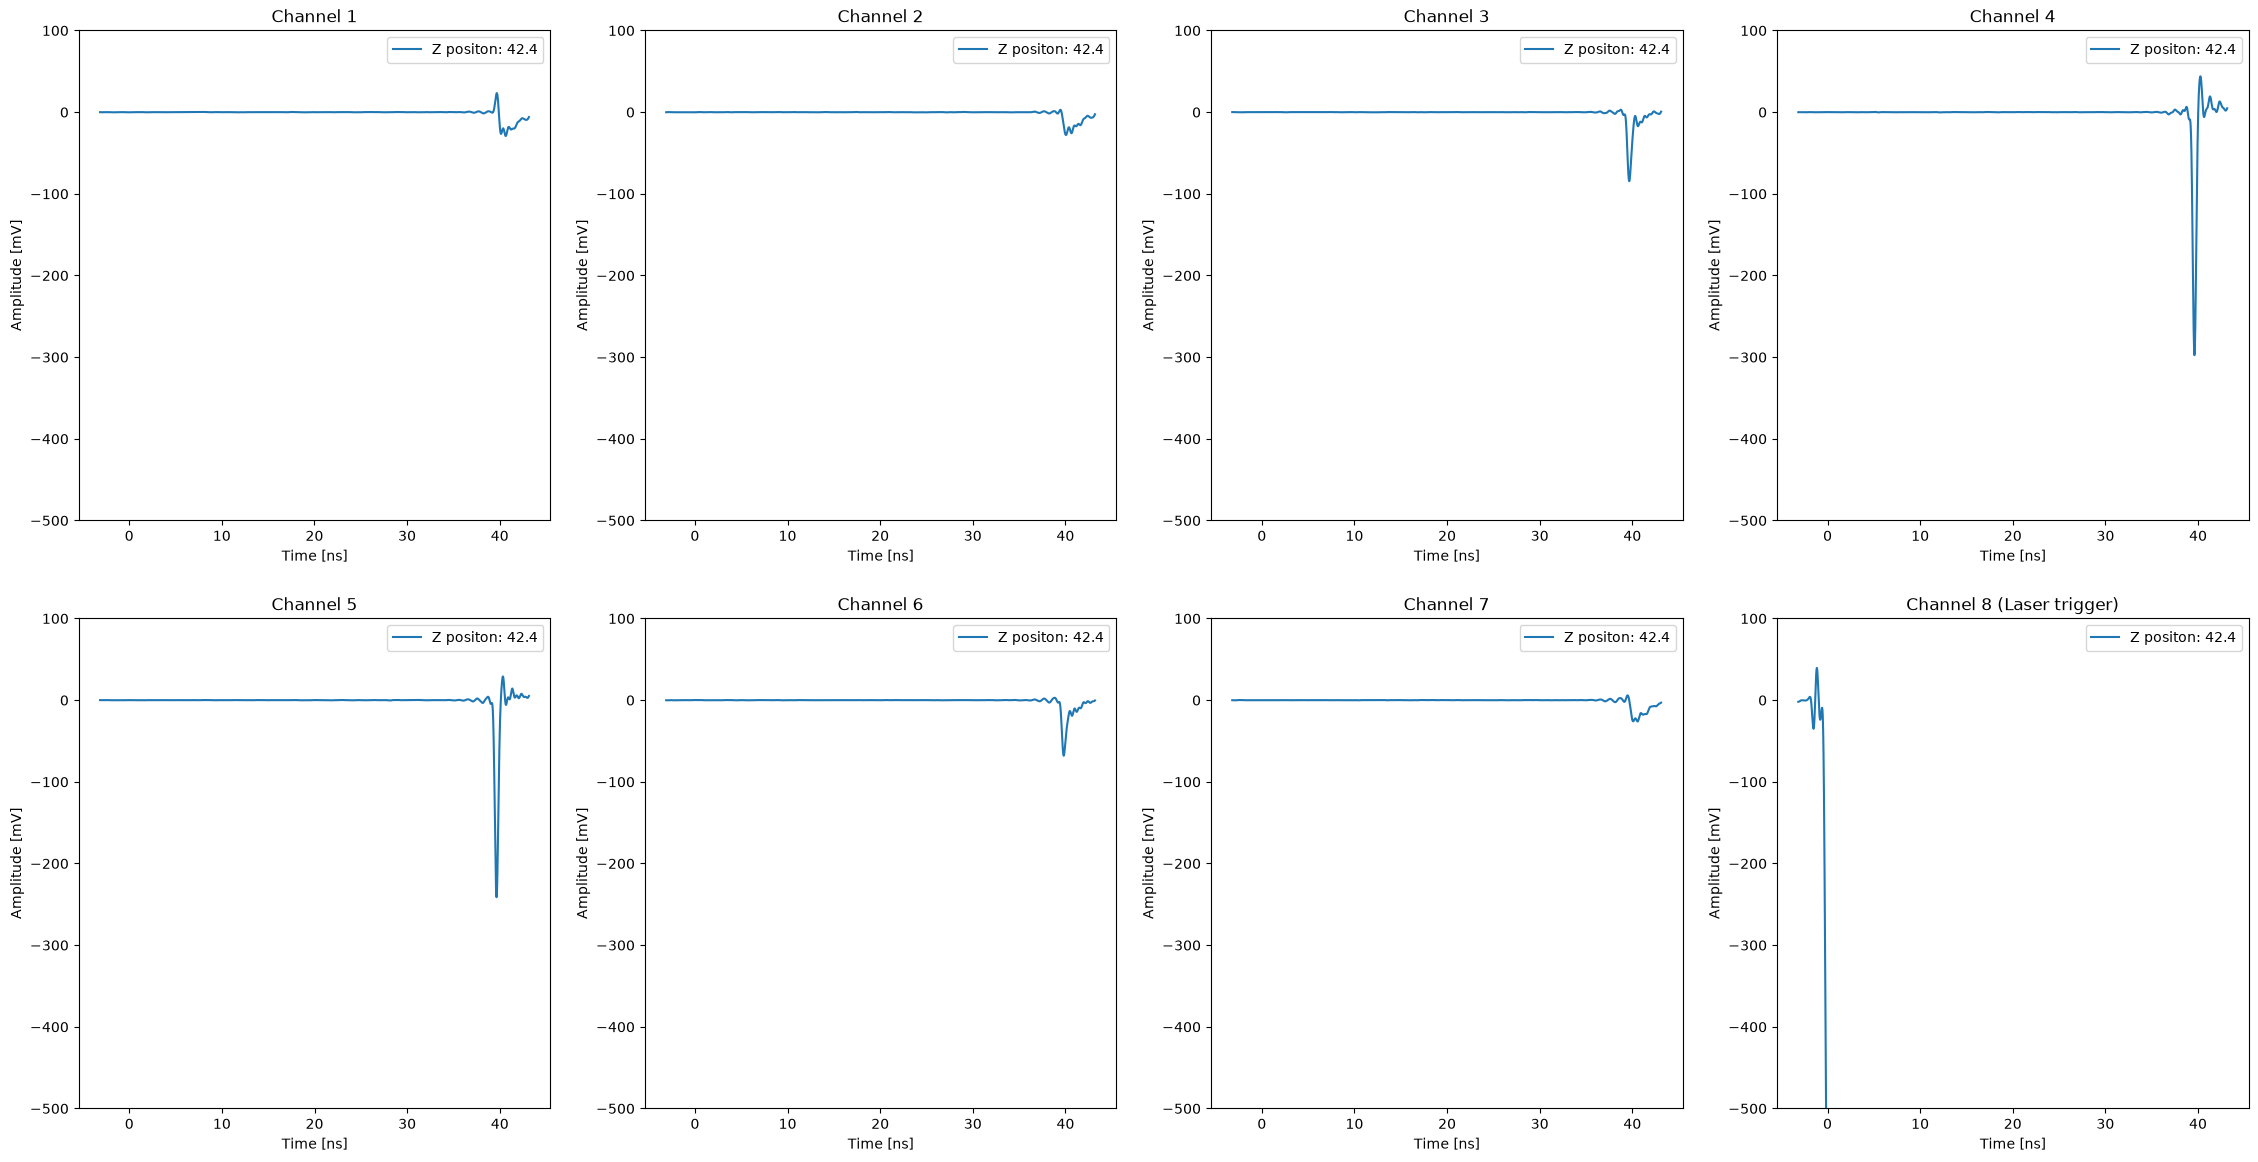





[[-0.00826, -0.0157, -0.0224, -0.0289, ..., -6.83, -6.57, -6.29, -6.01], ...] 8


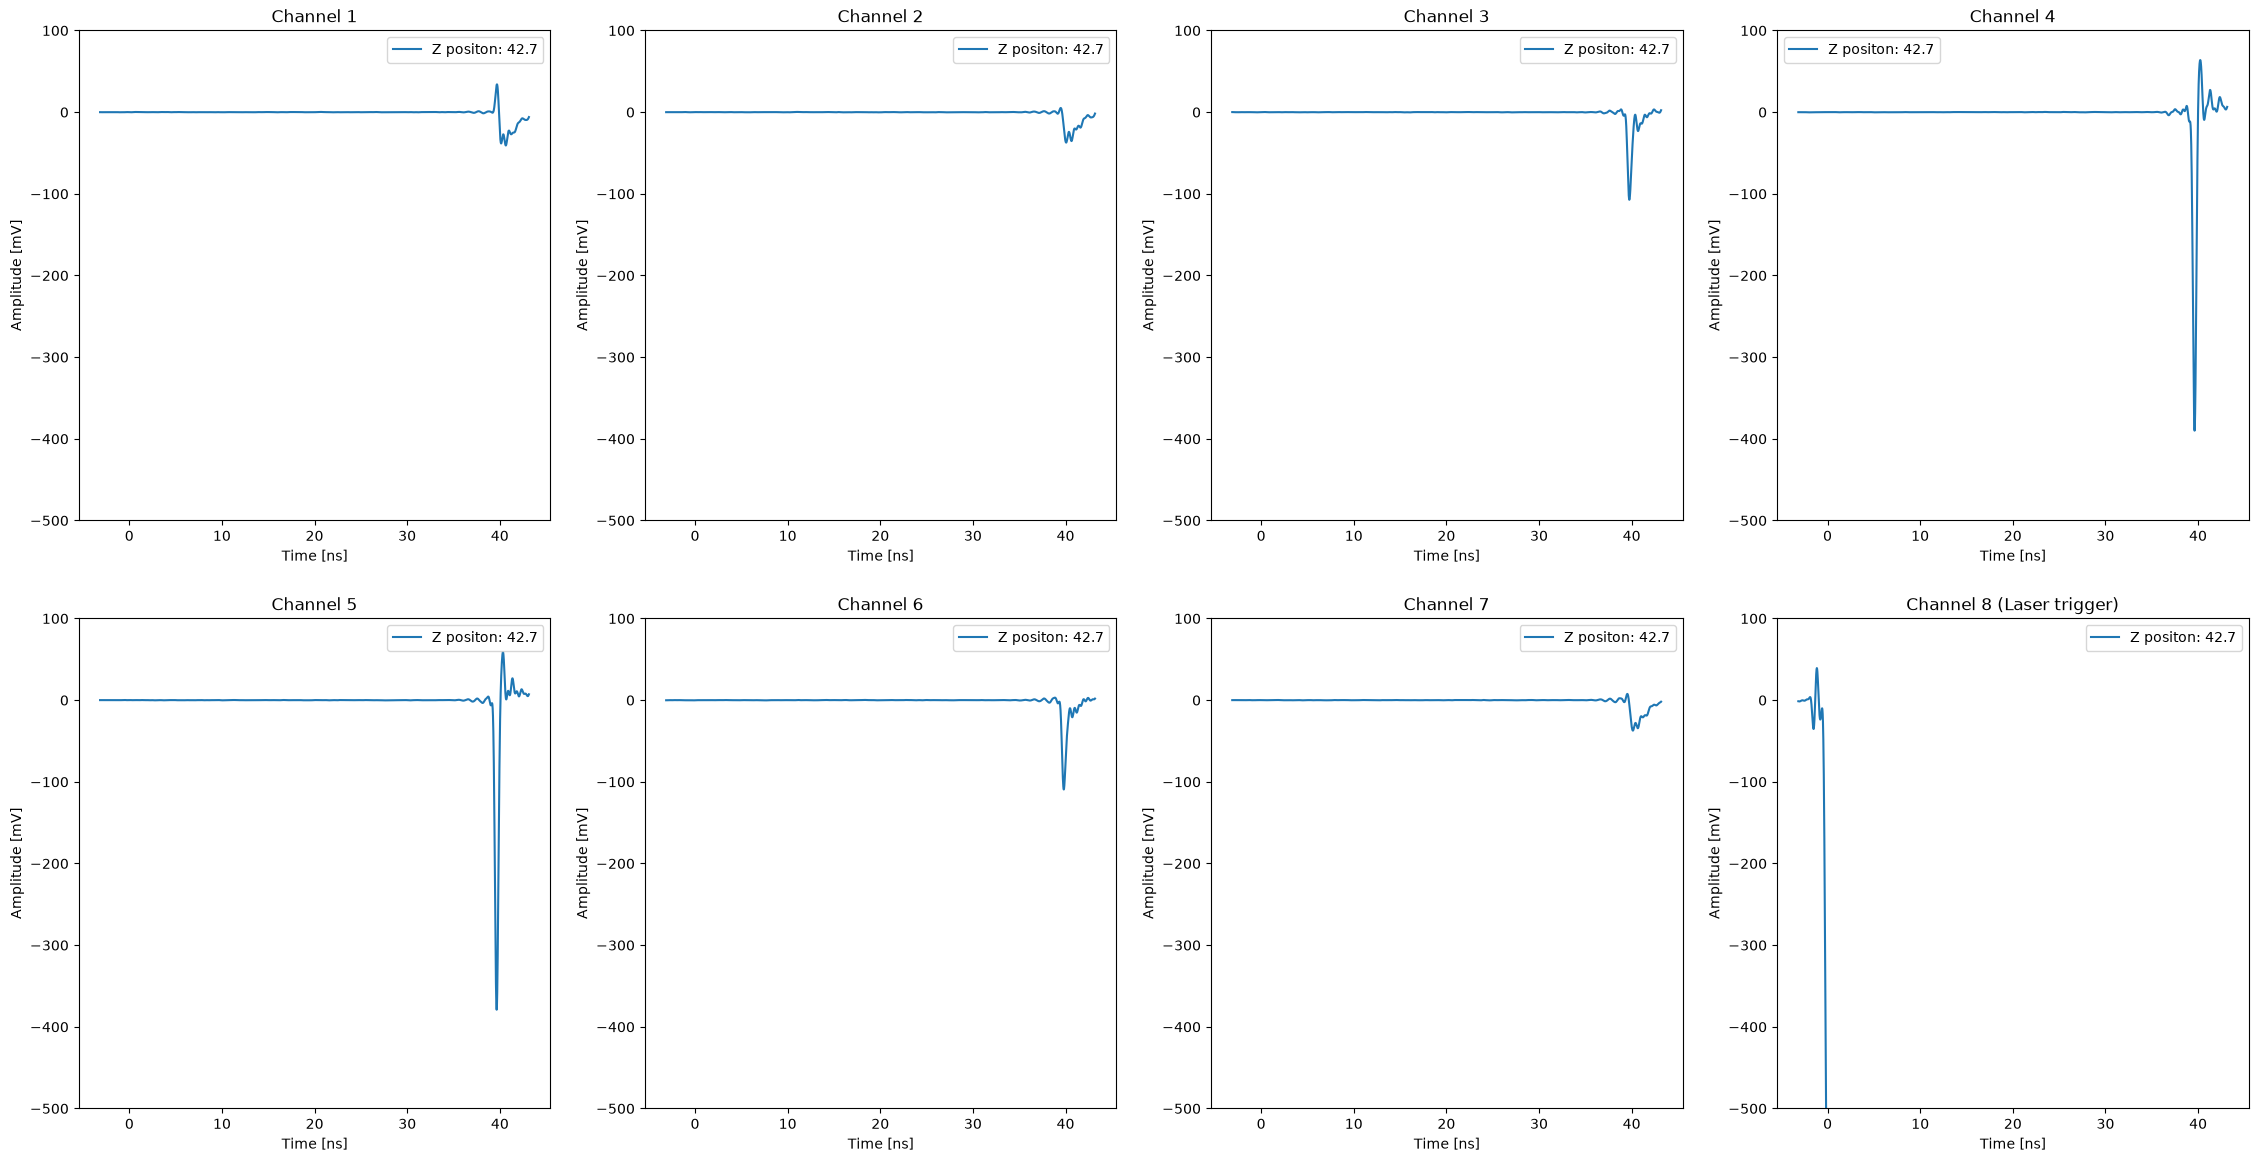





[[0.176, 0.178, 0.181, 0.184, 0.185, ..., -5.6, -5.38, -5.14, -4.9, -4.65], ...] 8


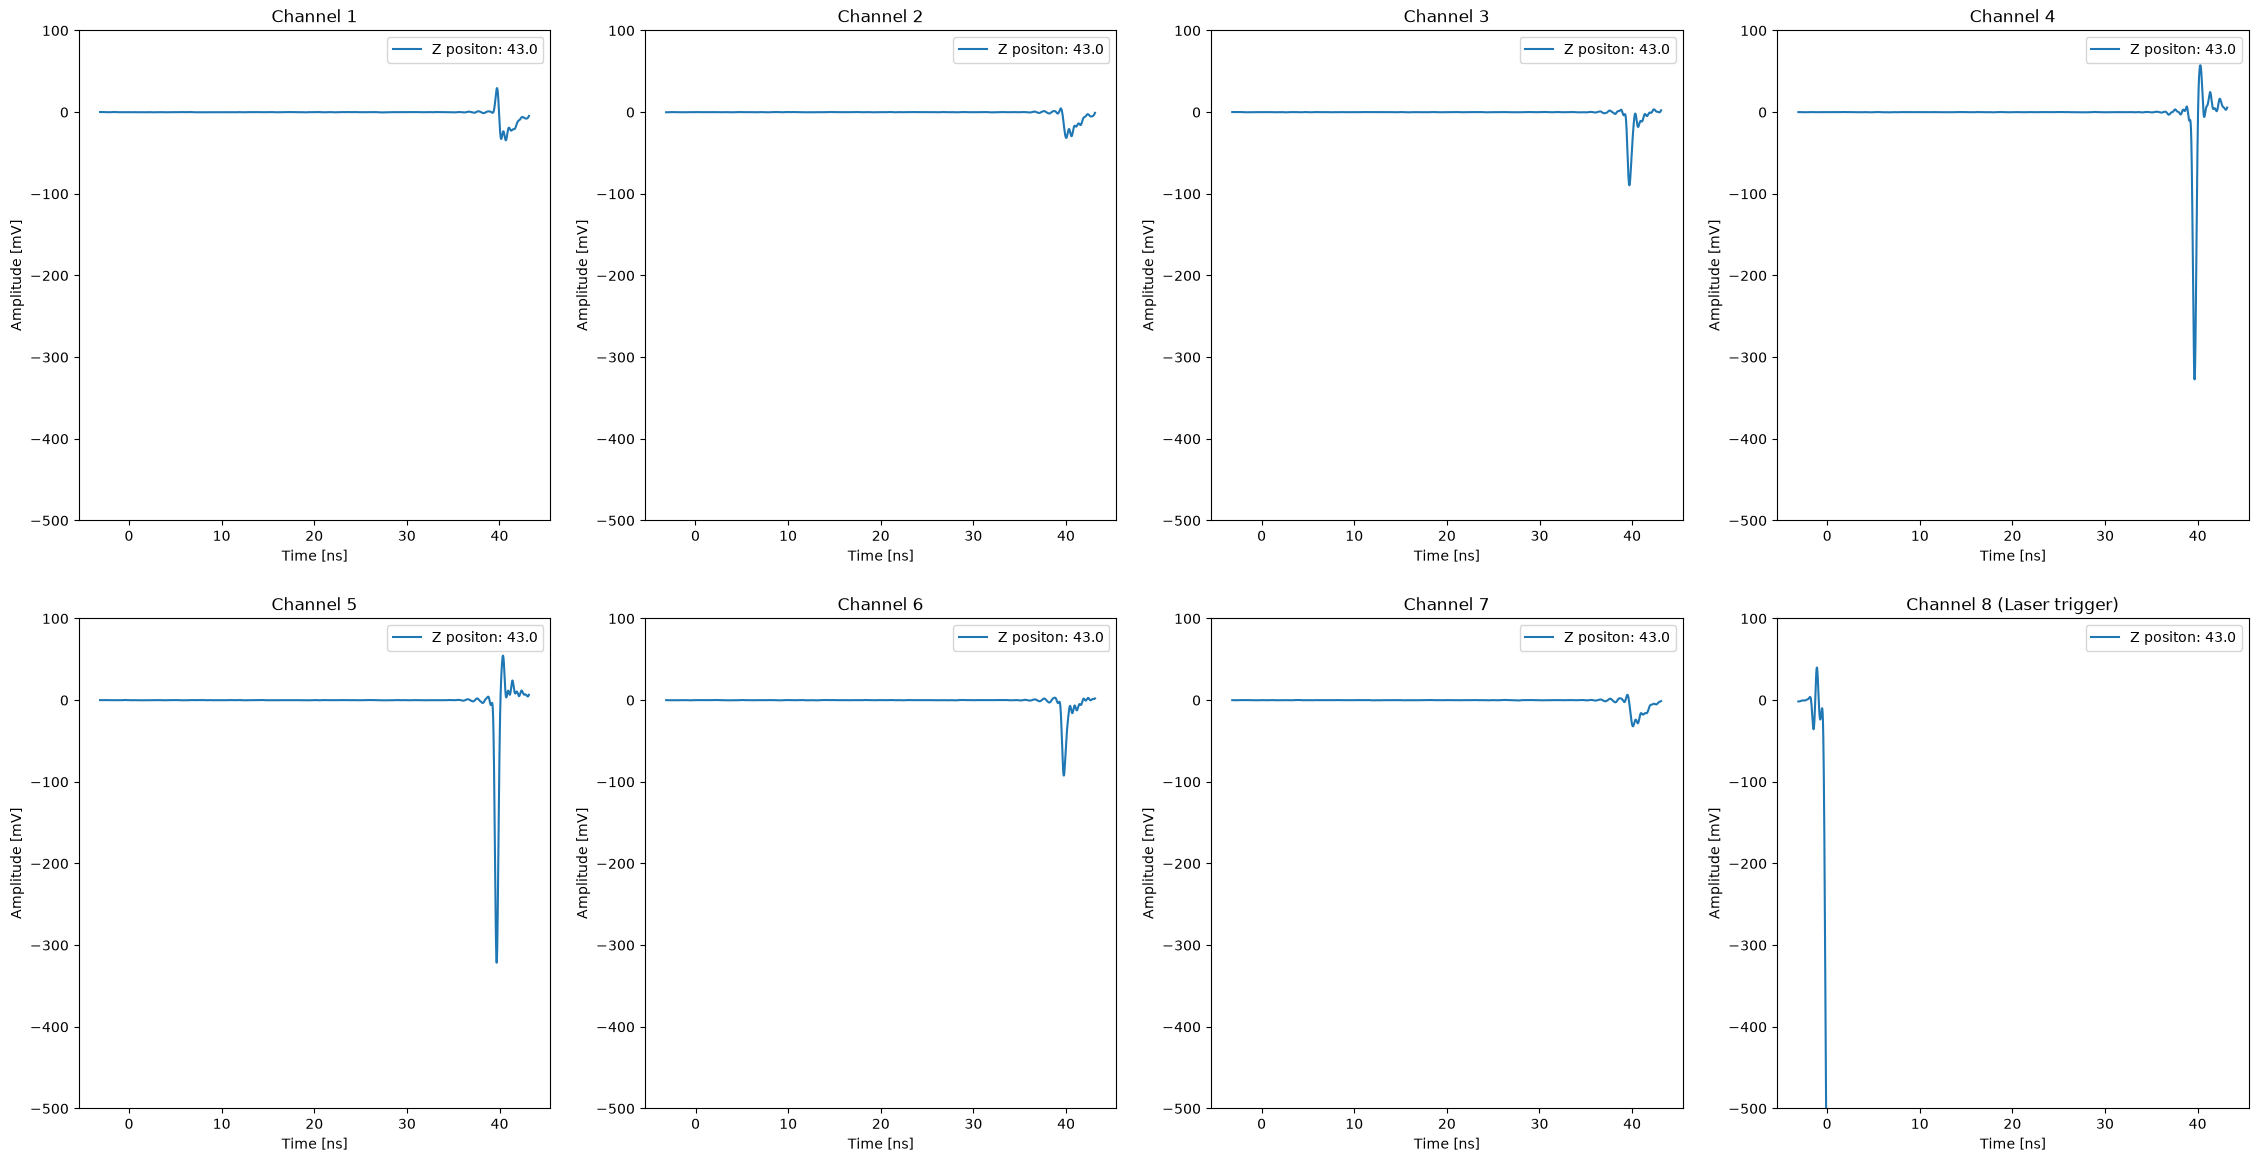





[[-0.0248, -0.0237, -0.0221, -0.0197, ..., -4.42, -4.21, -3.99, -3.76], ...] 8


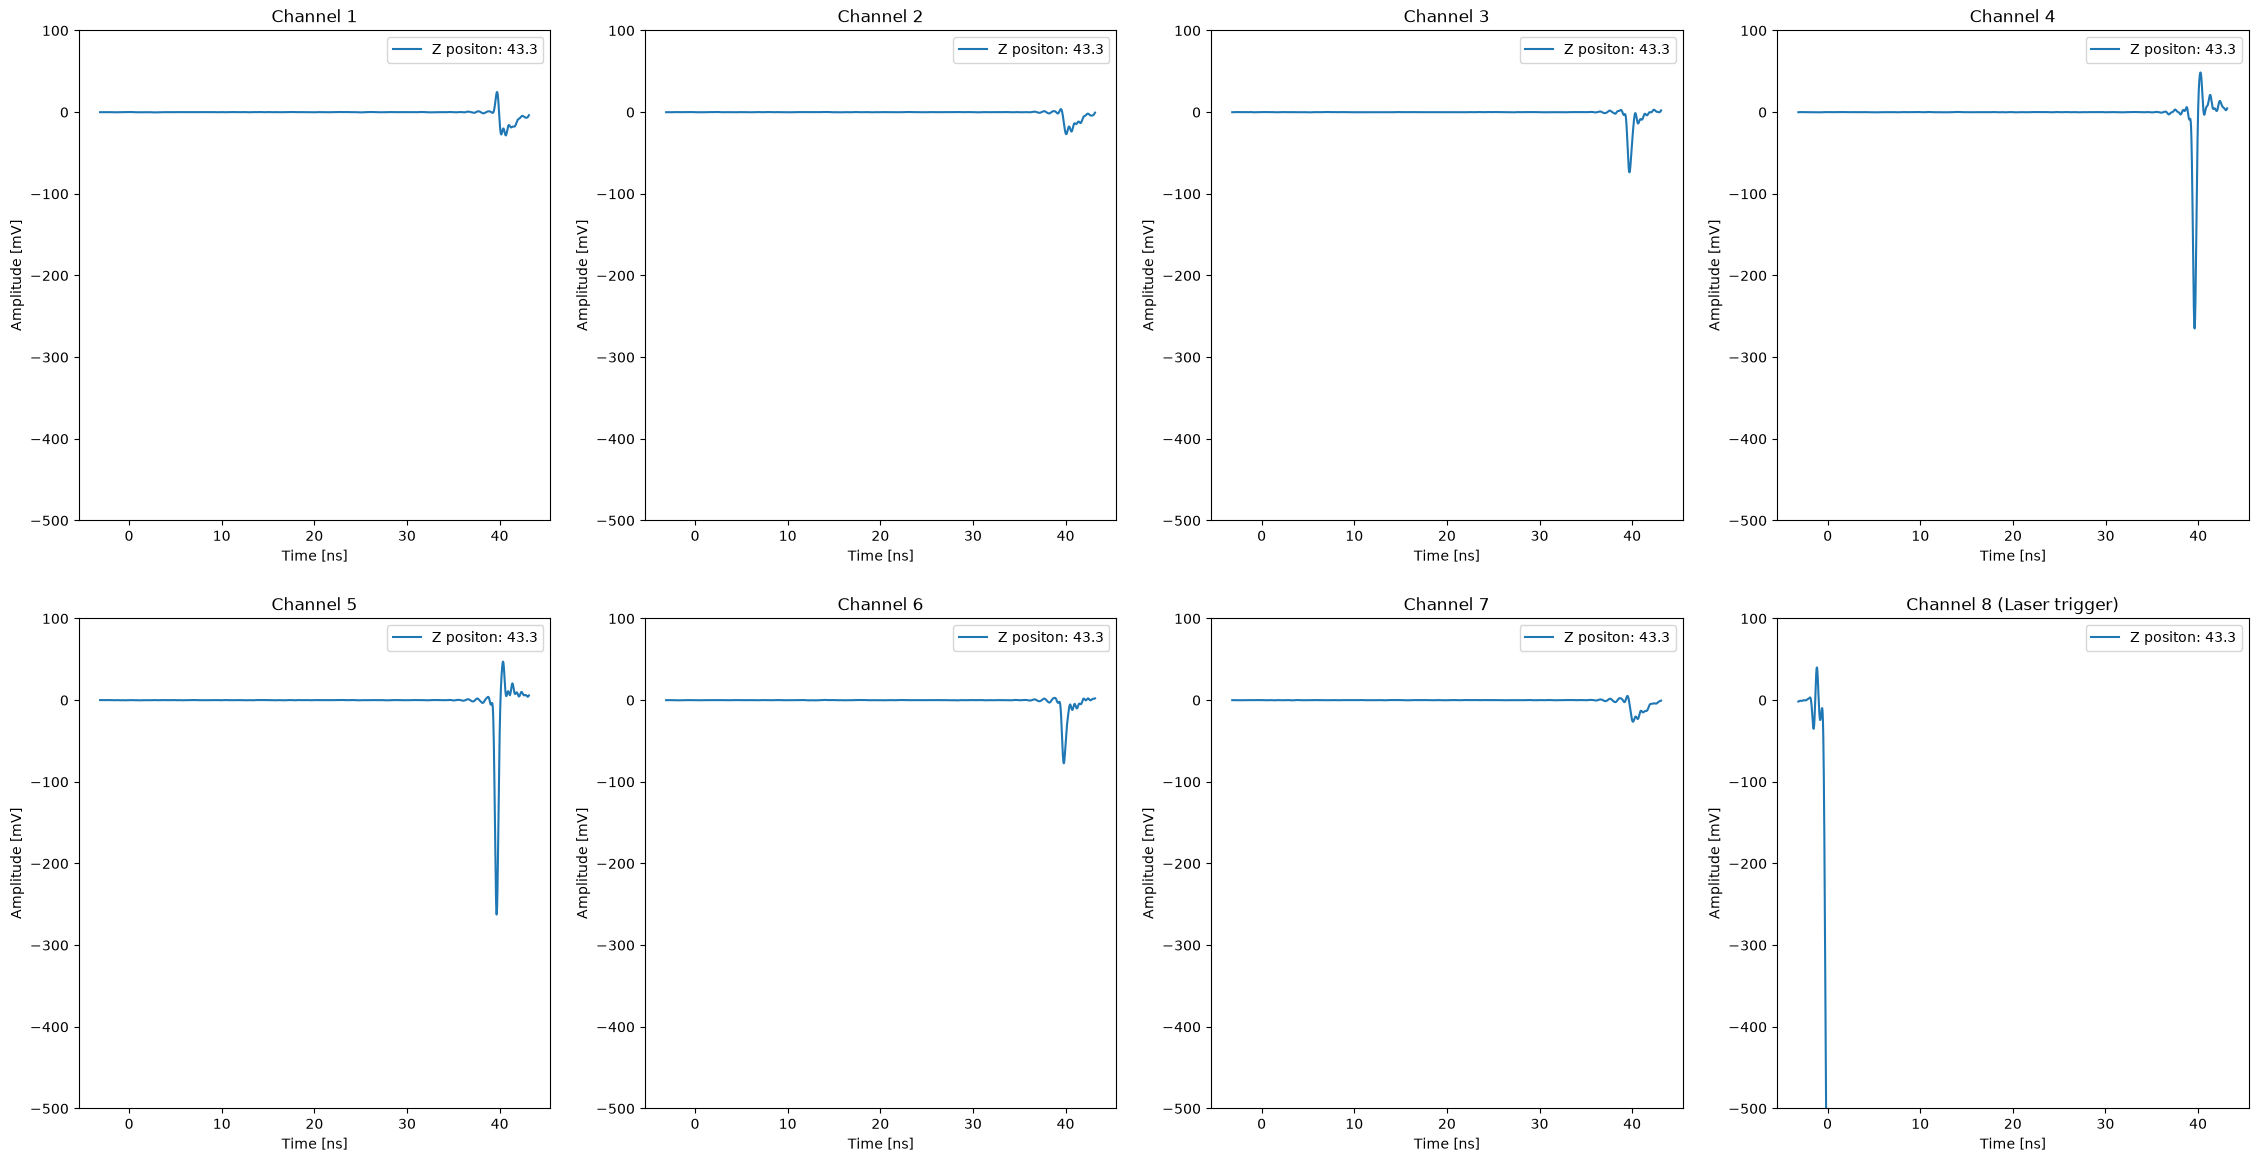





[[0.0148, 0.0196, 0.0247, 0.0283, 0.0322, ..., -4.14, -3.93, -3.7, -3.47], ...] 8


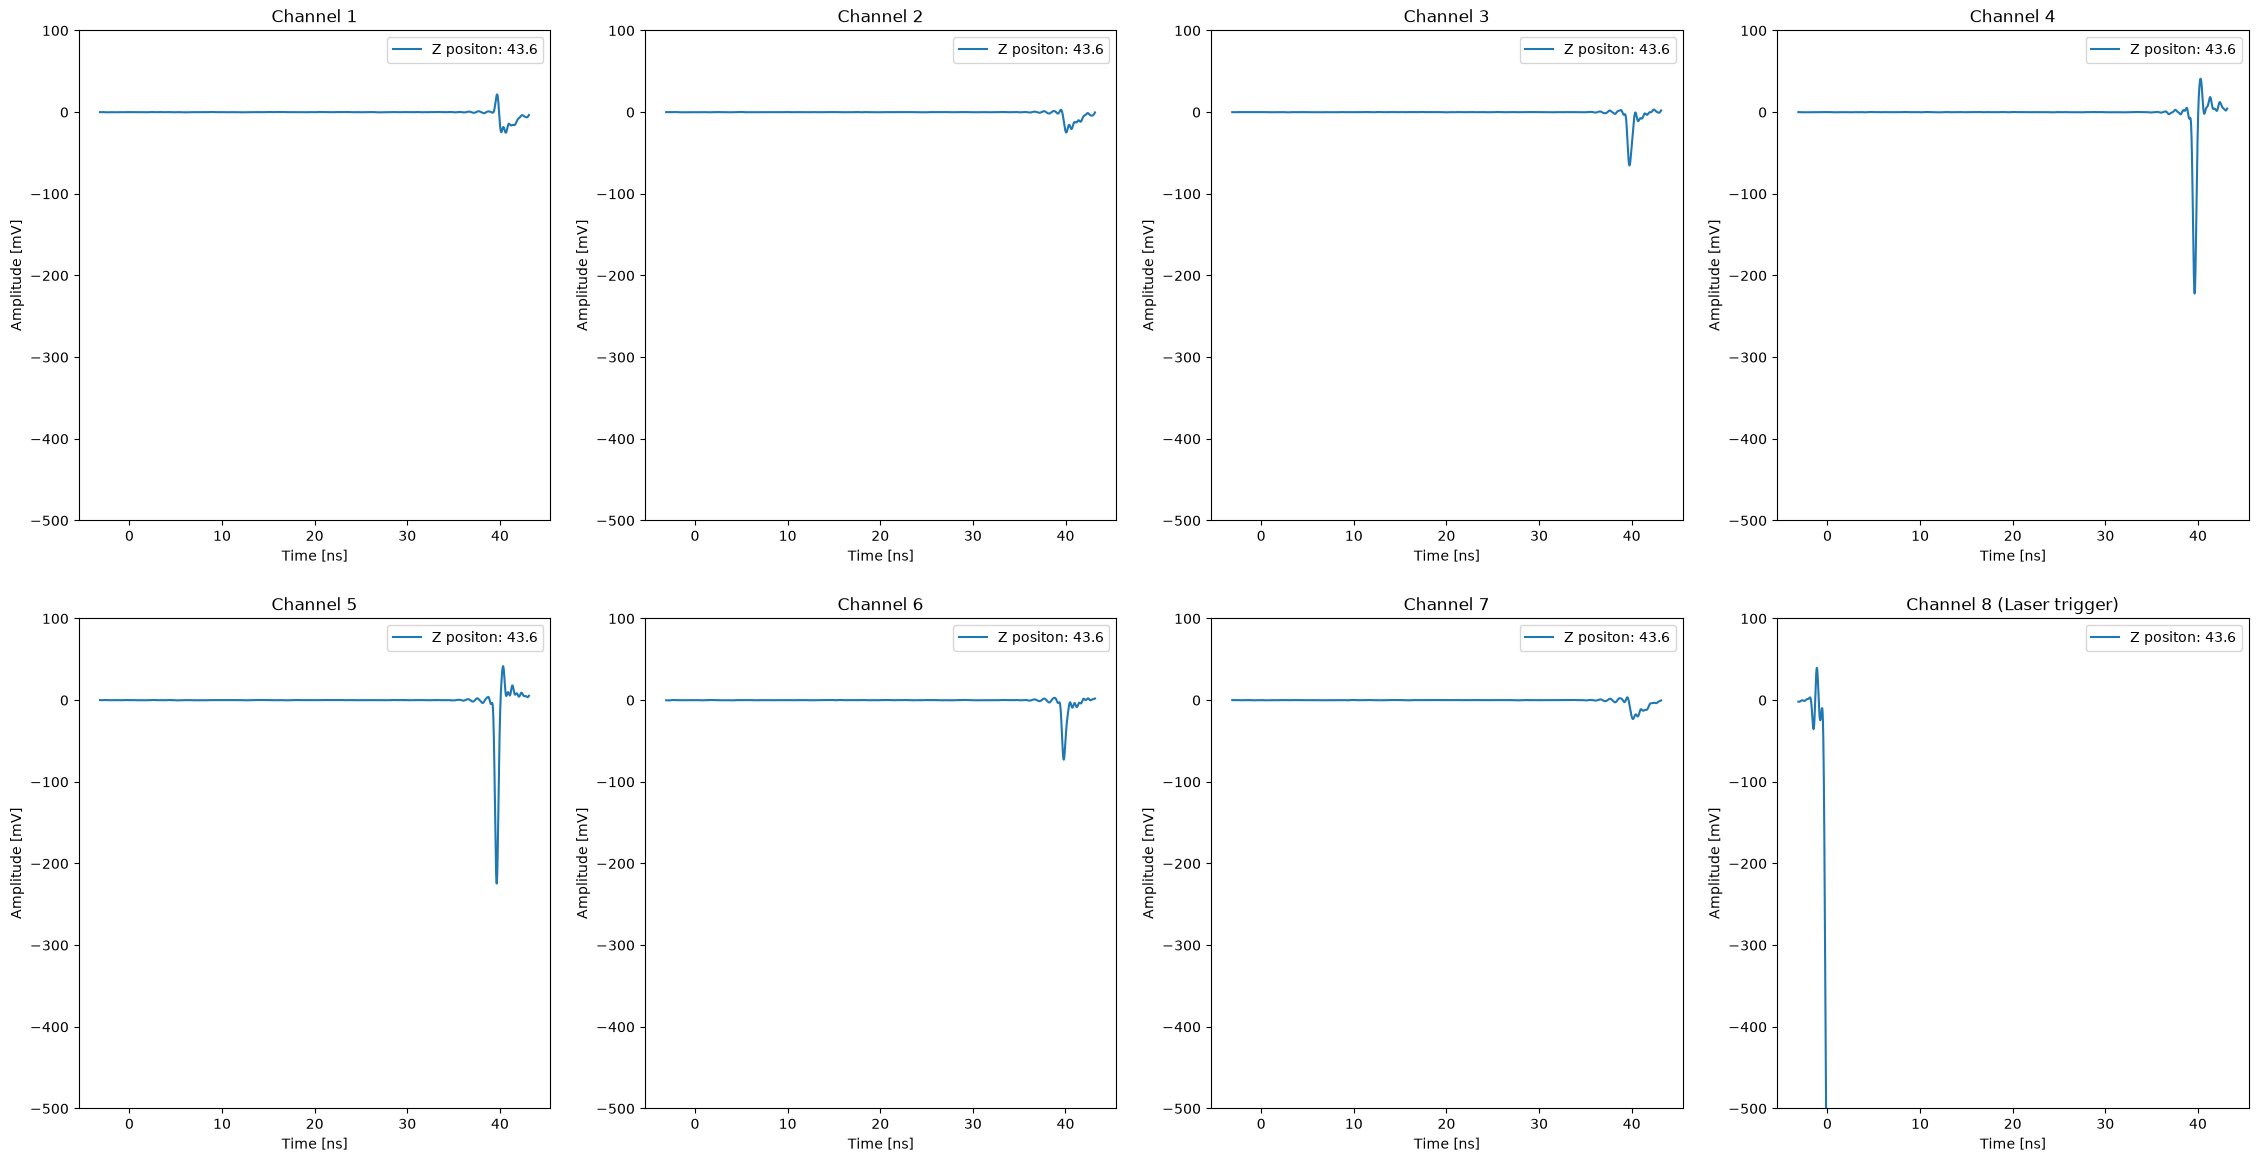





[[-0.083, -0.0899, -0.0972, -0.104, ..., -4.03, -3.84, -3.64, -3.43], ...] 8


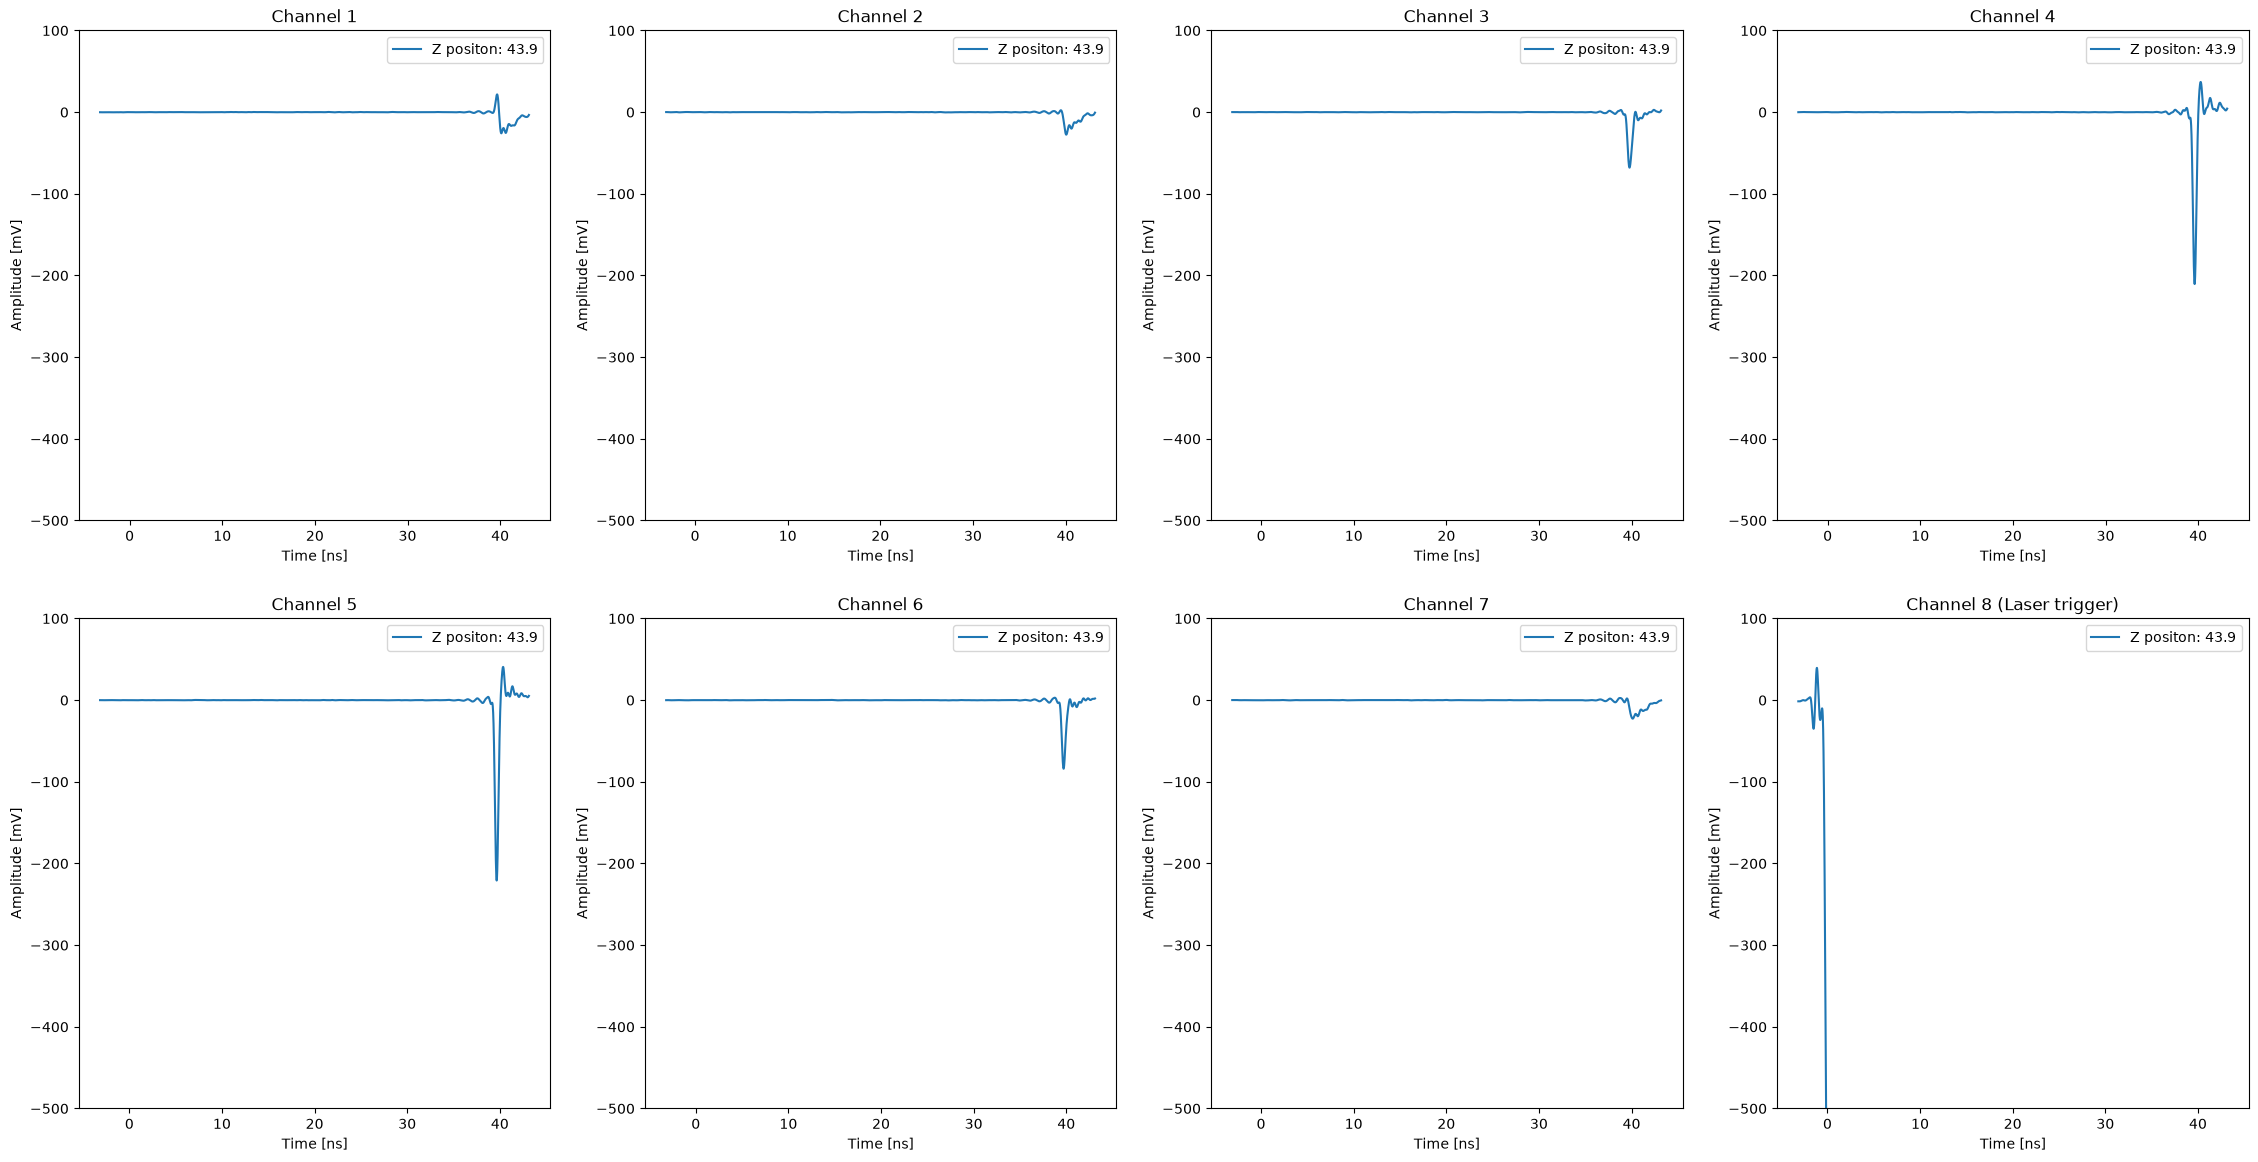





[[0.0189, 0.0214, 0.0236, 0.025, 0.0255, ..., -4.62, -4.39, -4.15, -3.9], ...] 8


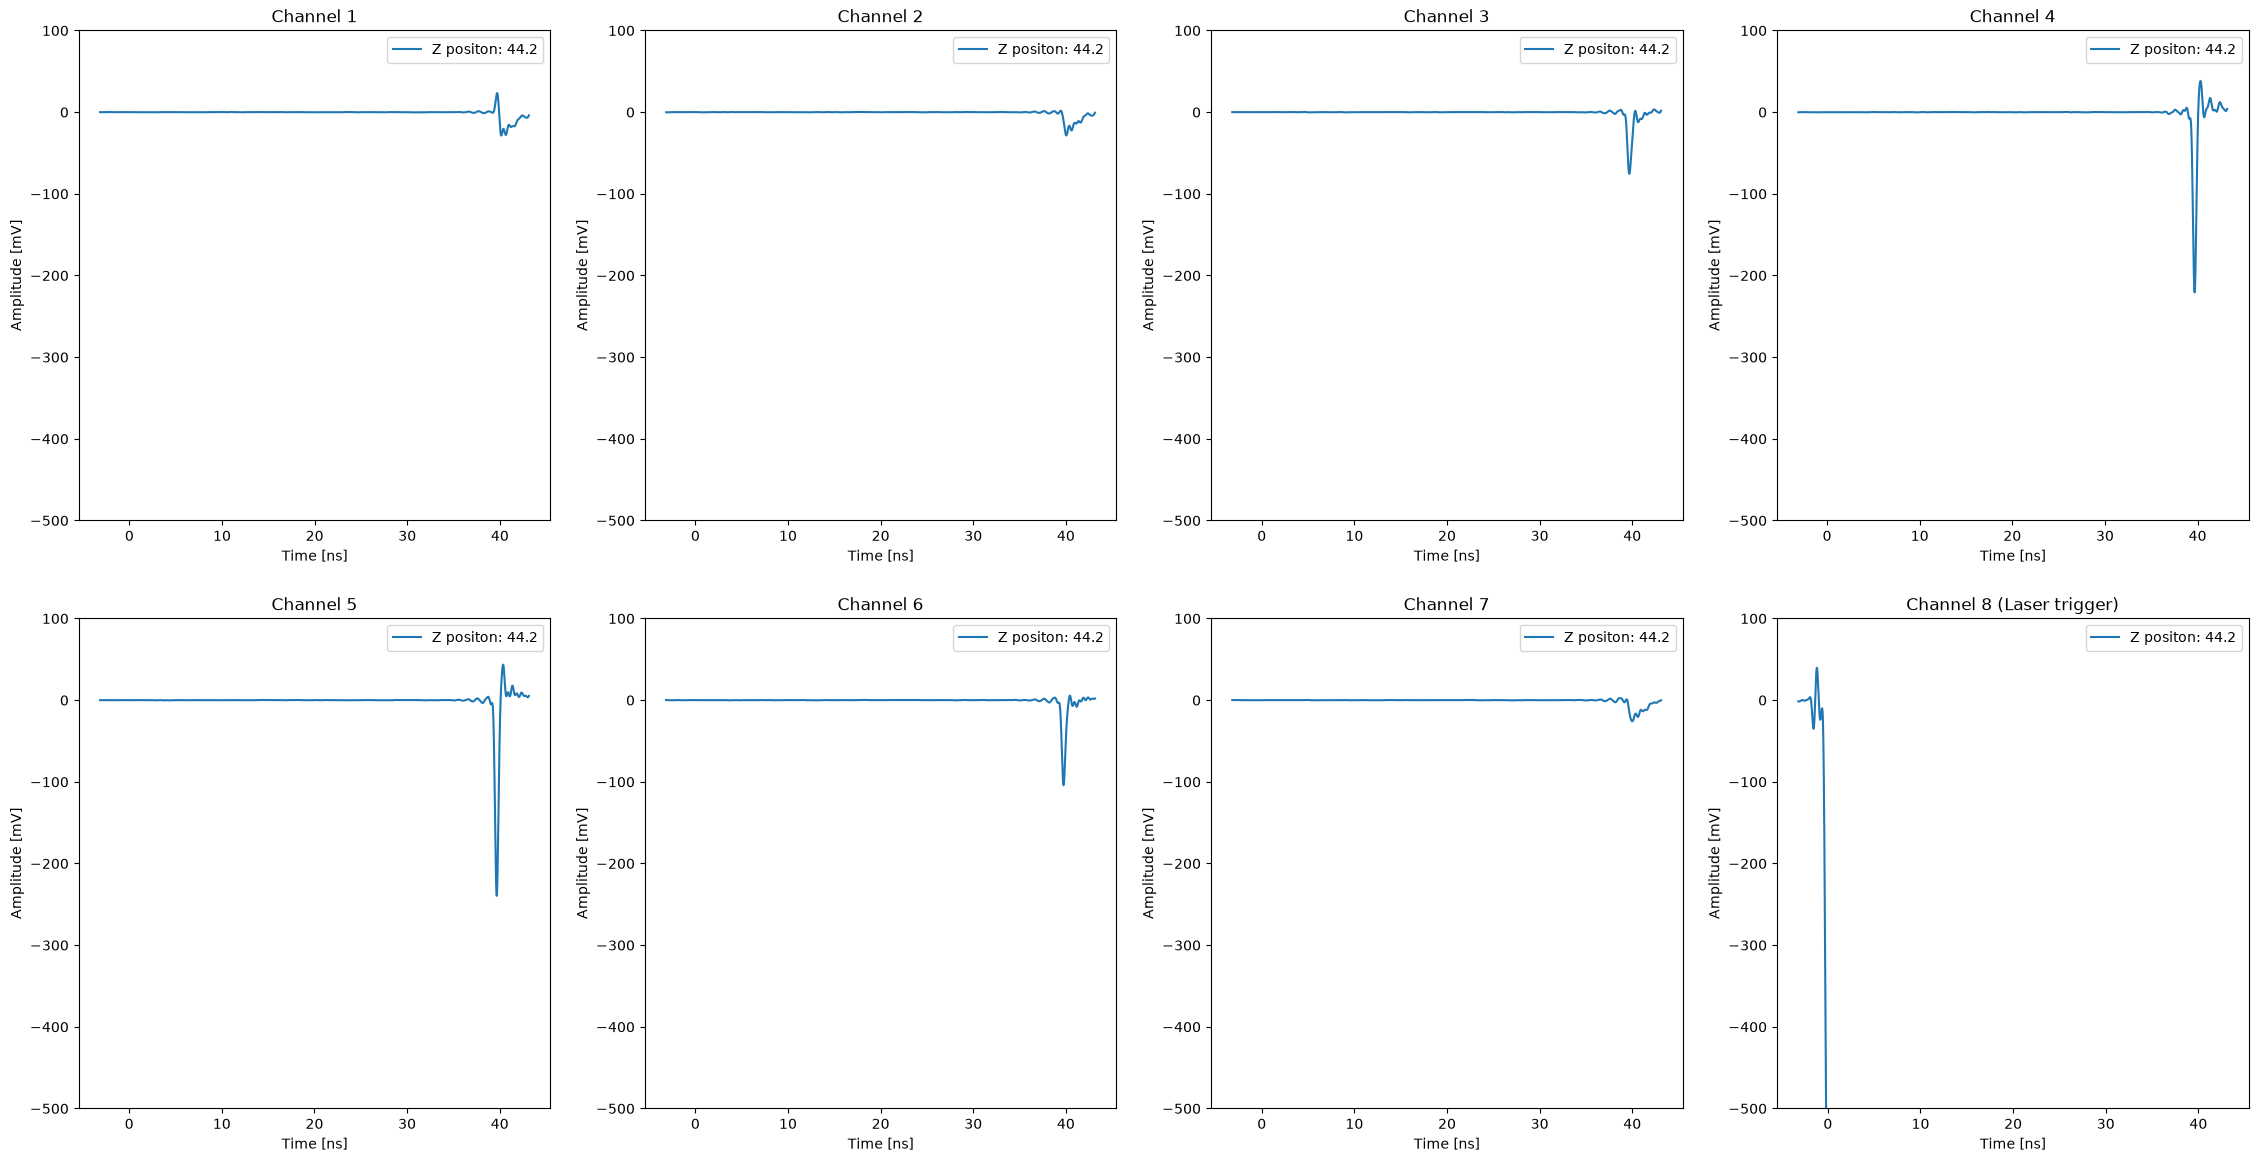





[[0.144, 0.145, 0.146, 0.146, 0.145, ..., -4.96, -4.73, -4.49, -4.24], ...] 8


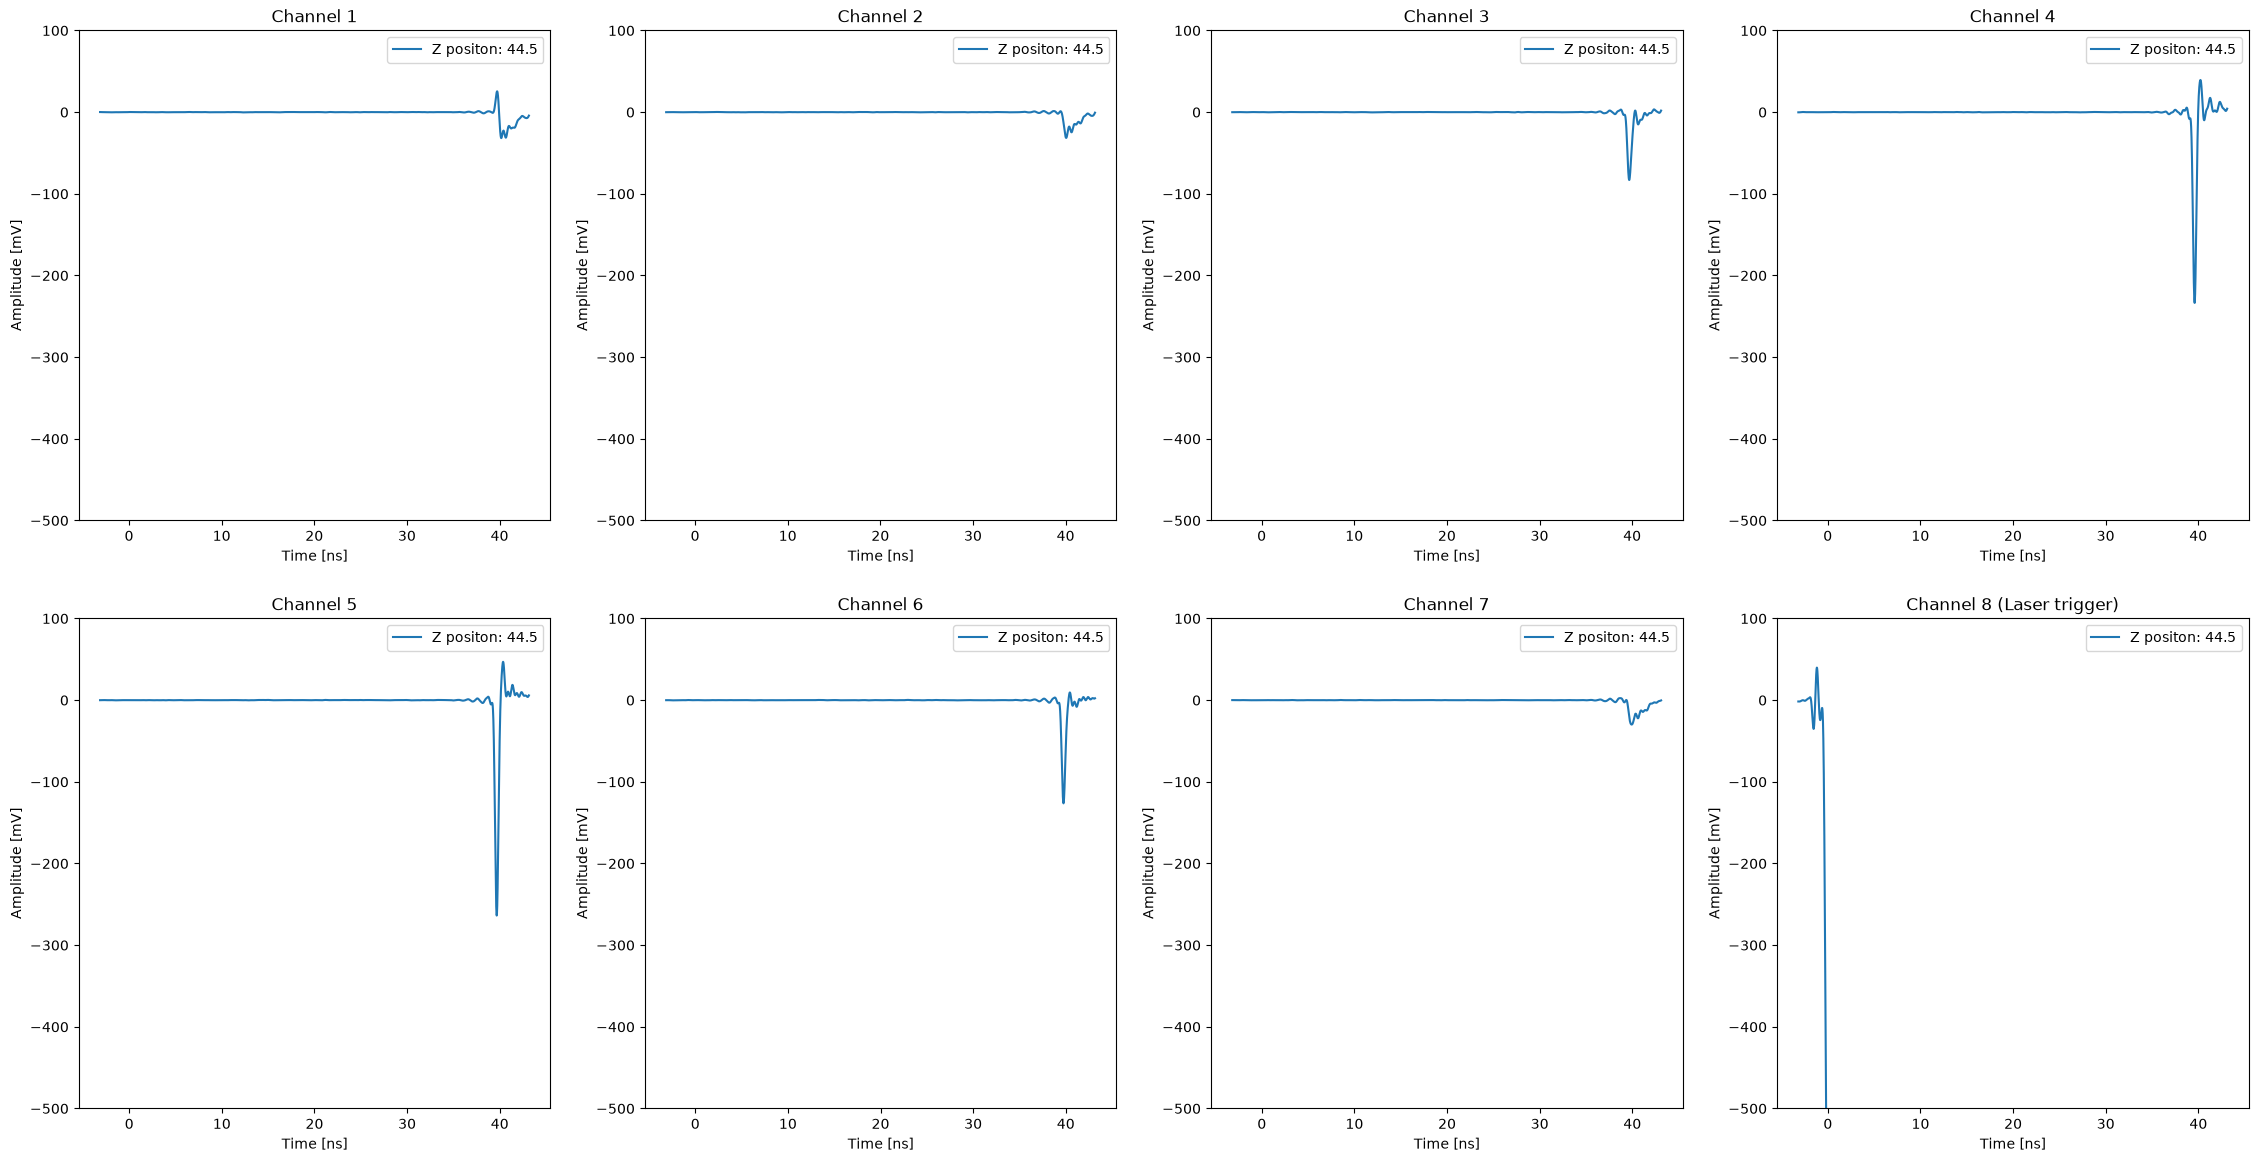





[[0.0337, 0.0354, 0.038, 0.0395, 0.0409, ..., -4.95, -4.72, -4.48, -4.22], ...] 8


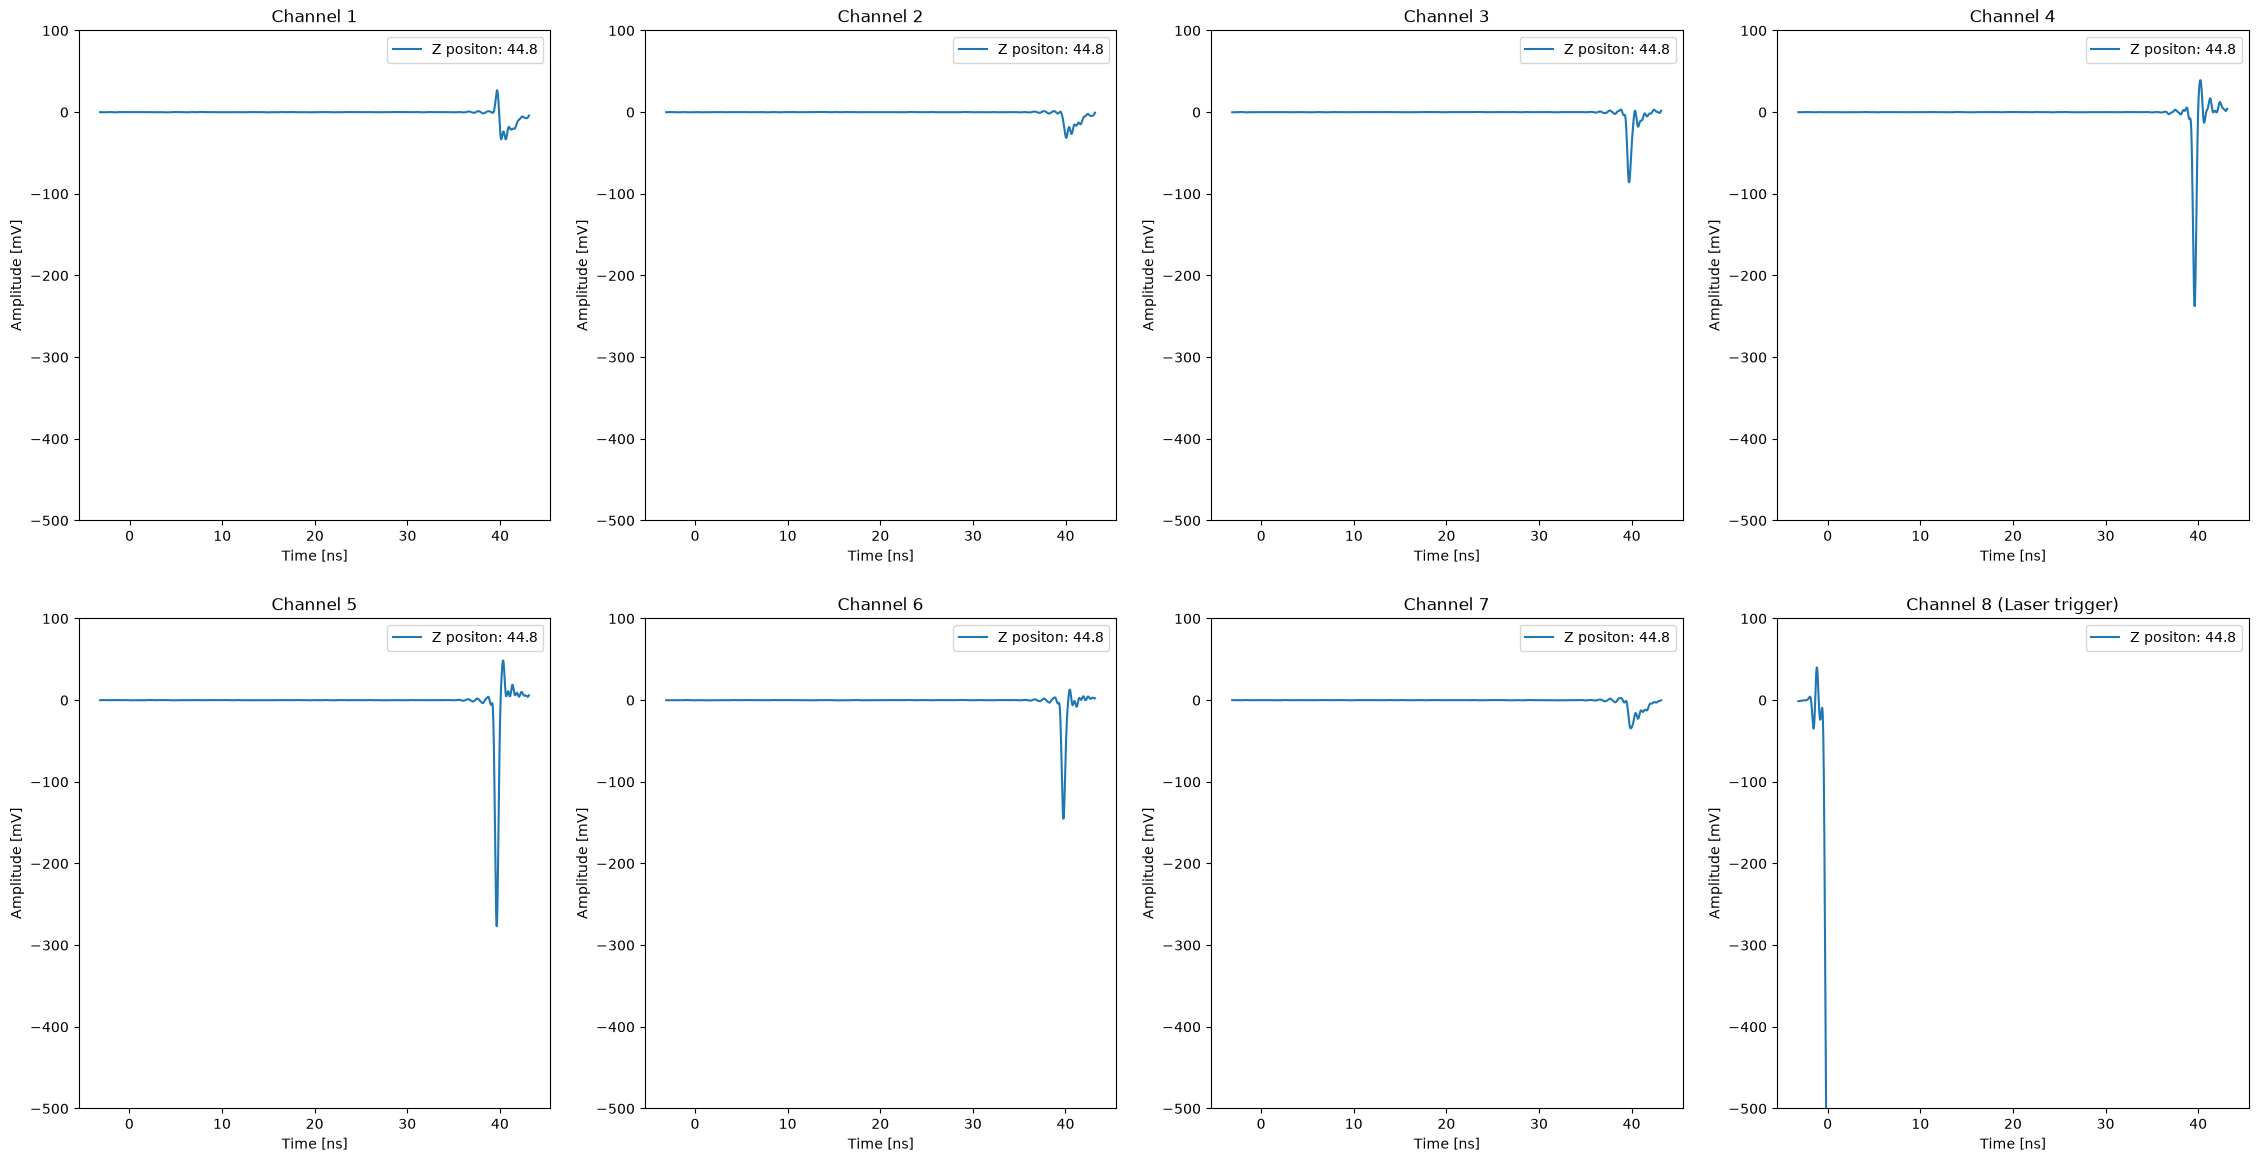





[[0.0302, 0.0389, 0.0471, 0.0557, 0.0635, ..., -5.22, -4.98, -4.73, -4.47], ...] 8


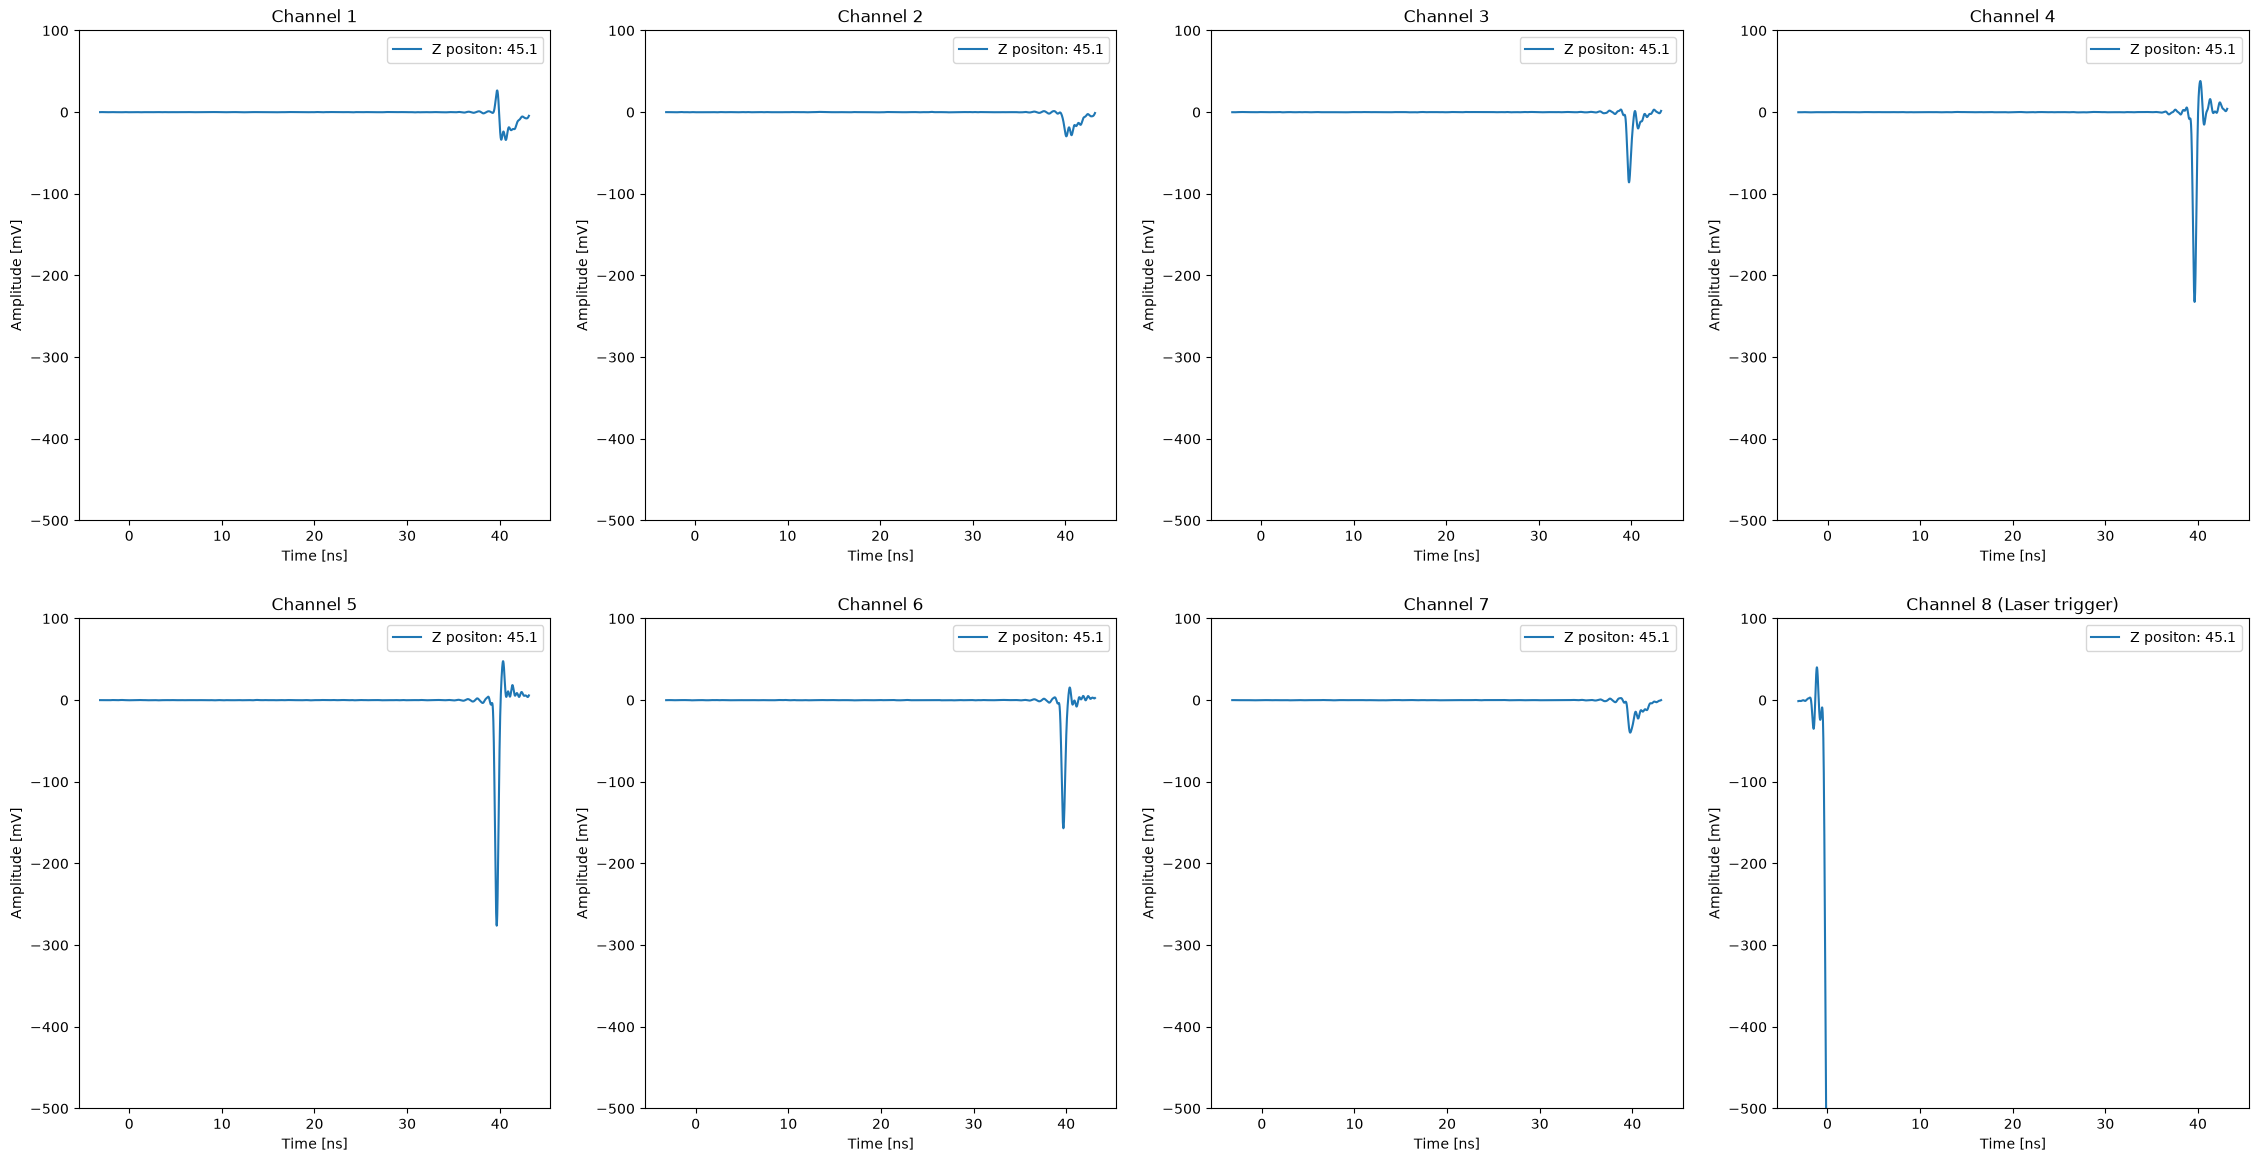





[[-0.0124, -0.0143, -0.0162, -0.0183, ..., -5.13, -4.88, -4.63, -4.36], ...] 8


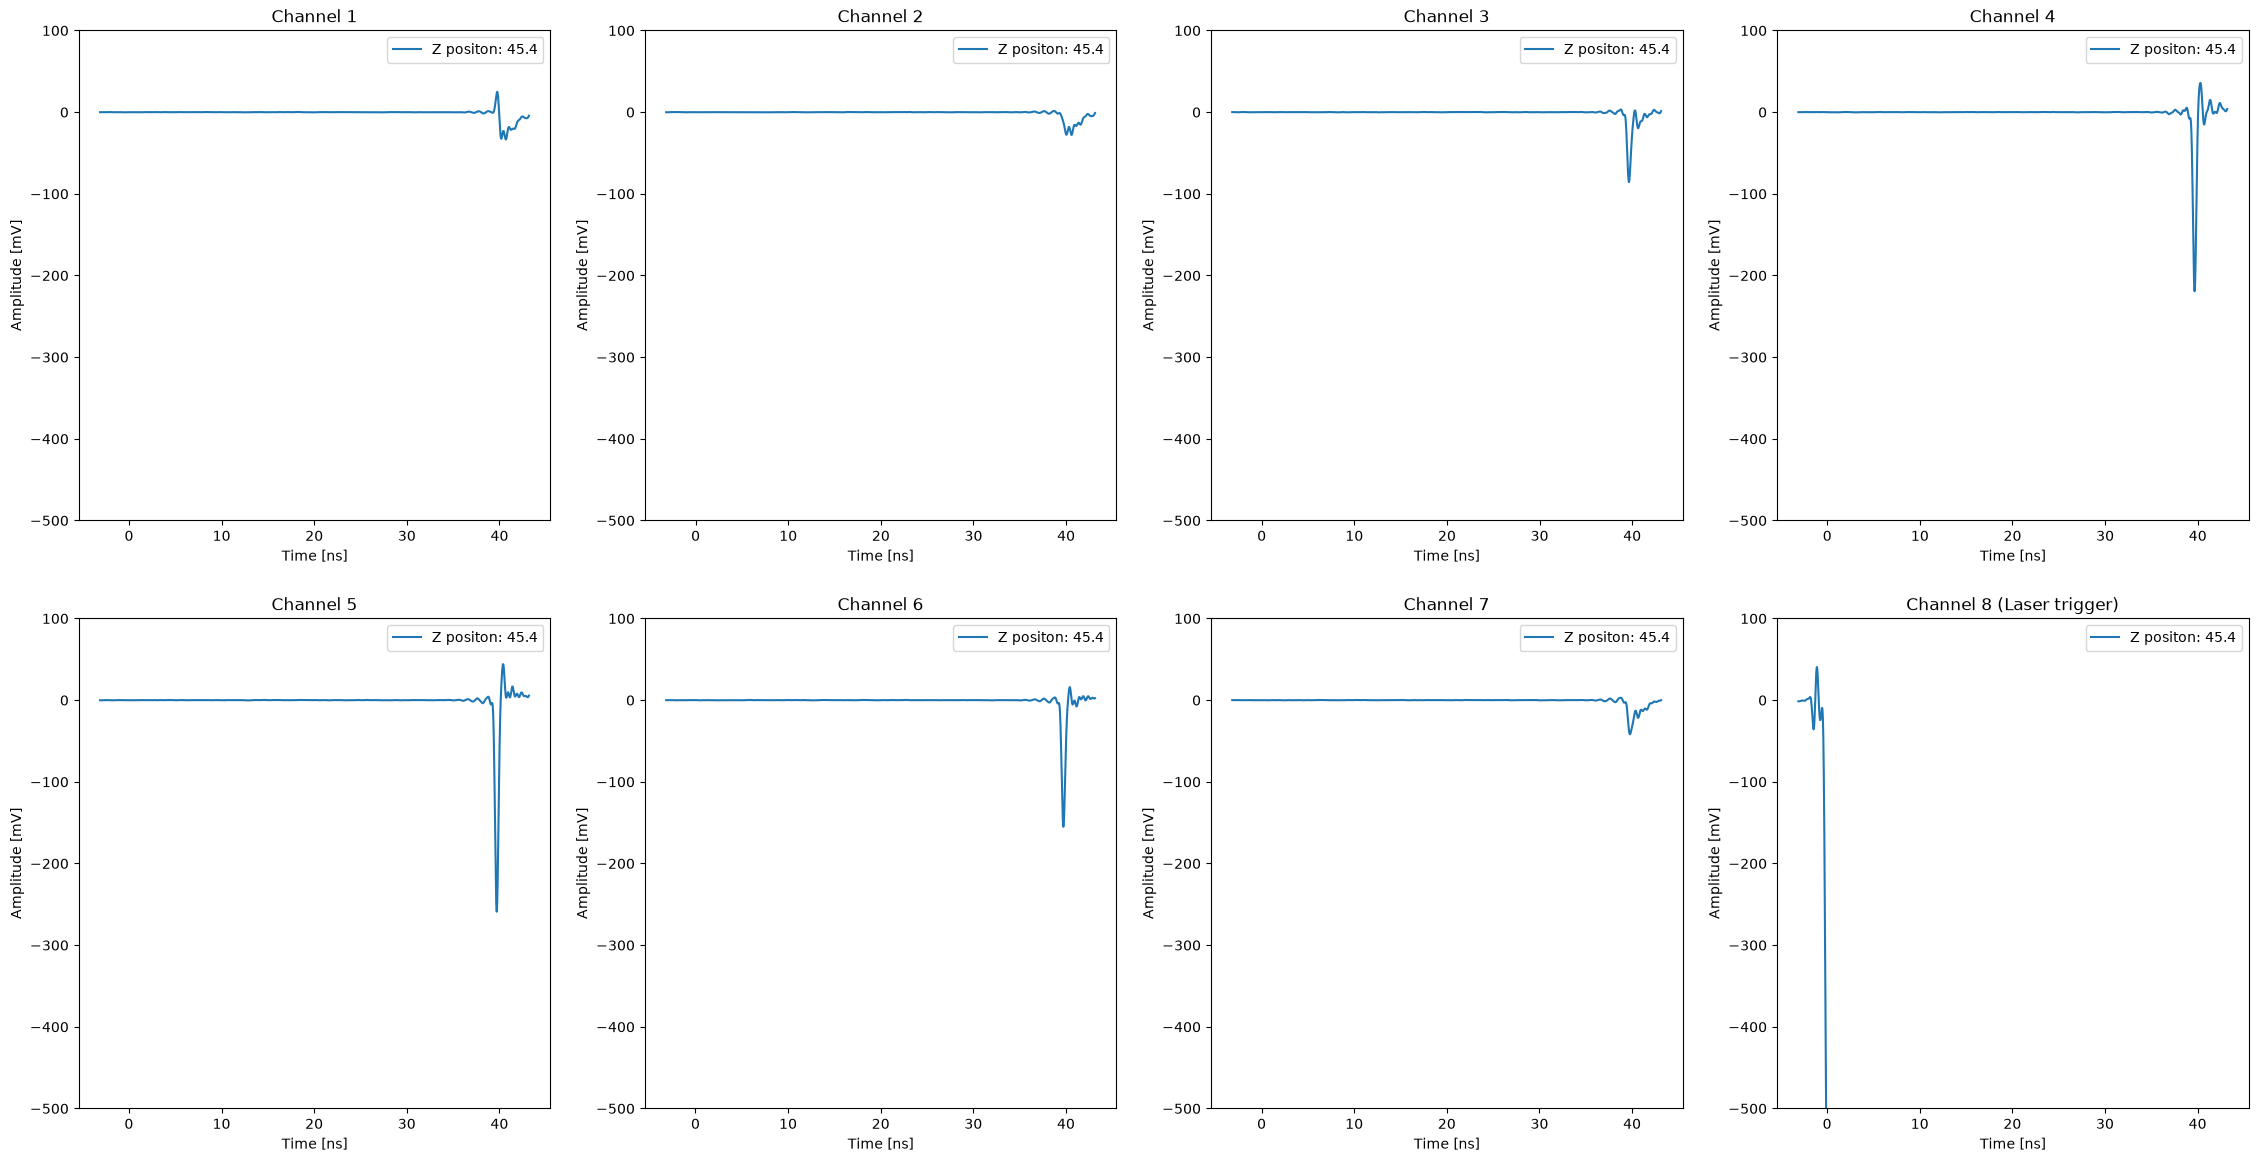





[[-0.00591, -0.00351, -0.000749, 0.0026, ..., -4.9, -4.67, -4.44, -4.2], ...] 8


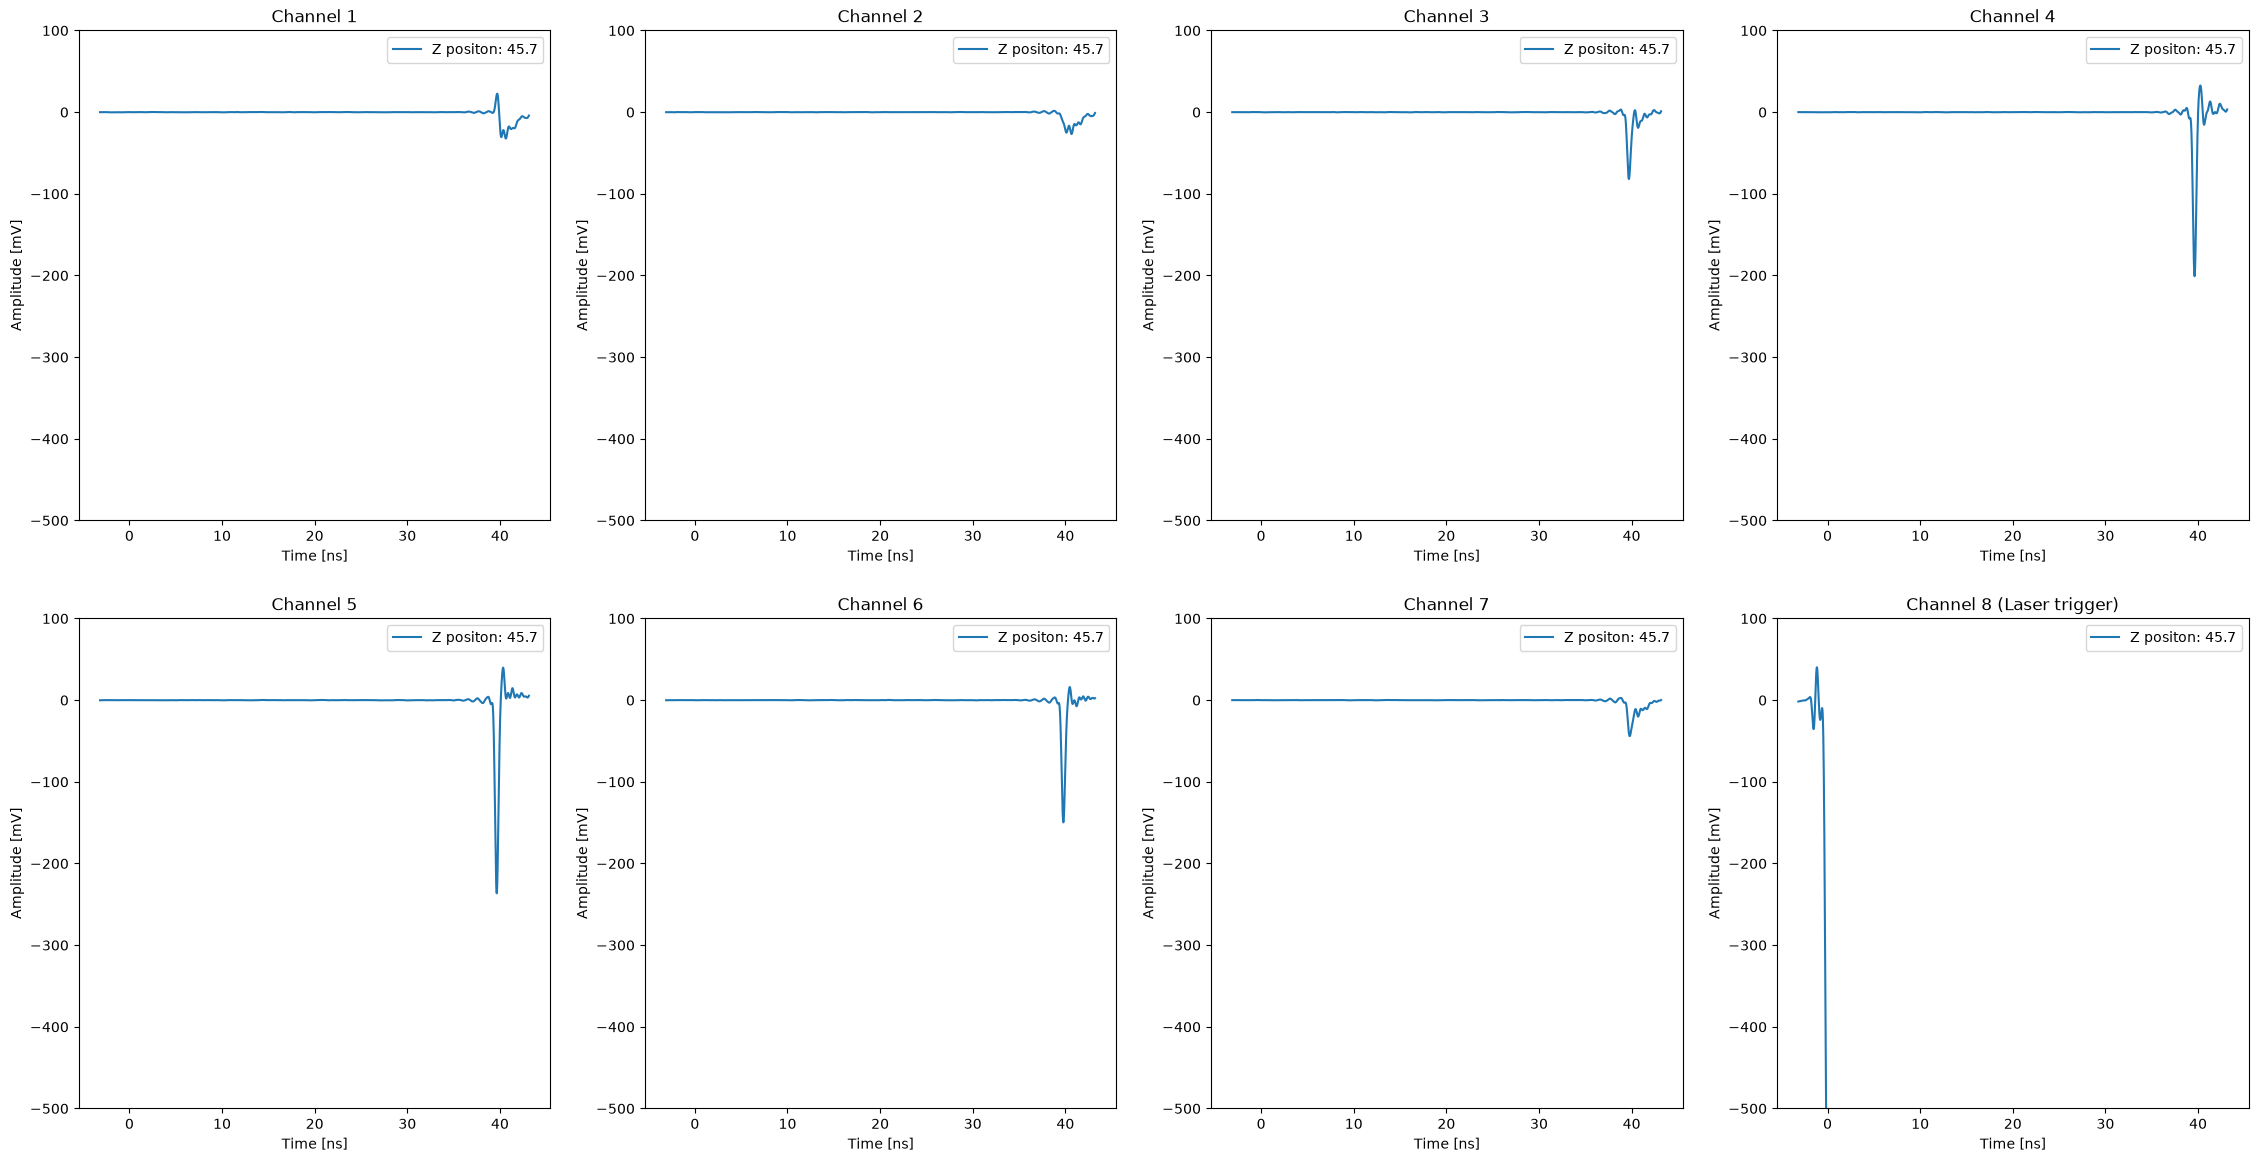





[[-0.0413, -0.0499, -0.0588, -0.0675, ..., -4.71, -4.5, -4.28, -4.05], ...] 8


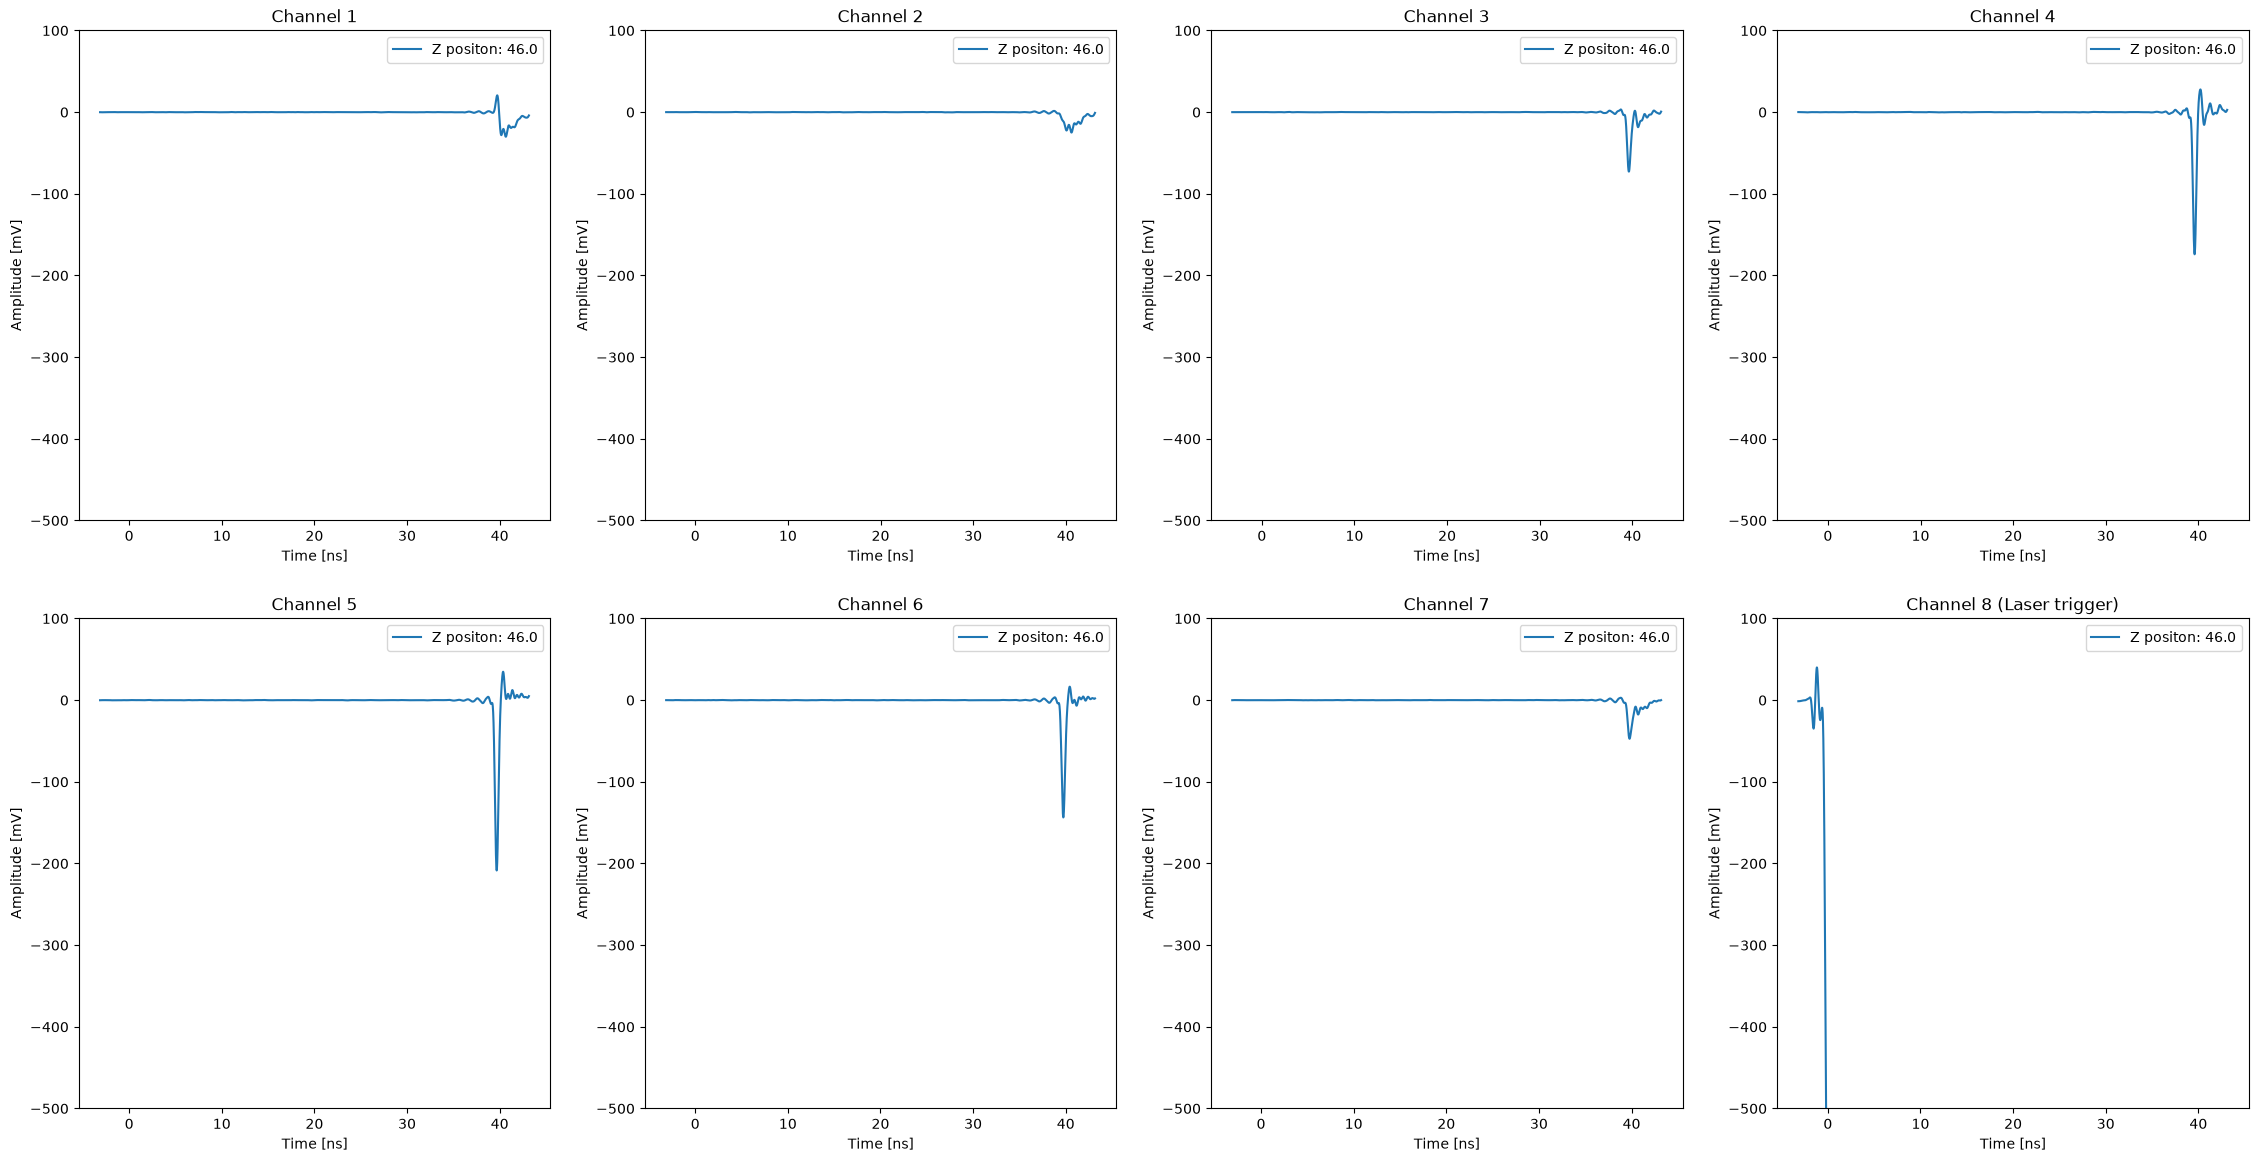

In [13]:
rows = 2
cols = 4
size = 7

ranges = (
    (38, 42),
    (33, 42),
    (30, 36),
    (28, 32),
    (23, 27),
    (18, 22),
    (18, 22),
    (18, 22)
)

for i, z in enumerate(Z_range): # 
    # sel = (baseline_RMS[:,3] < 3) & ((timestamps_10[:,3] > -13) & (timestamps_10[:,3] > -13) & (timestamps_10[:,3] < -1) & (timestamps_10[:,3] < -1)) #  & (amp[3])
    # print(sel)
    l = f"pos_{z}_41.25_105.0"
    fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

    mean_channels = ak.mean(channel[l], axis = 0)
    labels = [
        "Channel 1",
        "Channel 2",
        "Channel 3",
        "Channel 4",
        "Channel 5",
        "Channel 6",
        "Channel 7",
        "Channel 8 (Laser trigger)"
    ]
    print(mean_channels, len(mean_channels))
    for j, ch in enumerate(mean_channels): # Each channel
        y = (j) % cols
        x = (j) // cols

        mask = (time[l][:,0][j]>ranges[j][0]) & (time[l][:,0][j]<ranges[j][1])
        # ax[x][y].plot(time[l][:,0][j][mask], ch[mask], label = f"Z positon: {z}")
        ax[x][y].plot(time[l][:,0][j], ch, label = f"Z positon: {z}")
        ax[x][y].set_ylim(-500, 100)
        ax[x][y].set_title(labels[j])
        ax[x][y].set_xlabel("Time [ns]")
        ax[x][y].set_ylabel("Amplitude [mV]")
        ax[x][y].legend()
    plt.show()
    print("\n\n\n")

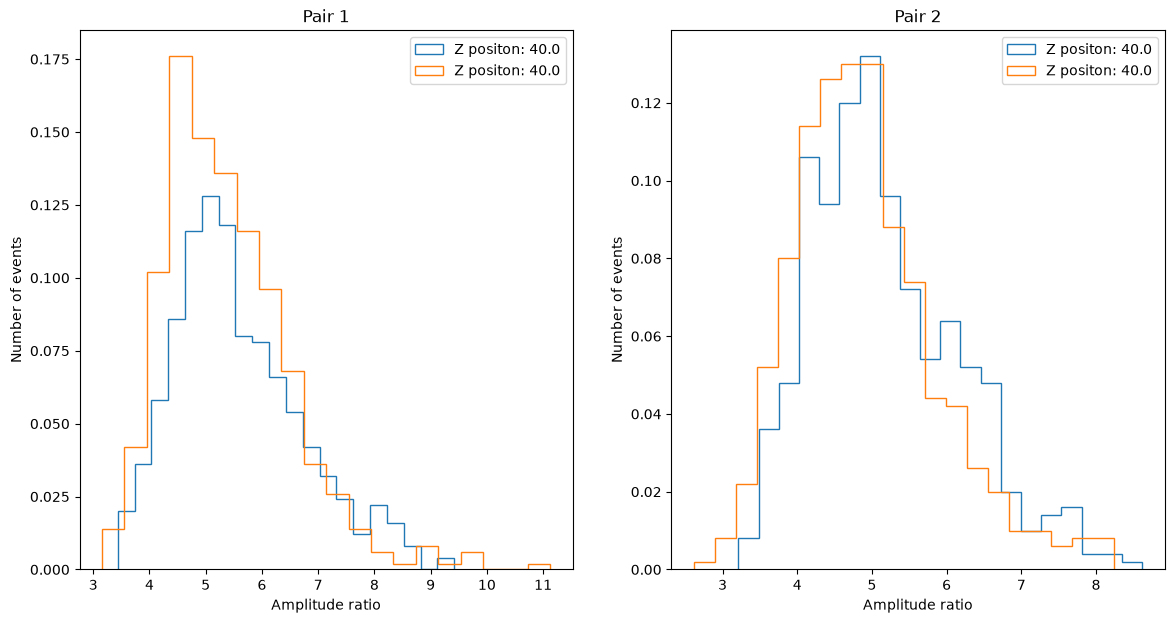

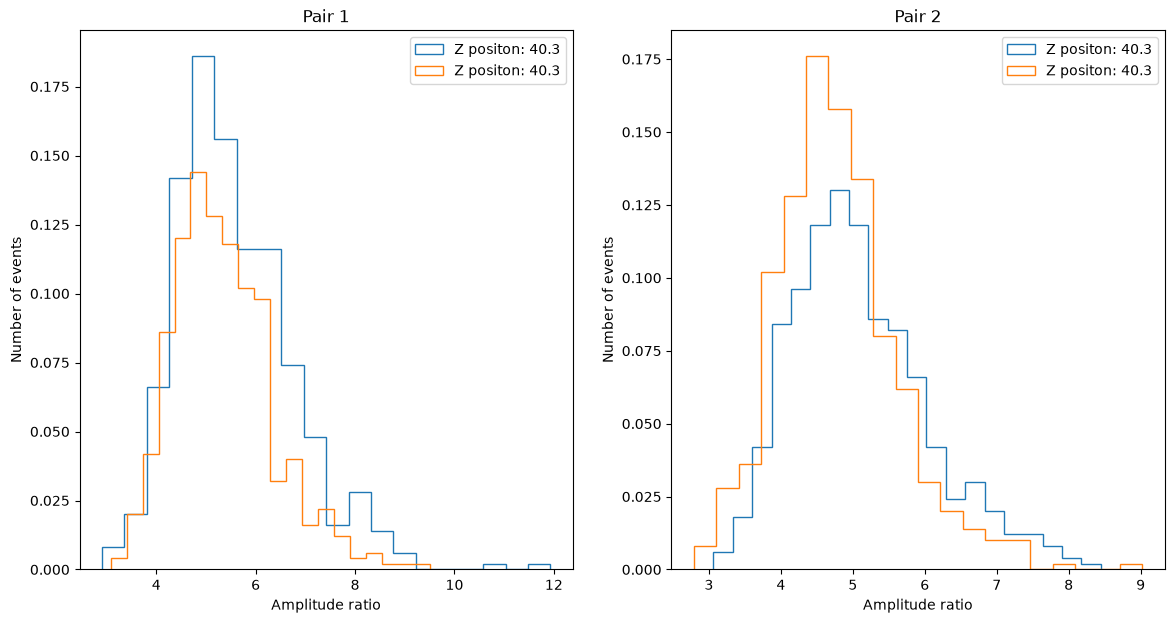

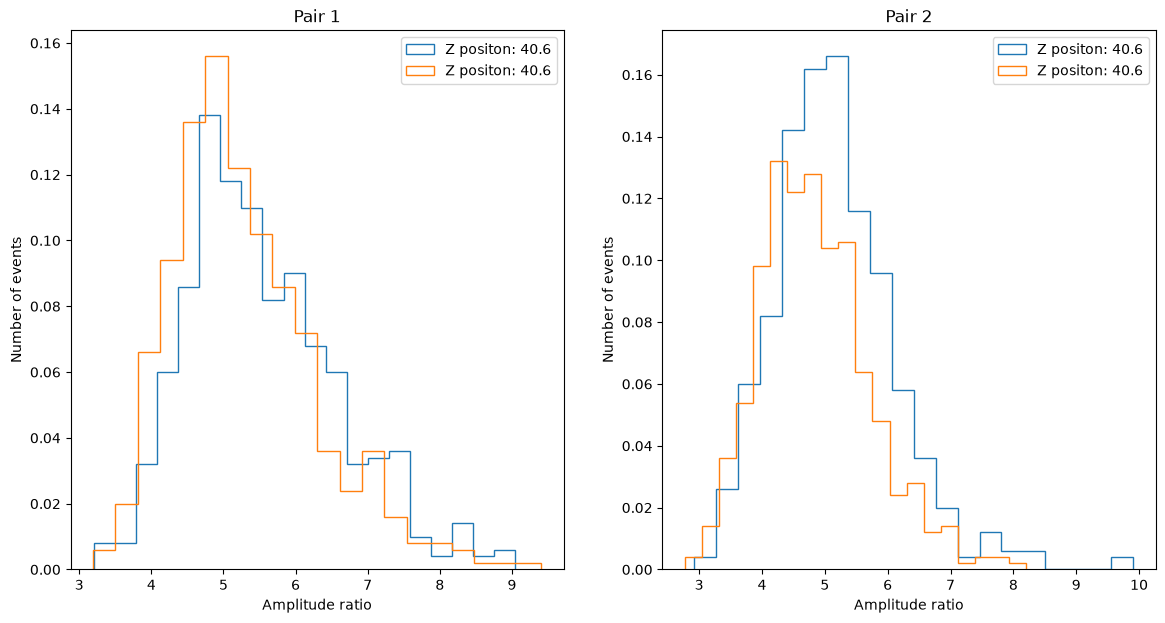

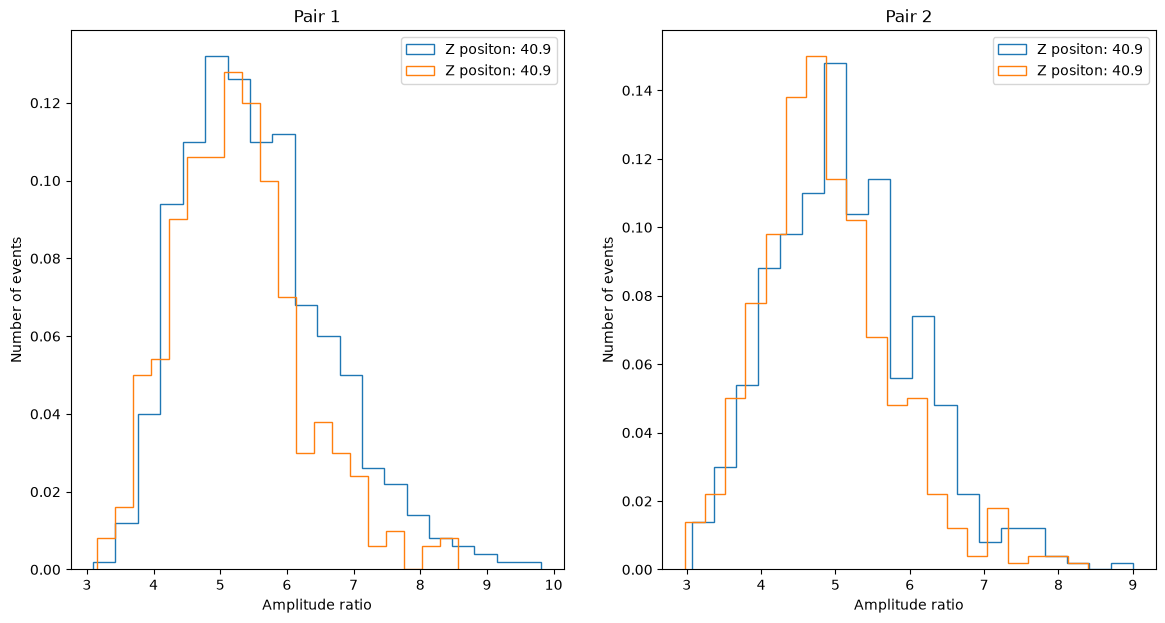

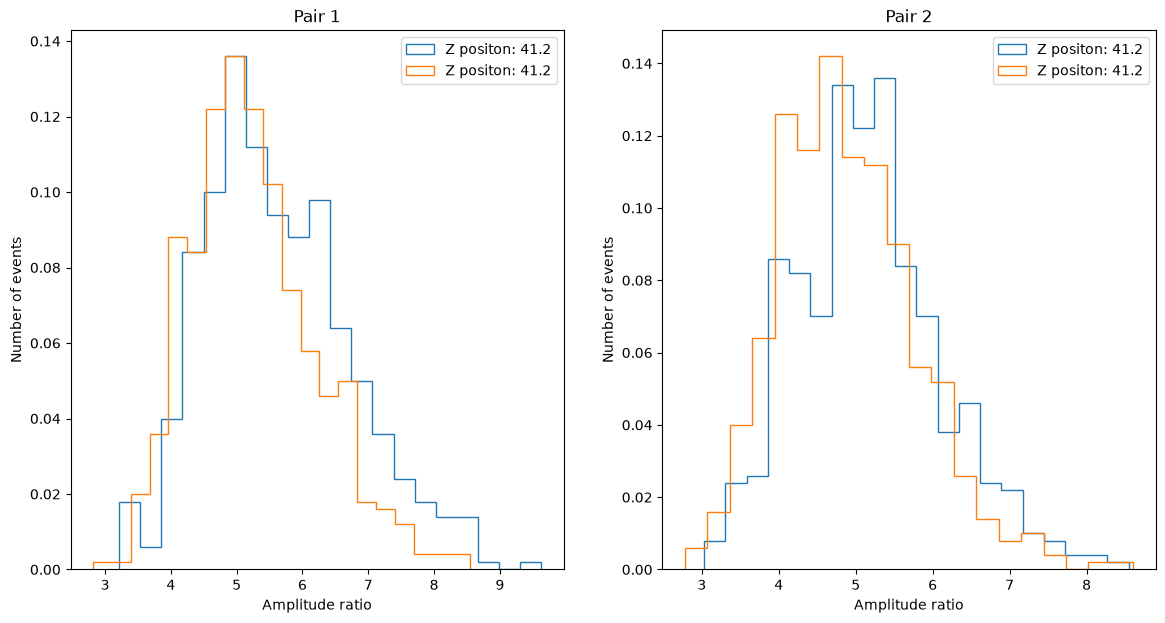

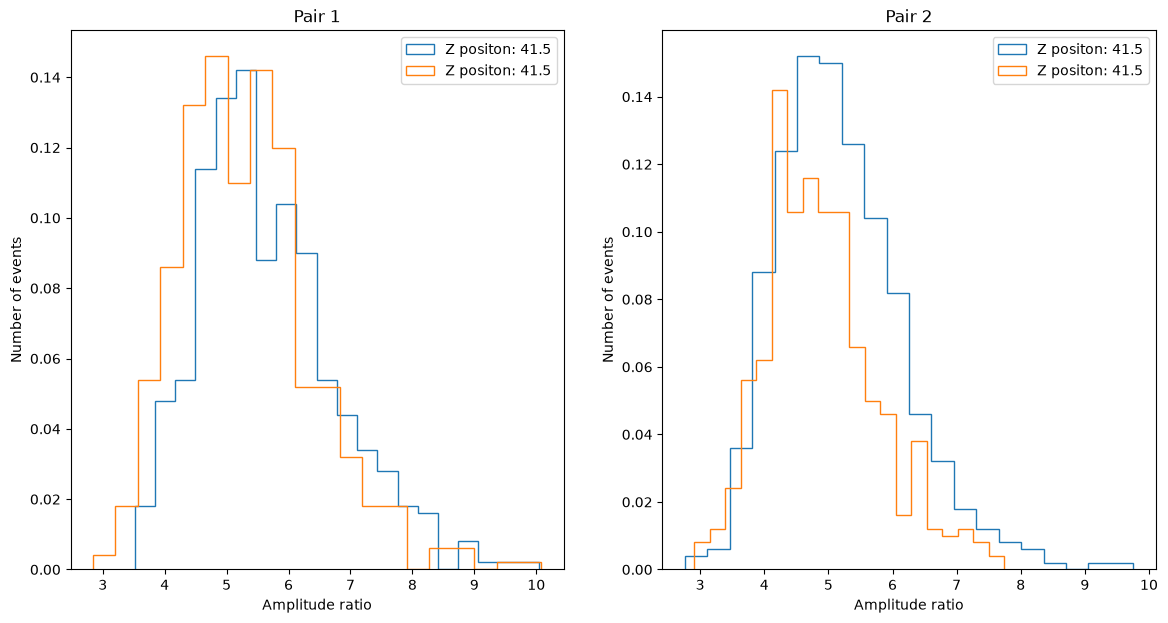

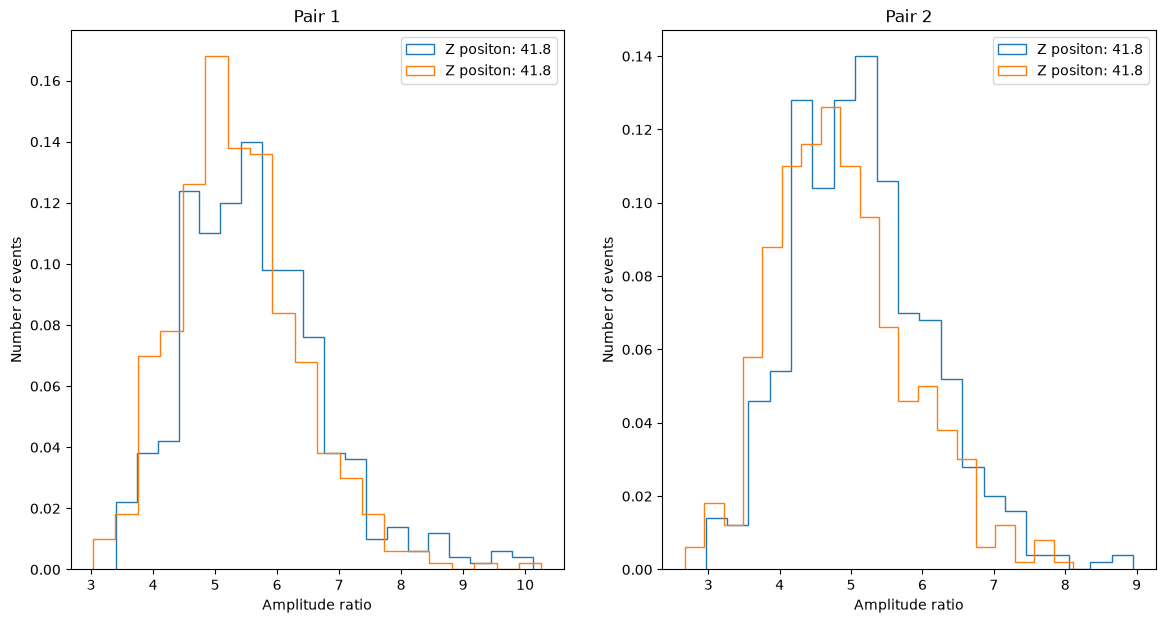

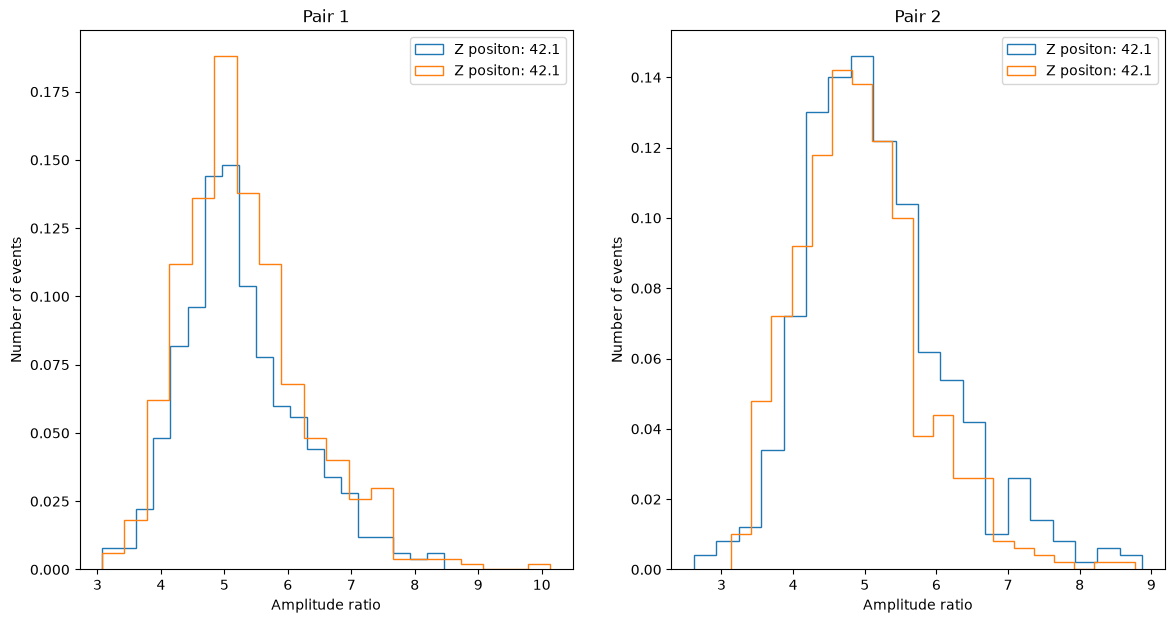

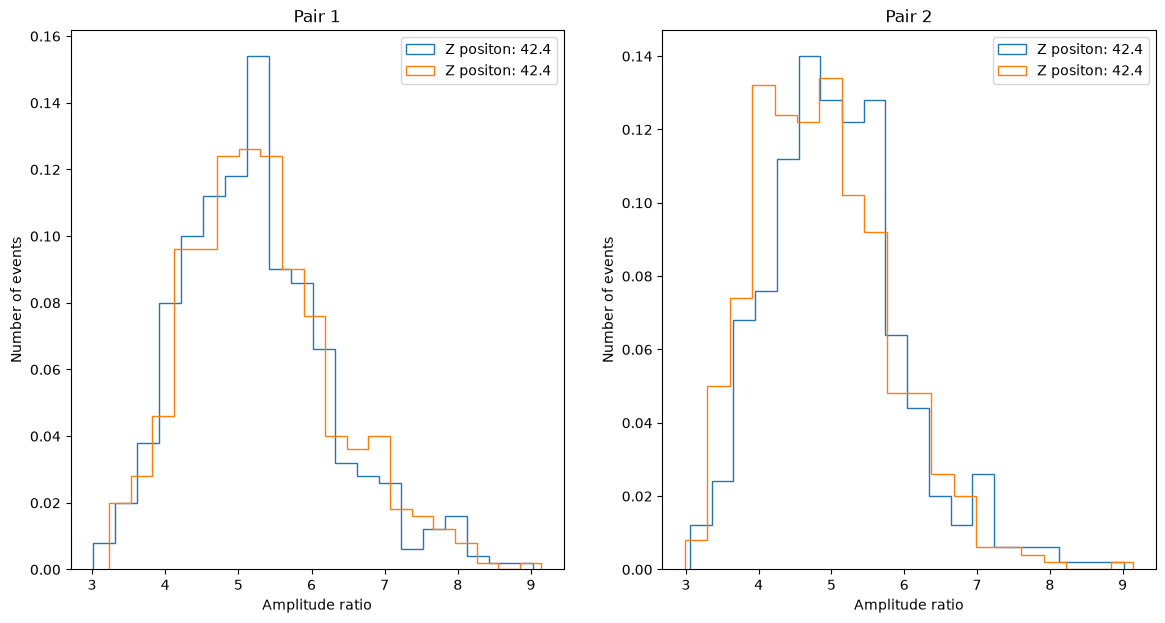

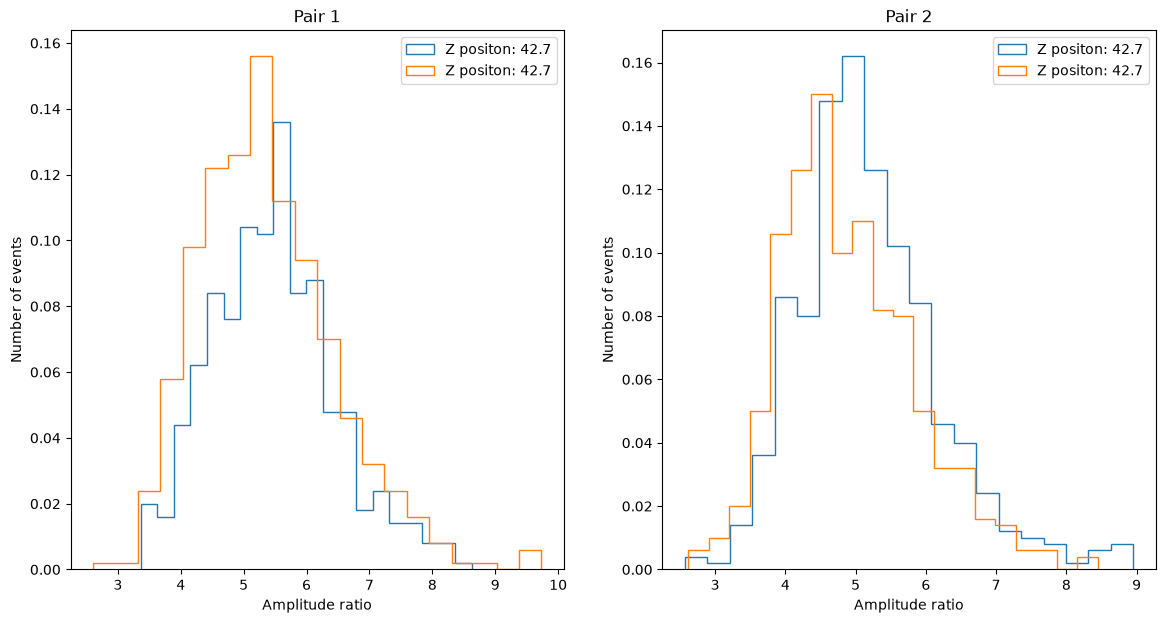

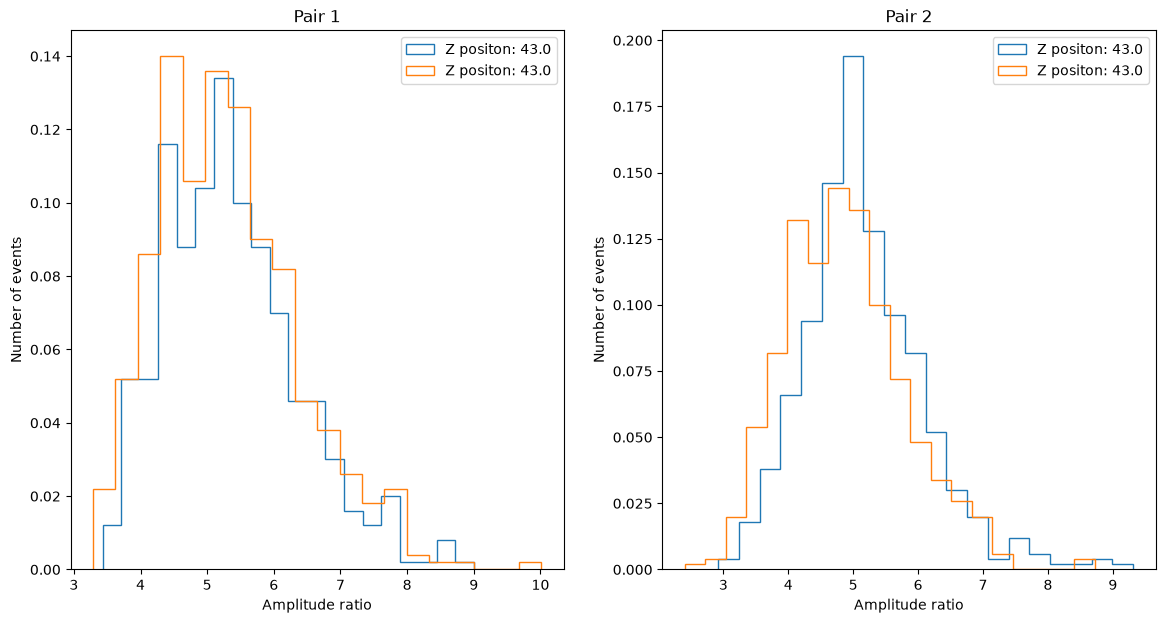

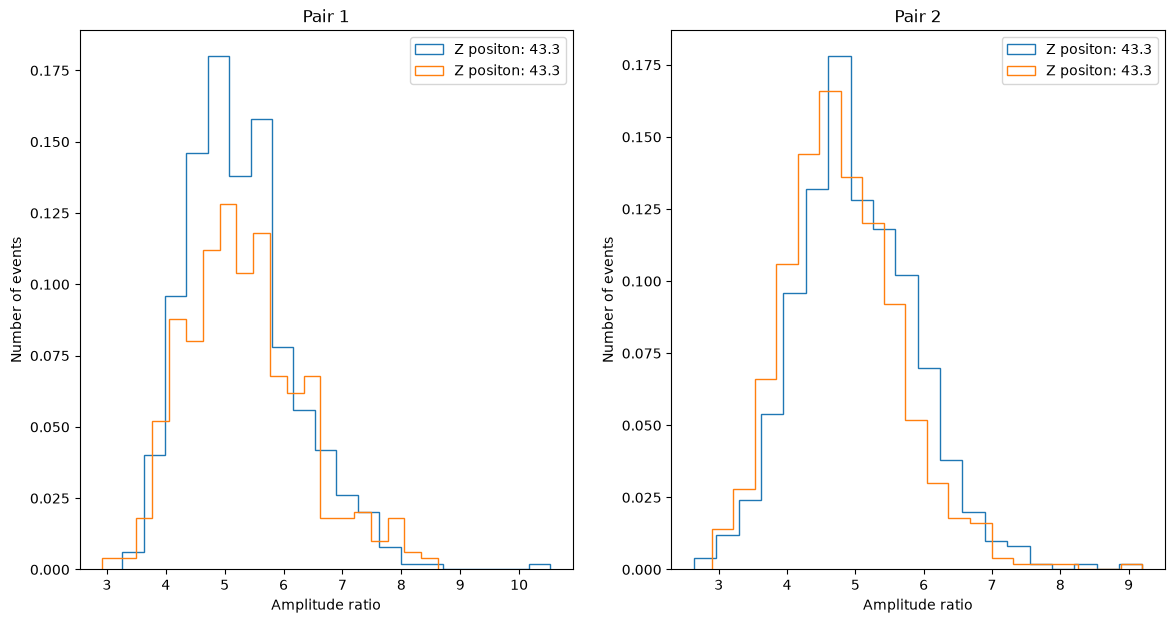

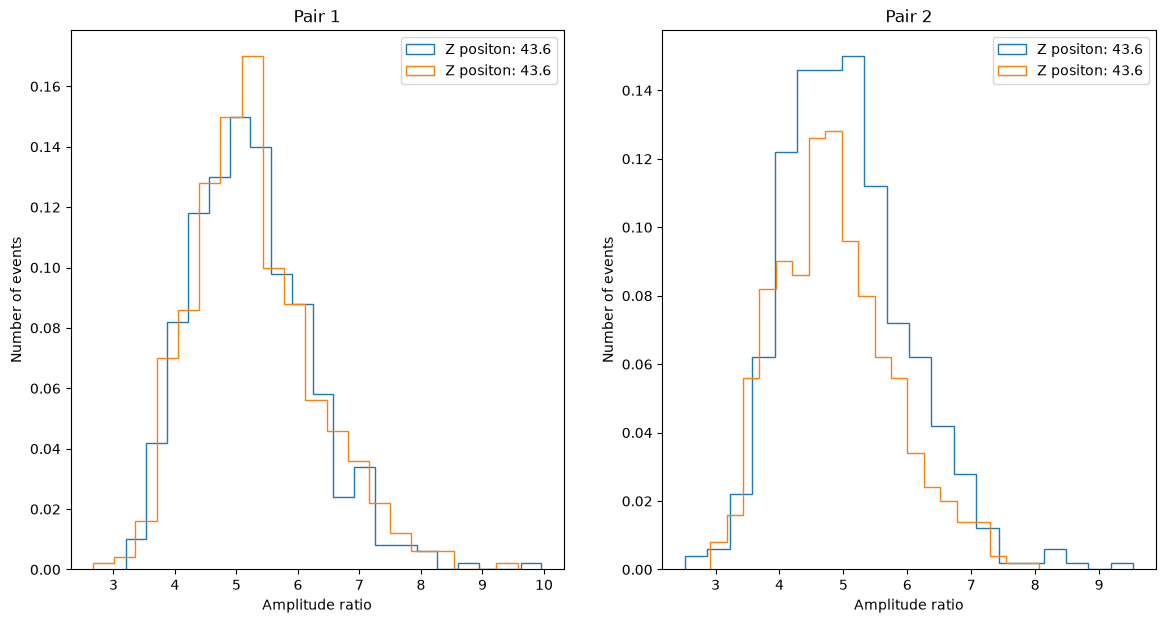

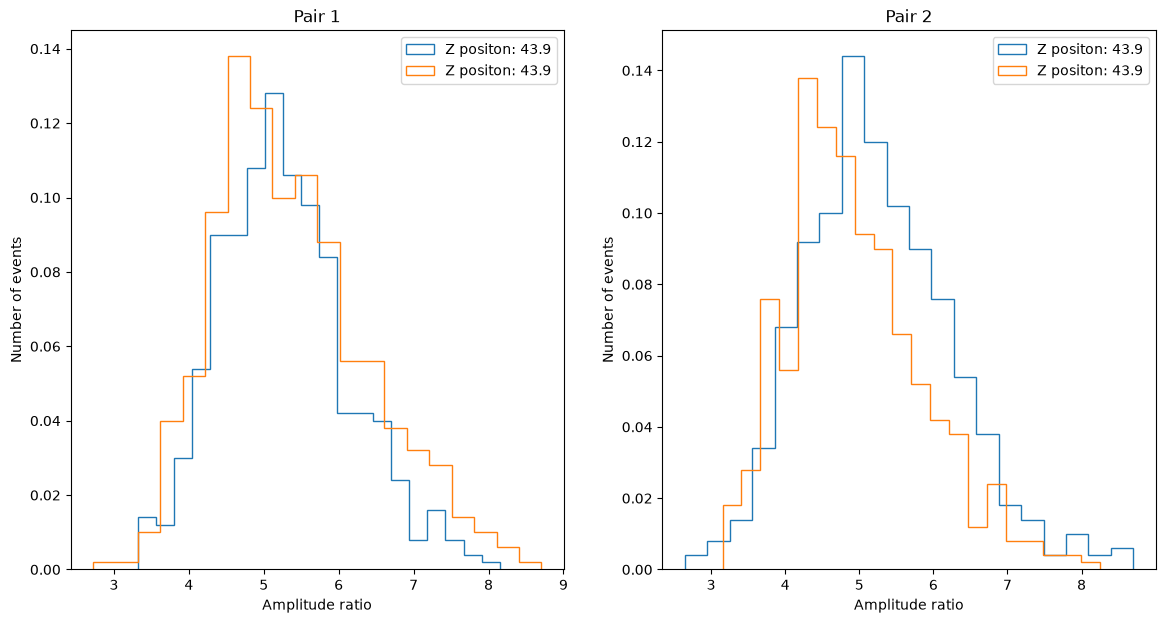

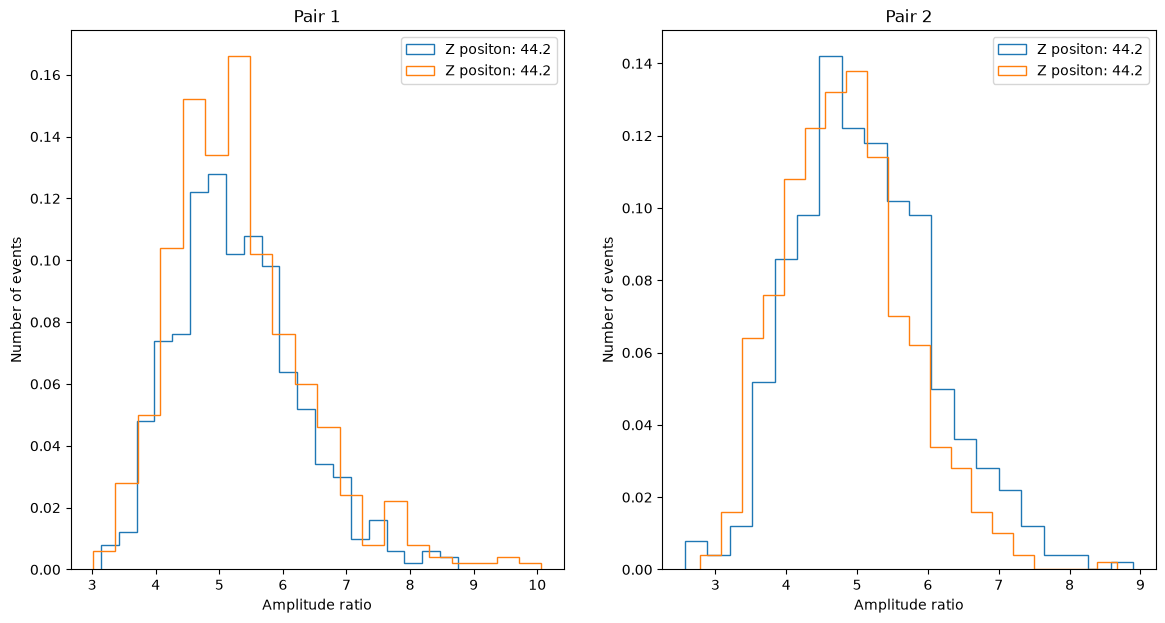

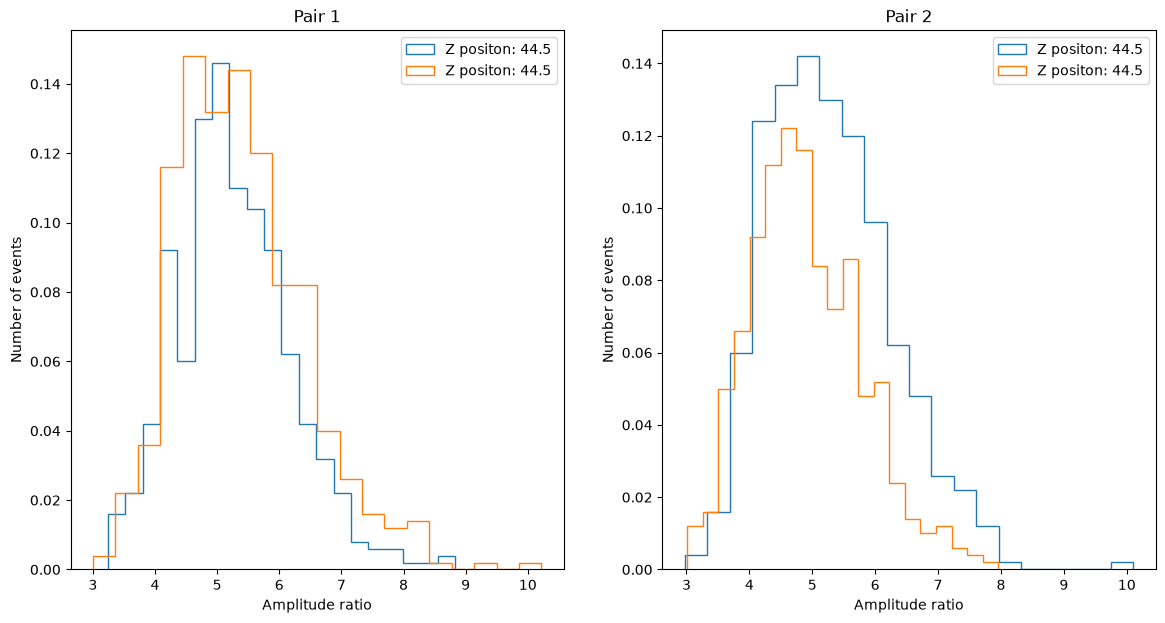

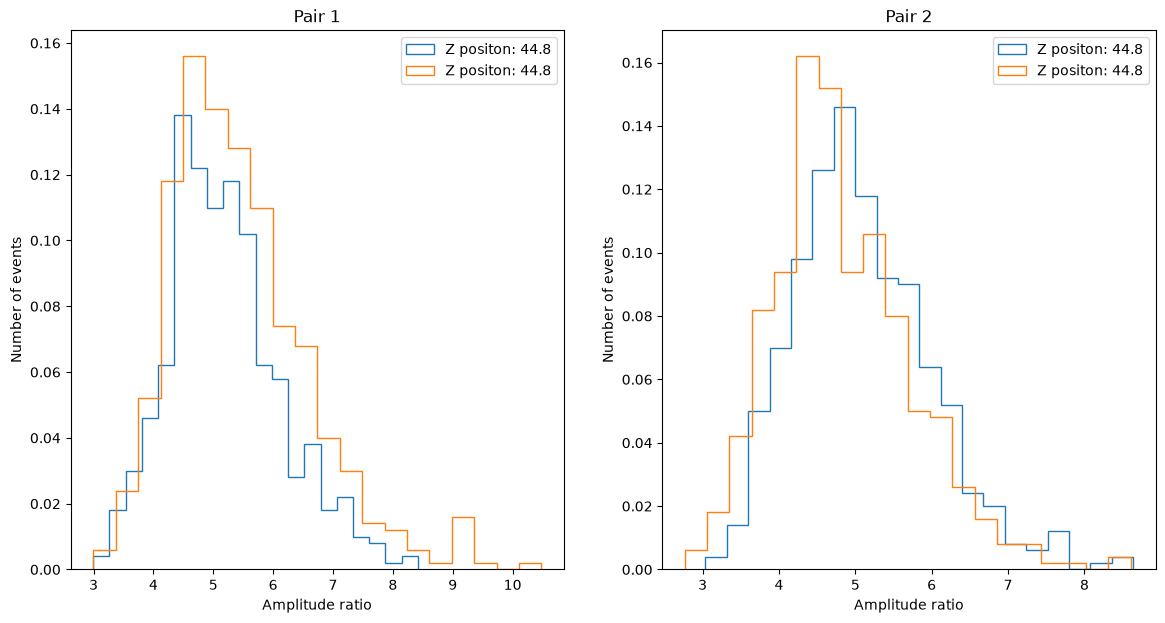

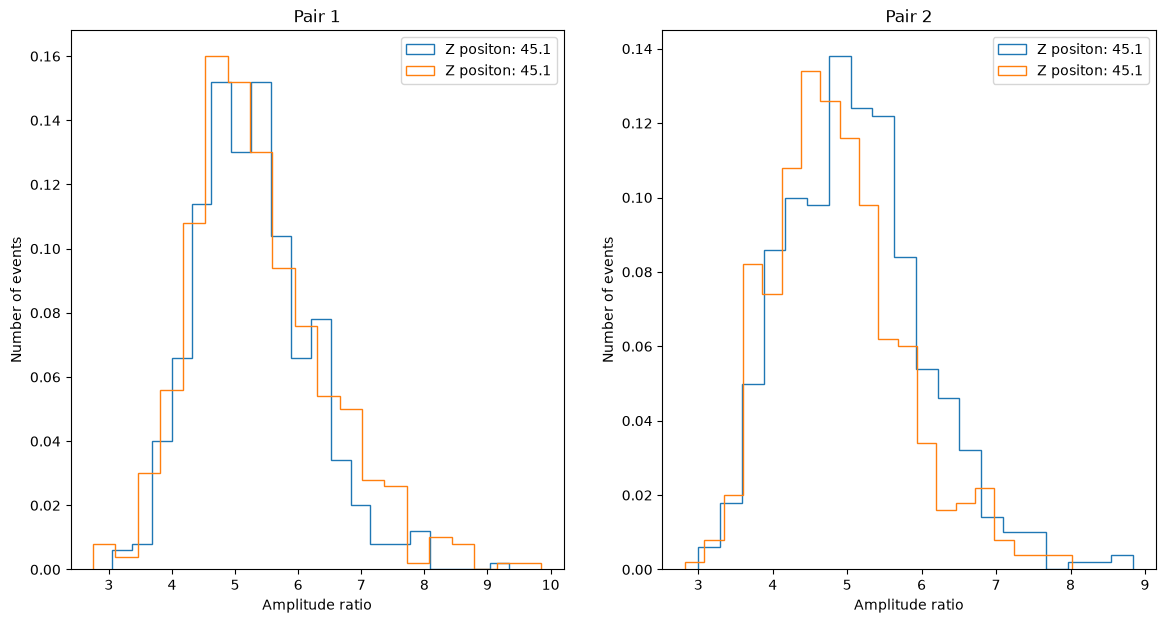

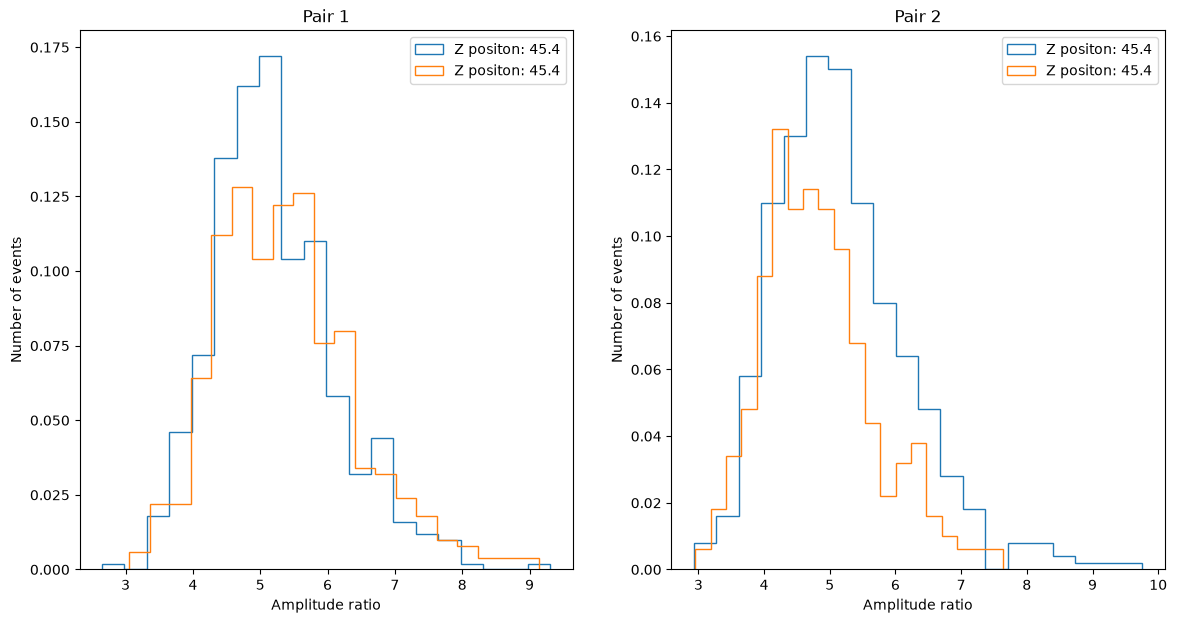

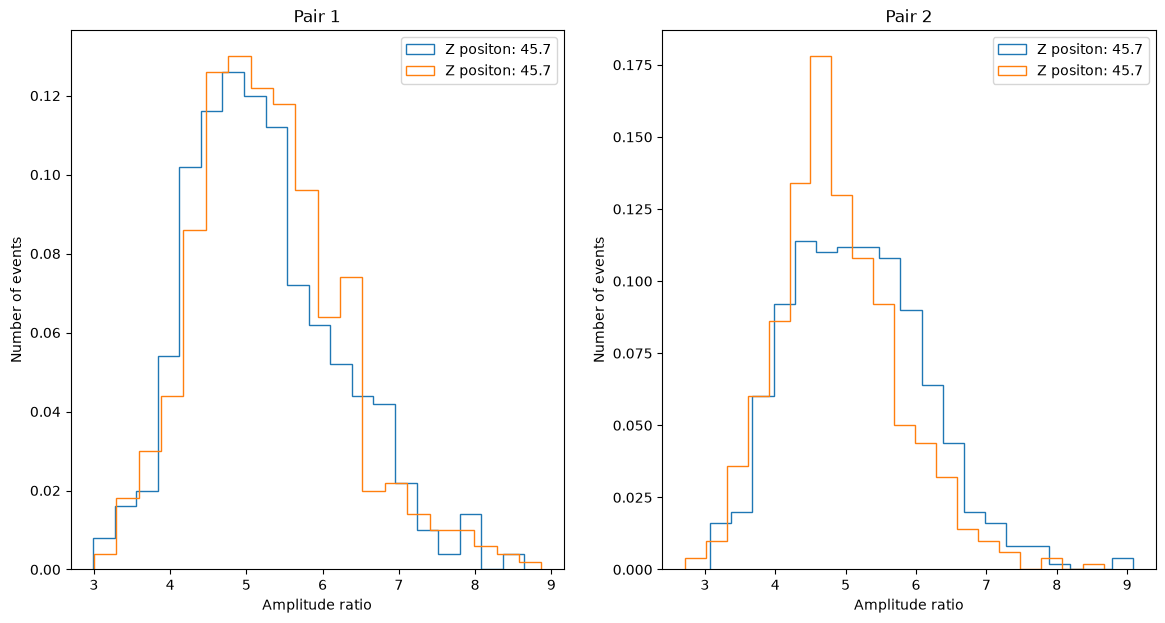

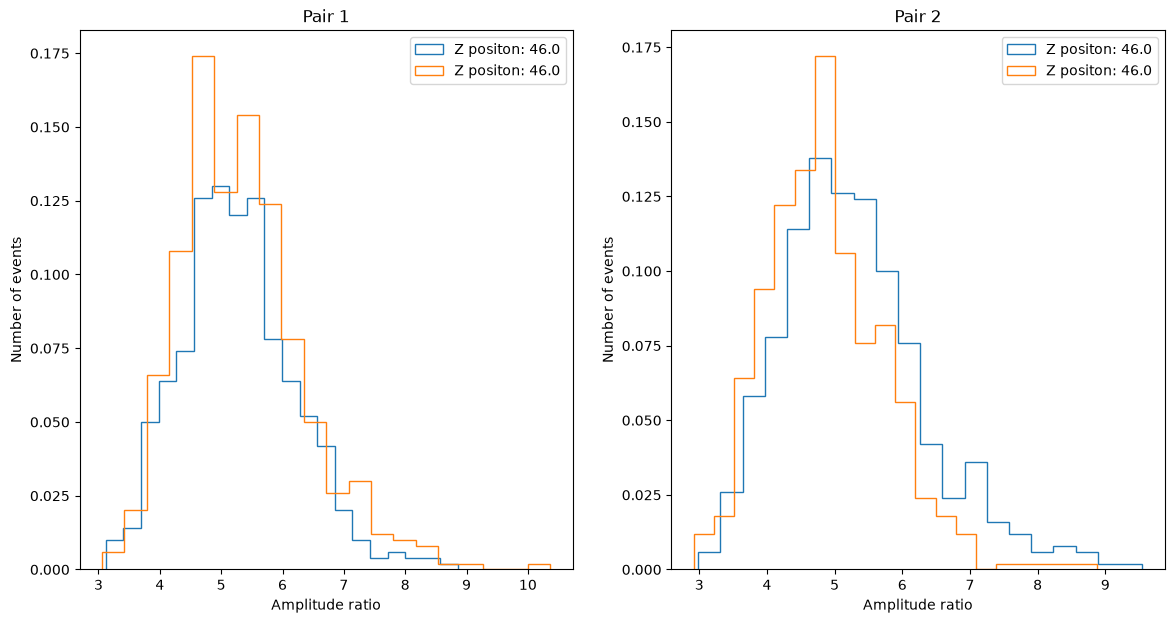

In [40]:
rows = 1
cols = 2
size = 7
nbins = 20

ratio_fraction_1 = []
ratio_fraction_2 = []

for i, z in enumerate(Z_range):
    fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))
    l = f"pos_{z}_41.25_105.0"

    weights = np.ones(len(amp[l][:,3])) * 1.0 / len(amp[l][:,3])

    ax[0].hist(amp[l][:,3], label = f"Z positon: {z}", bins = nbins, histtype = "step", weights = weights)
    ax[0].hist(amp[l][:,4], label = f"Z positon: {z}", bins = nbins, histtype = "step", weights = weights)

    ax[1].hist(amp[l][:,5], label = f"Z positon: {z}", bins = nbins, histtype = "step", weights = weights)
    ax[1].hist(amp[l][:,6], label = f"Z positon: {z}", bins = nbins, histtype = "step", weights = weights)

    ax[0].set_title("Pair 1")
    ax[0].set_xlabel("Amplitude [mV]")
    ax[0].set_ylabel("Number of events")
    ax[0].legend()

    ax[1].set_title("Pair 2")
    ax[1].set_xlabel("Amplitude [mV]")
    ax[1].set_ylabel("Number of events")
    ax[1].legend()
    
    plt.show()


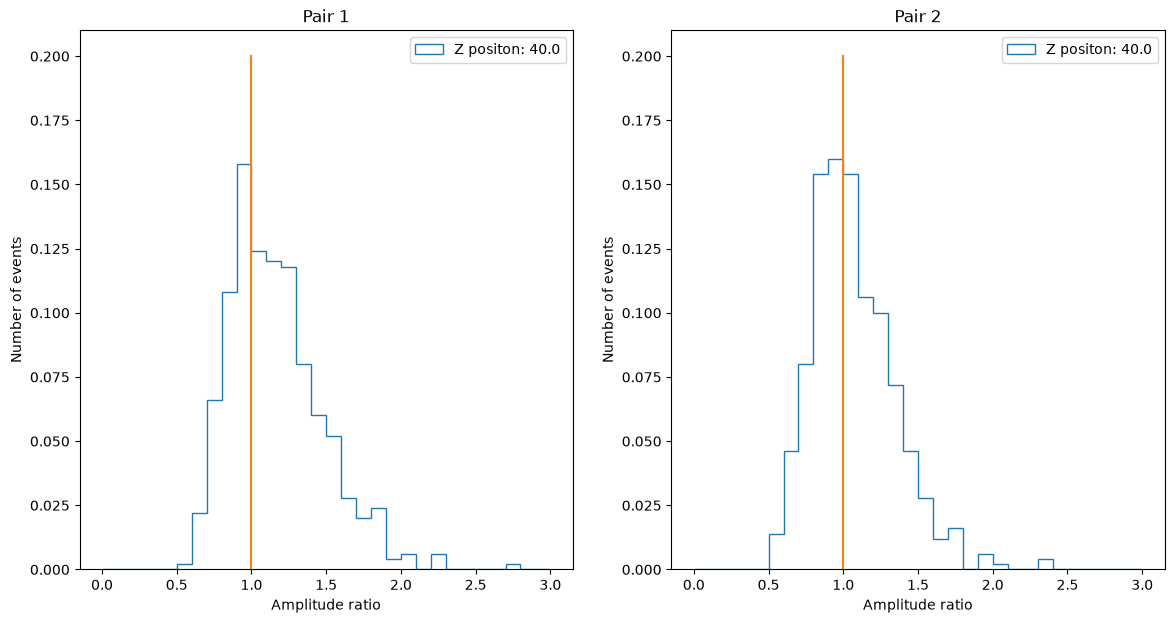

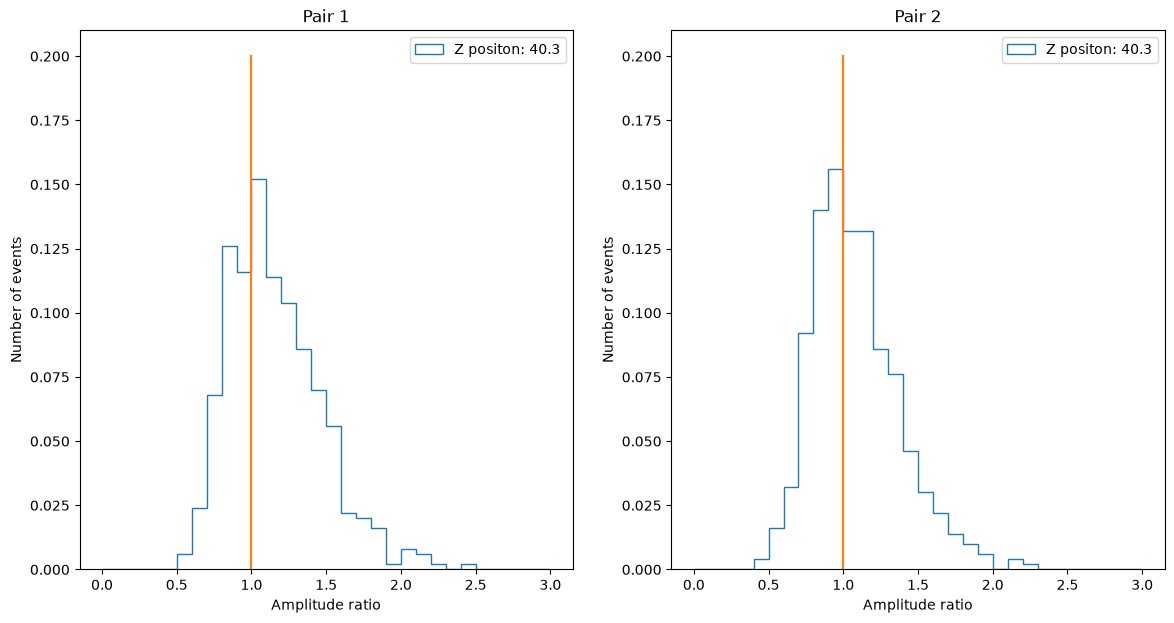

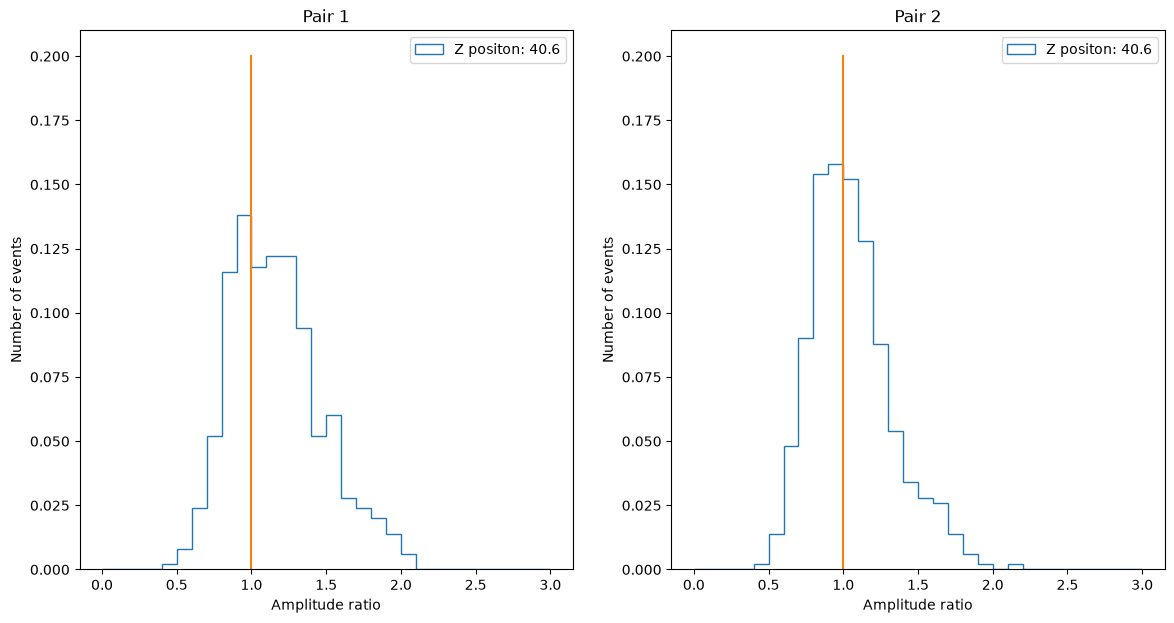

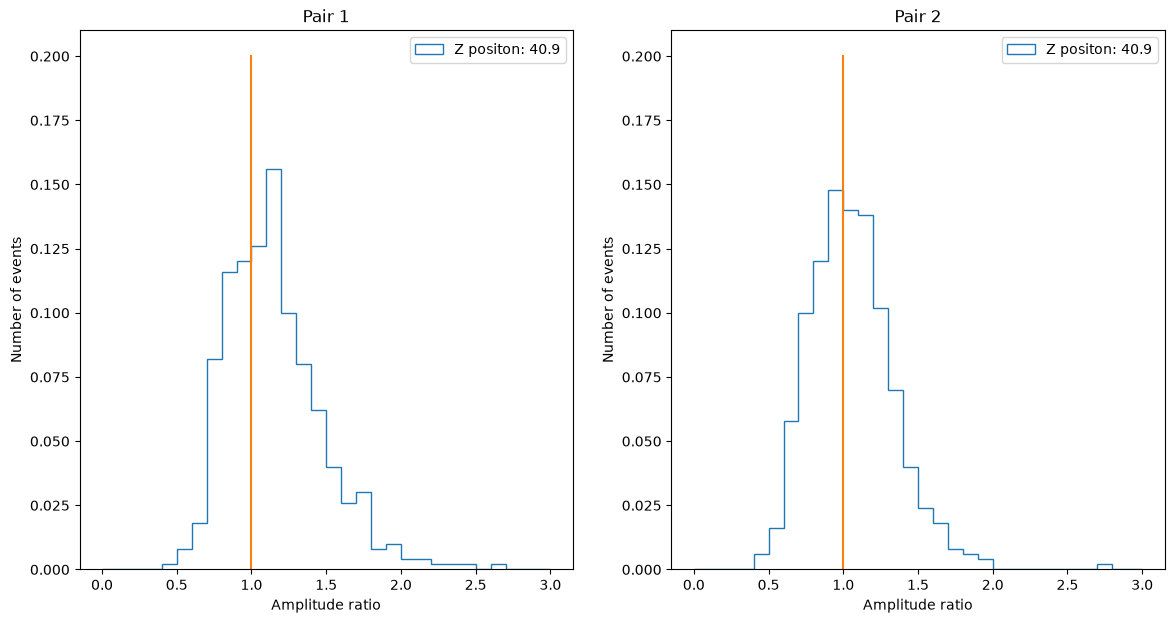

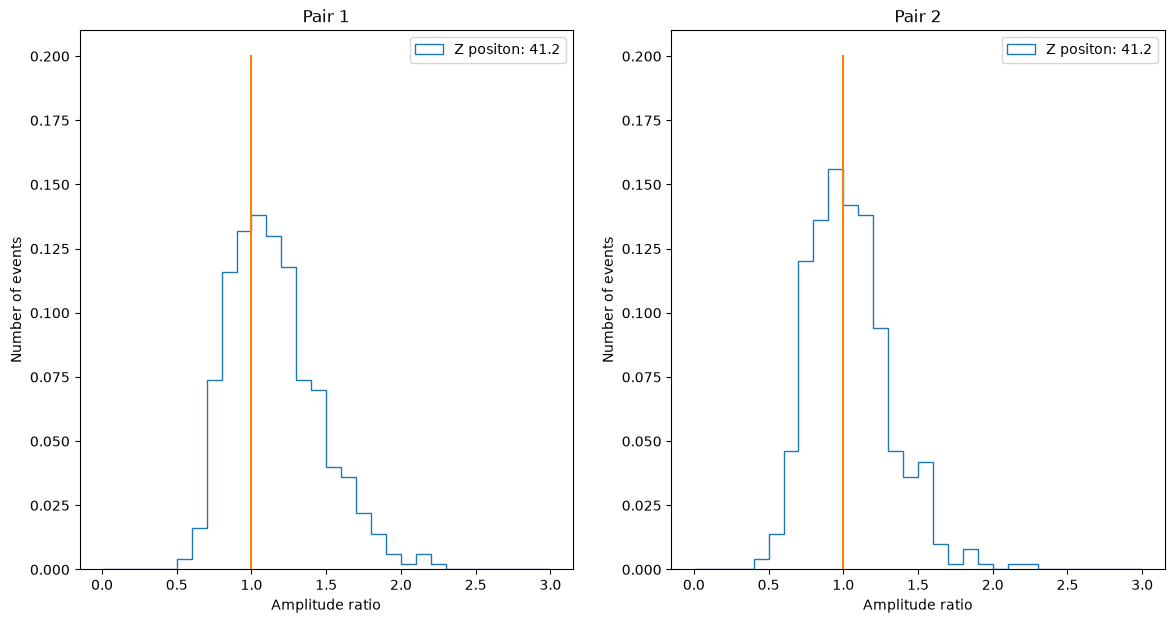

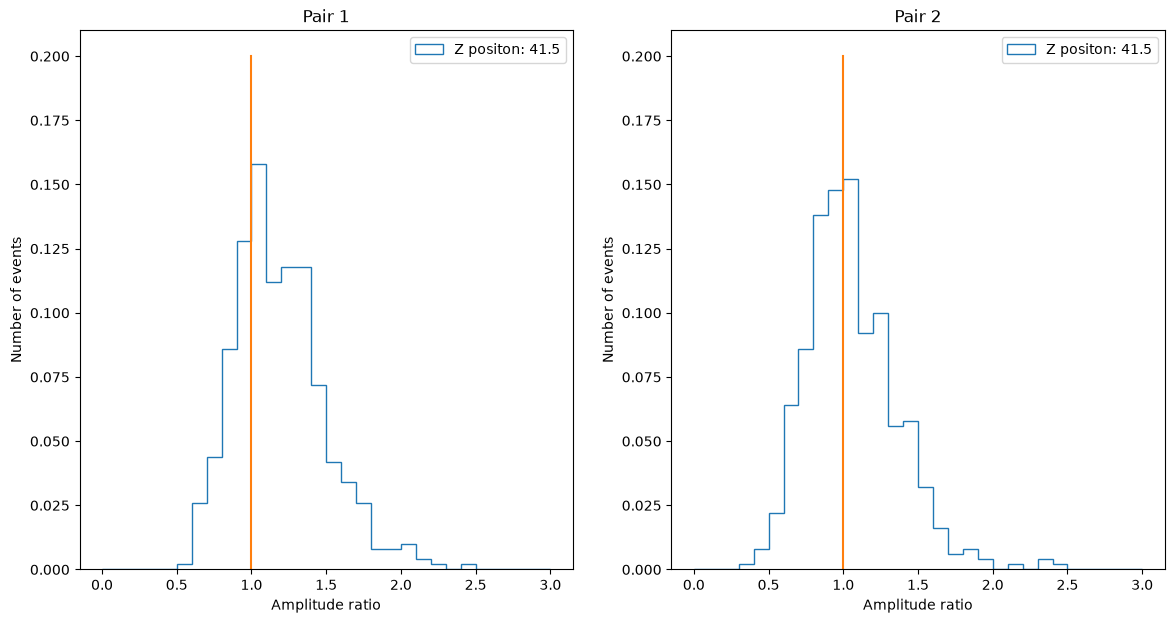

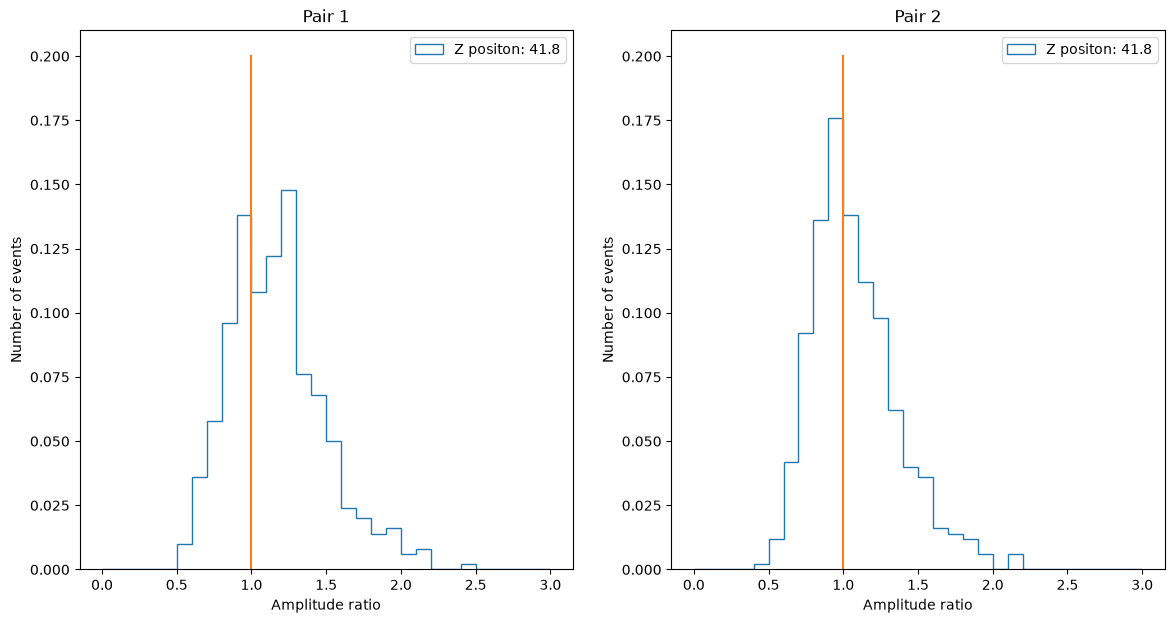

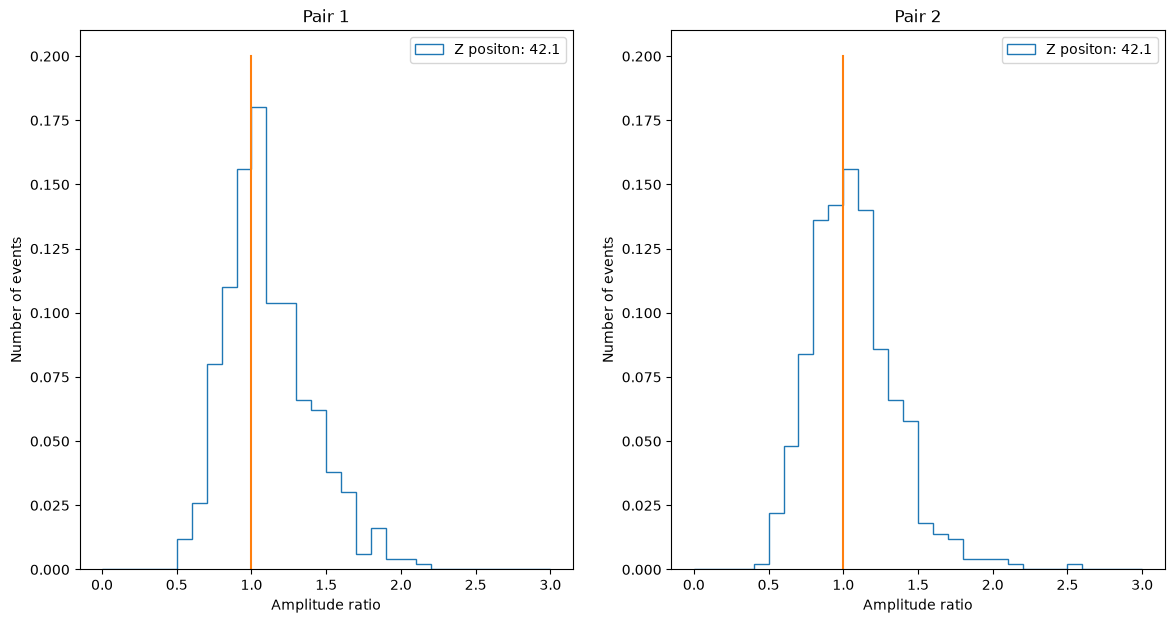

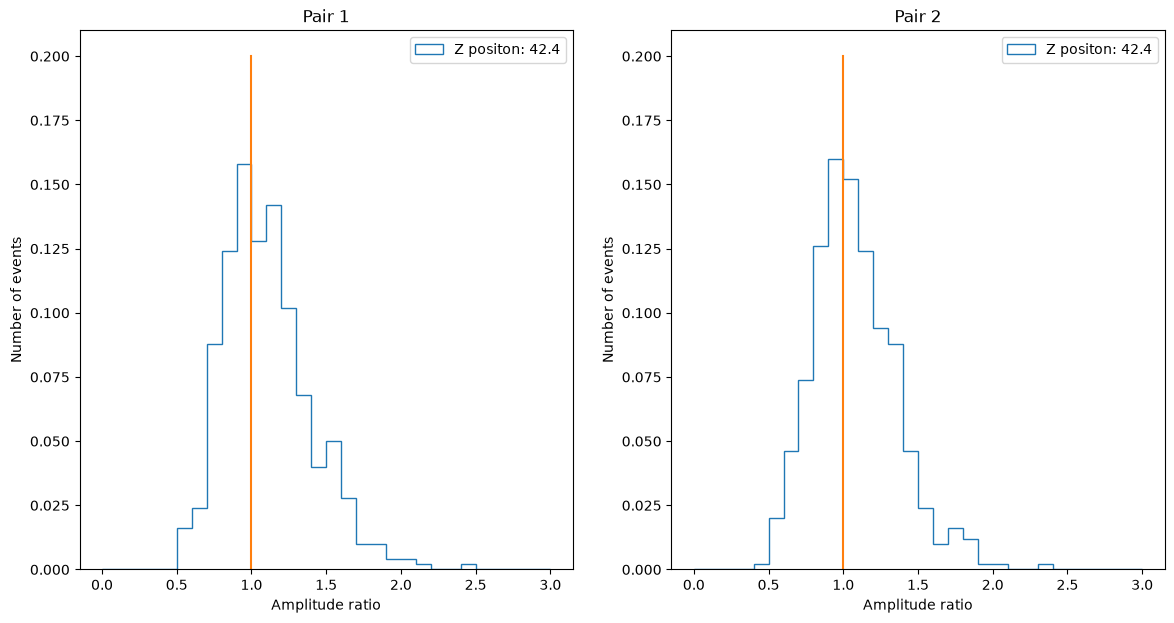

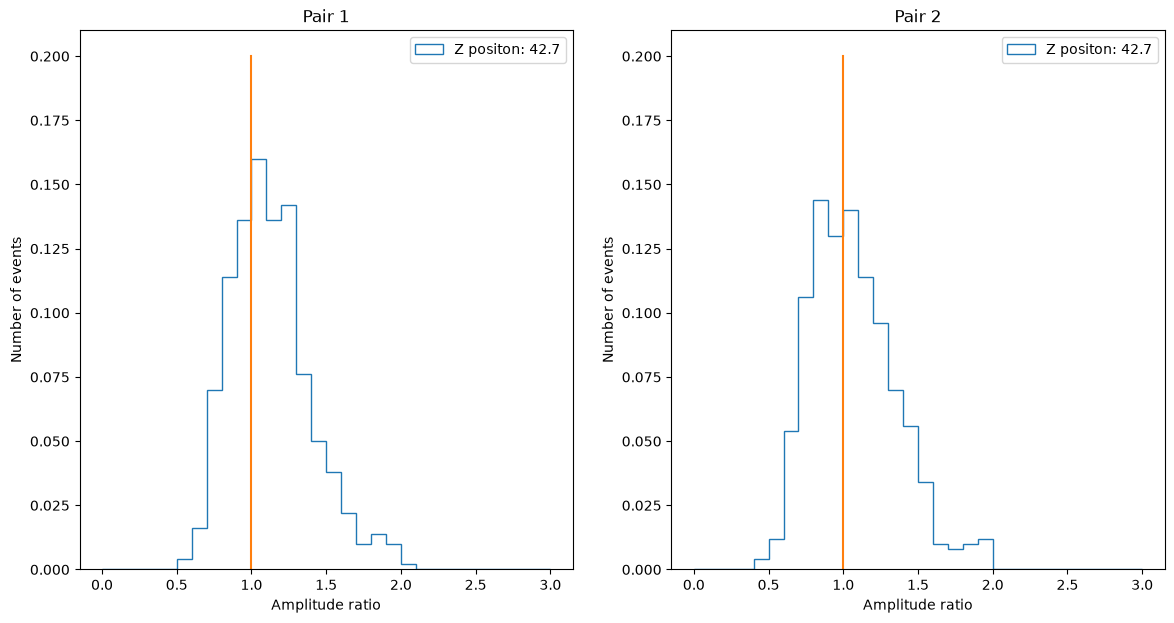

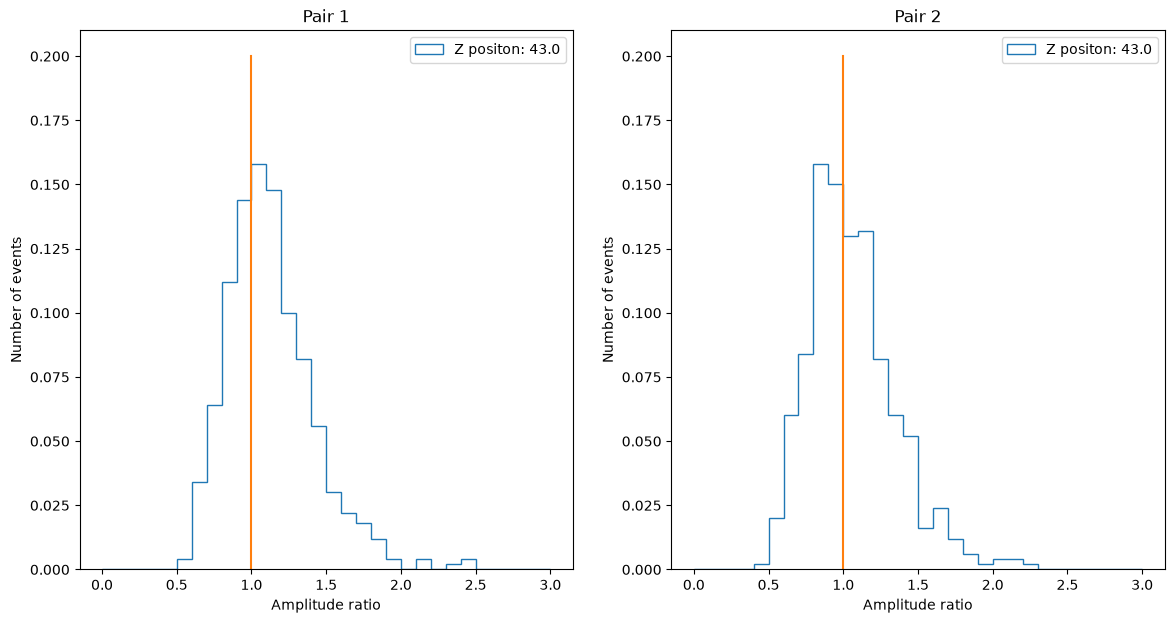

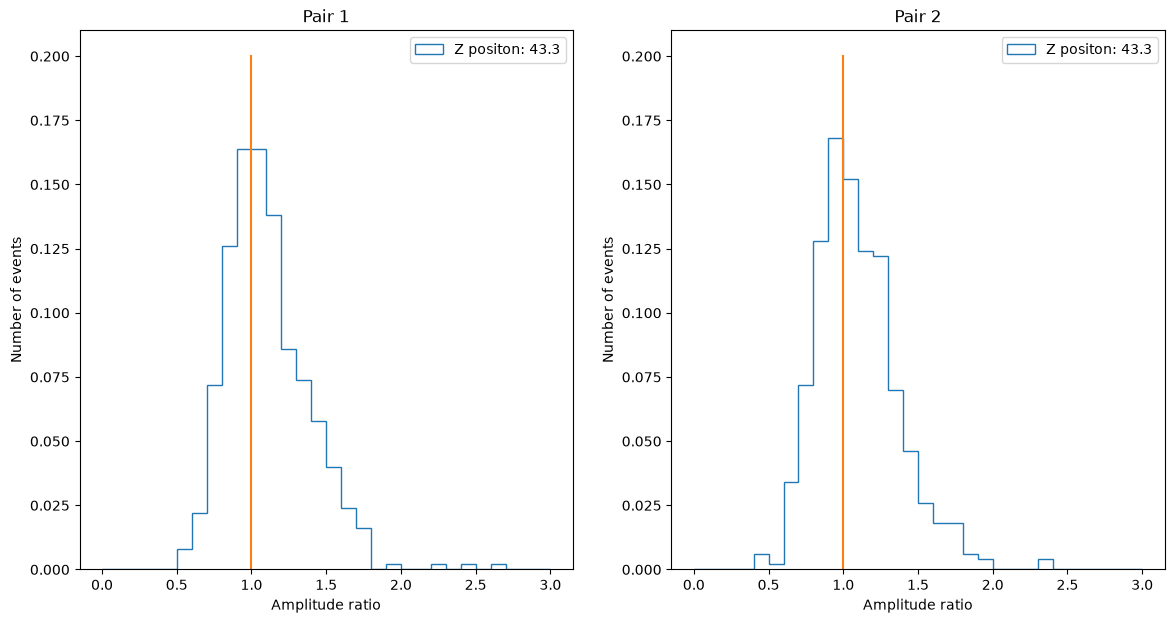

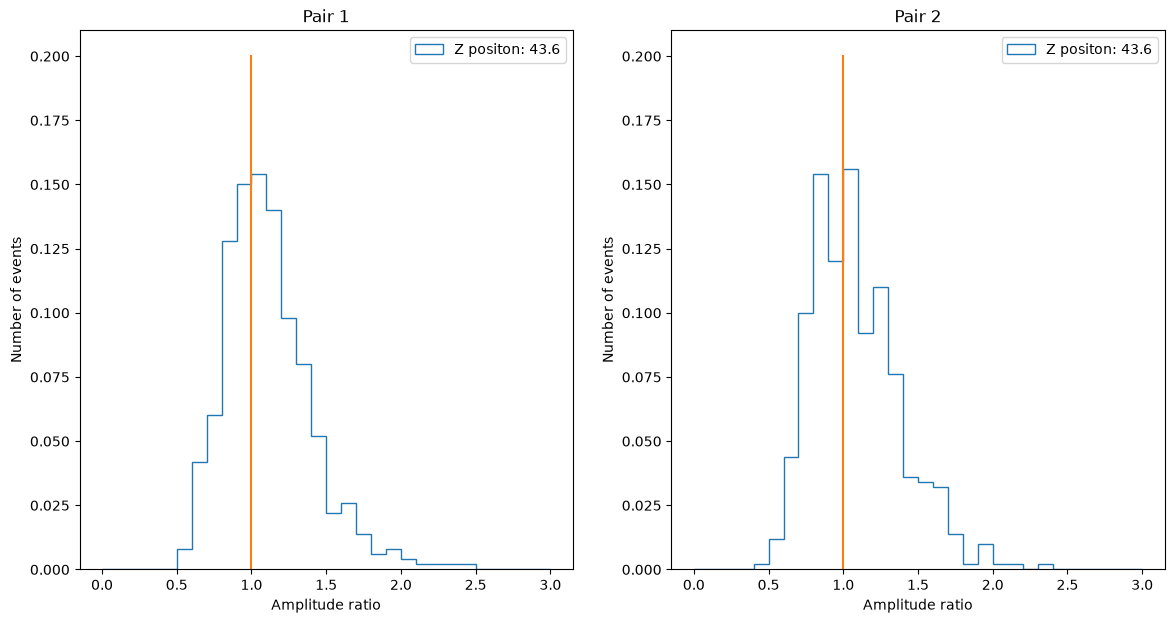

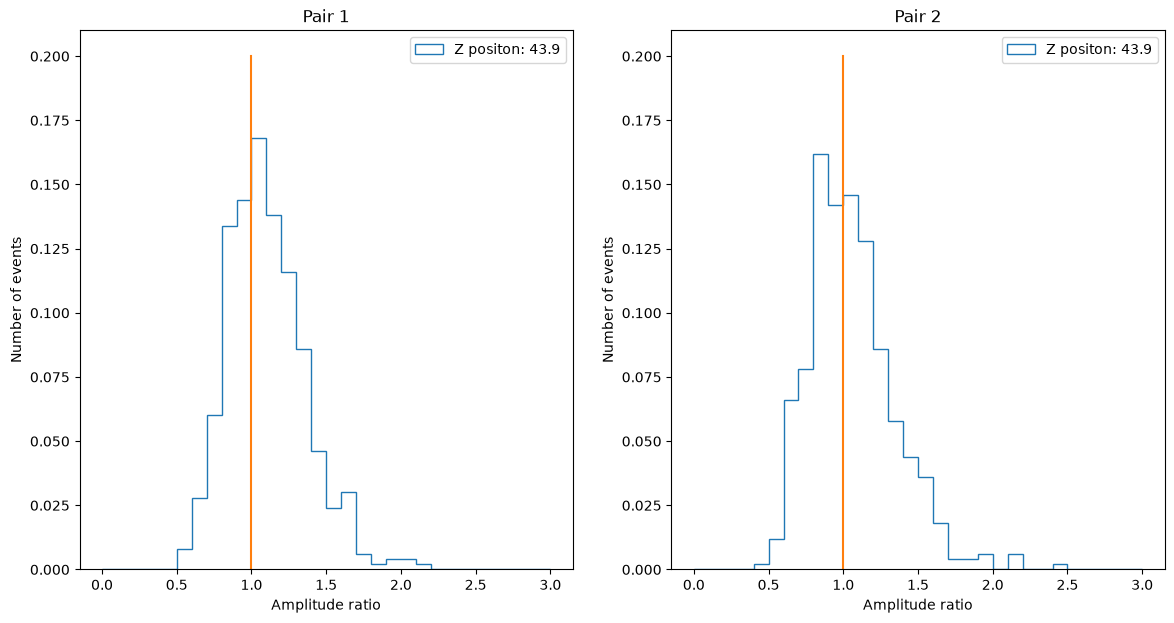

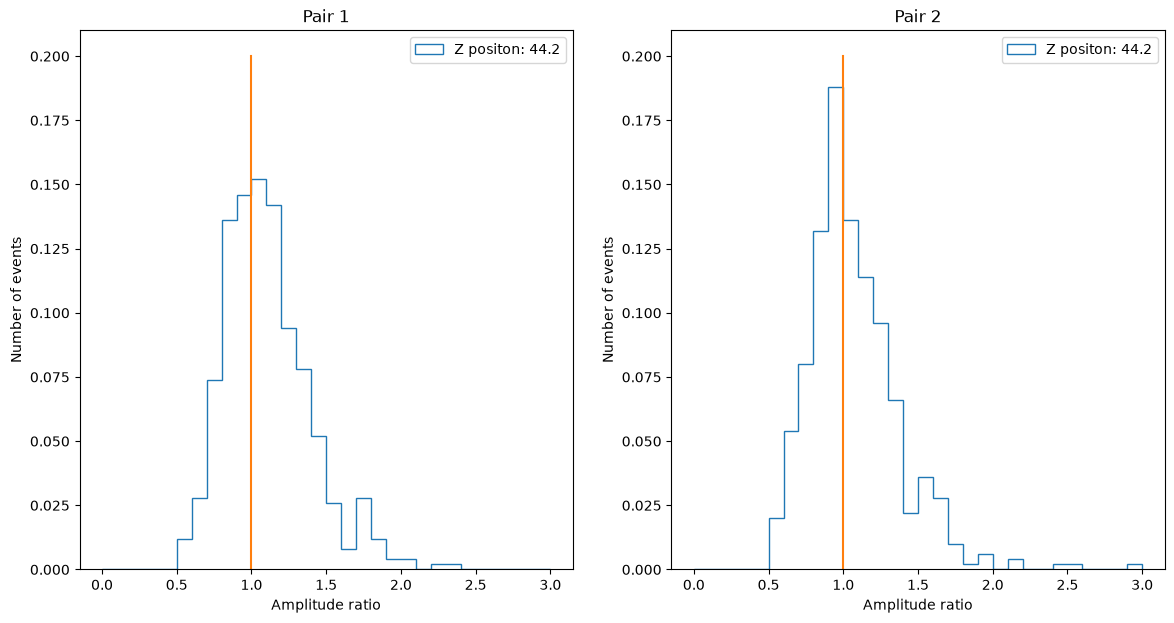

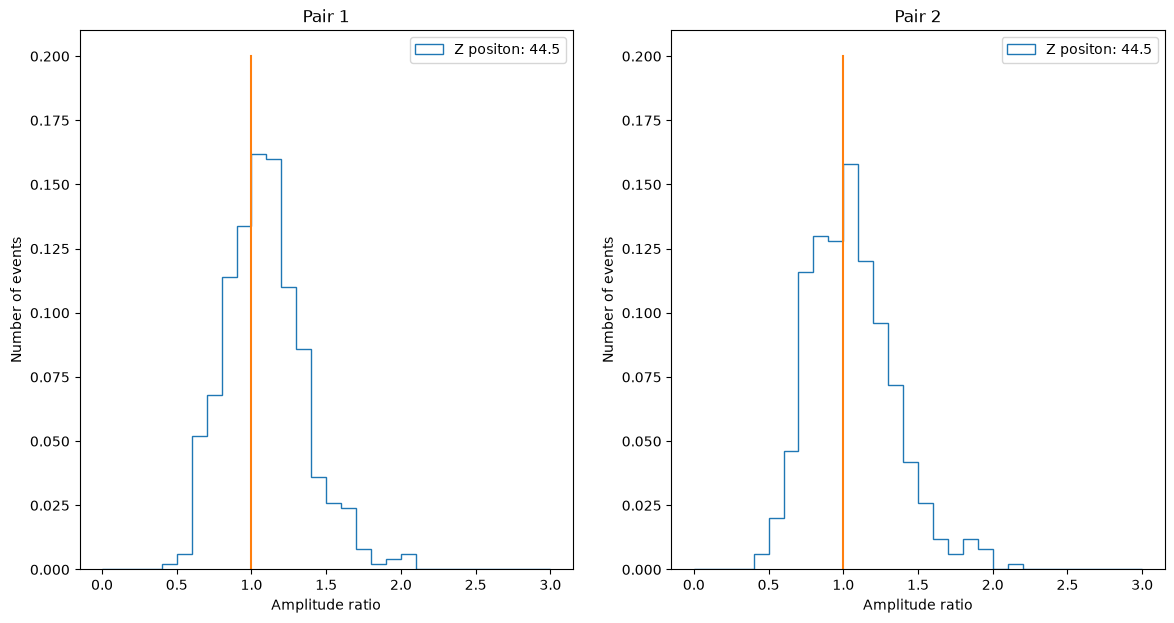

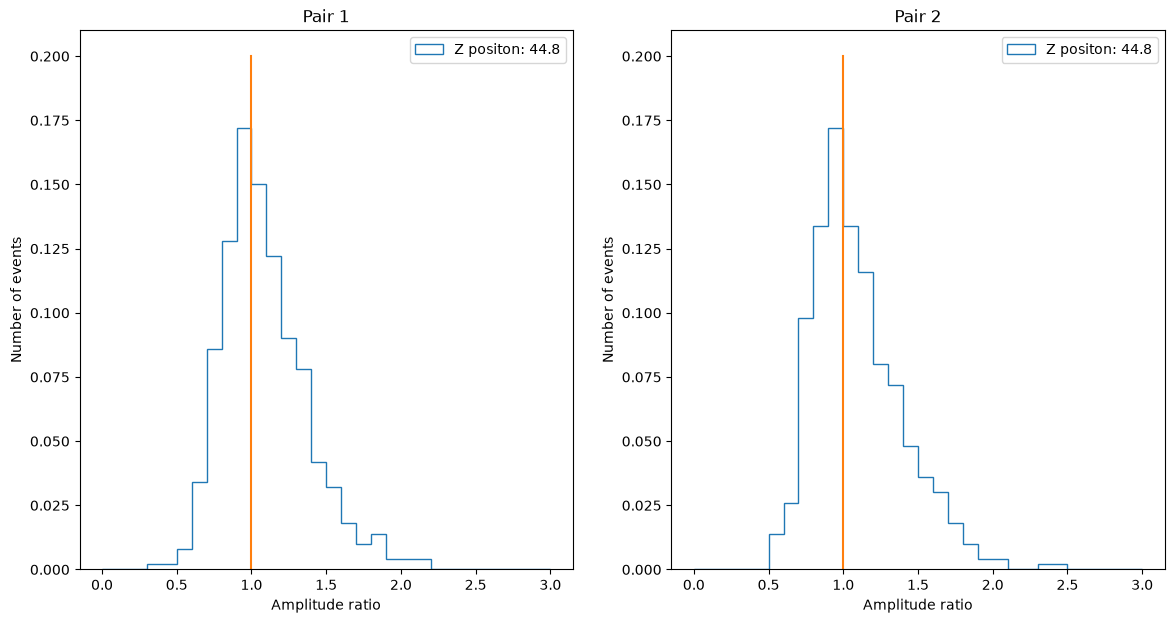

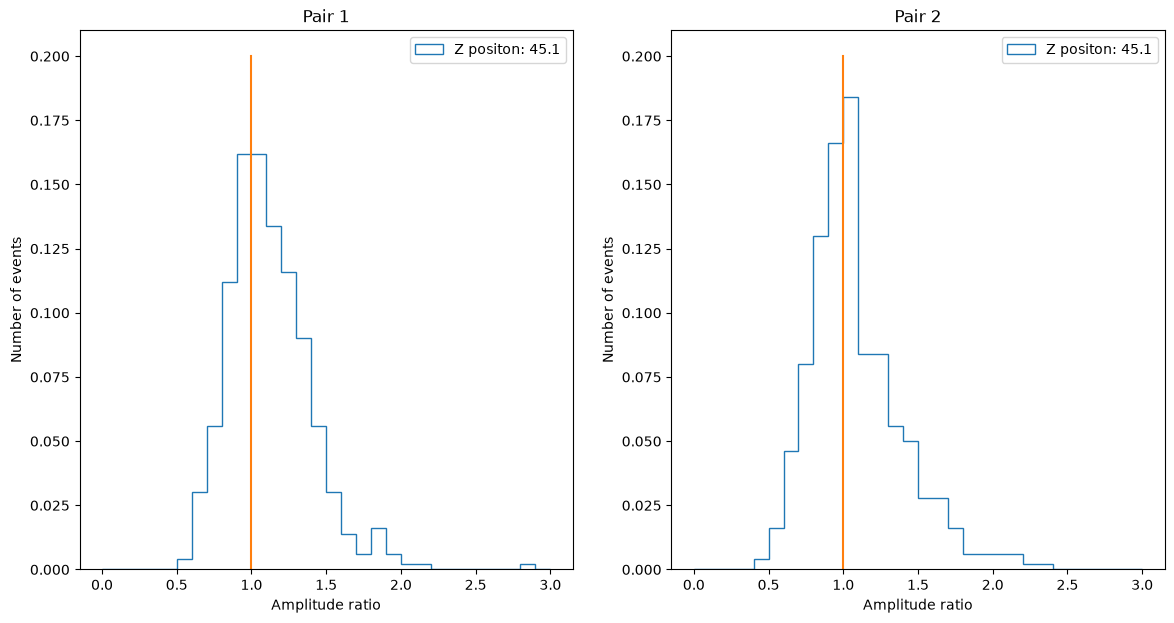

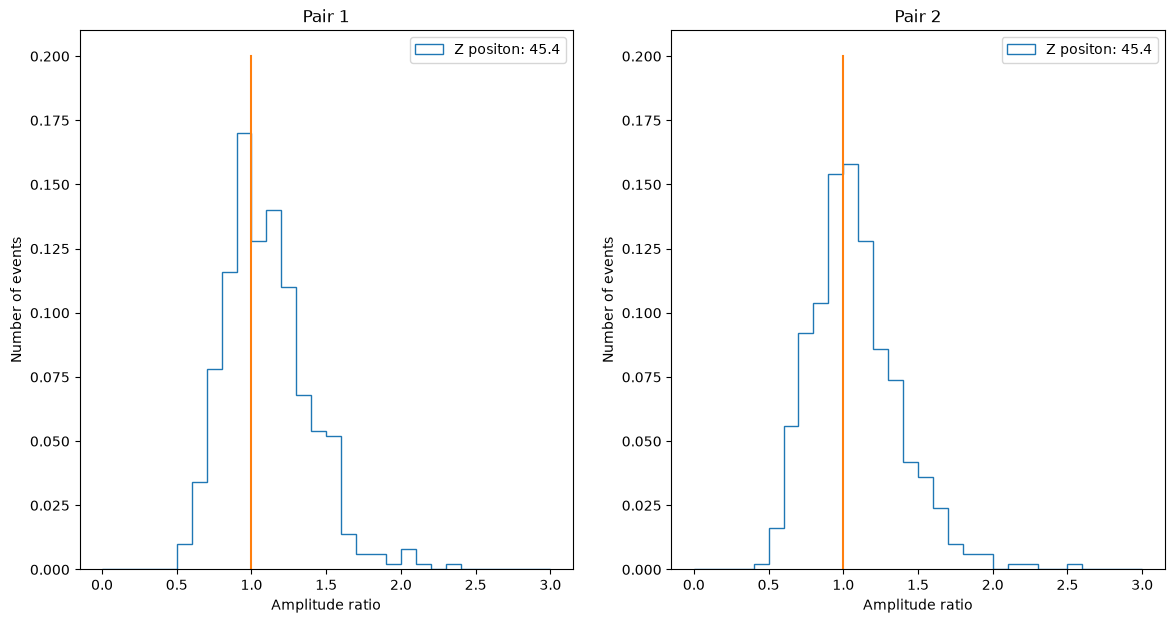

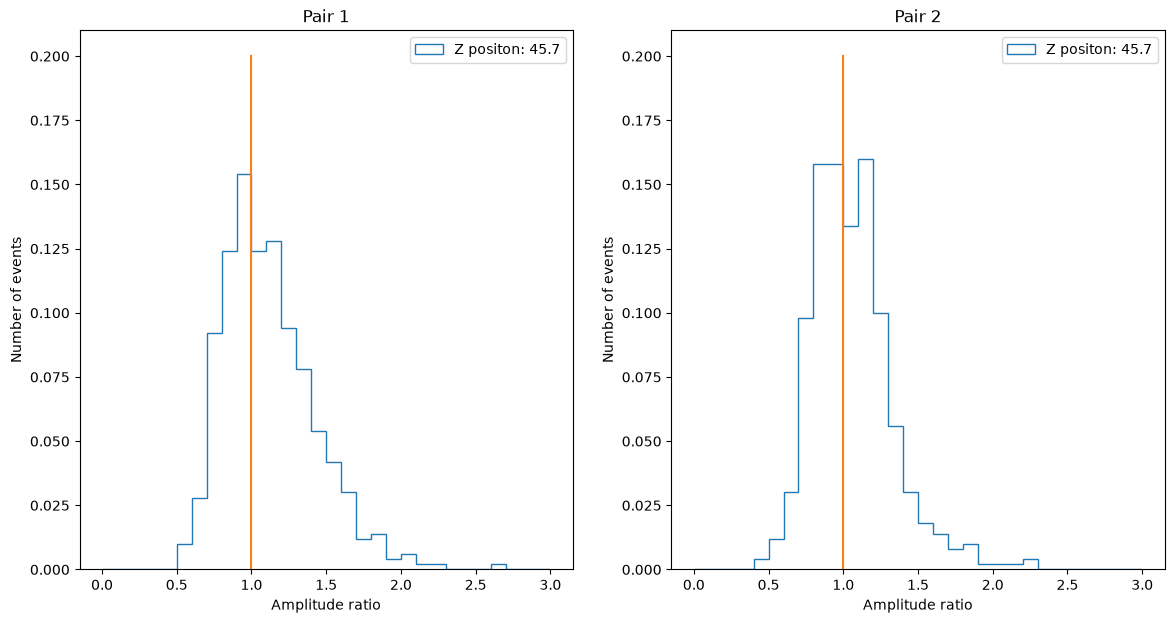

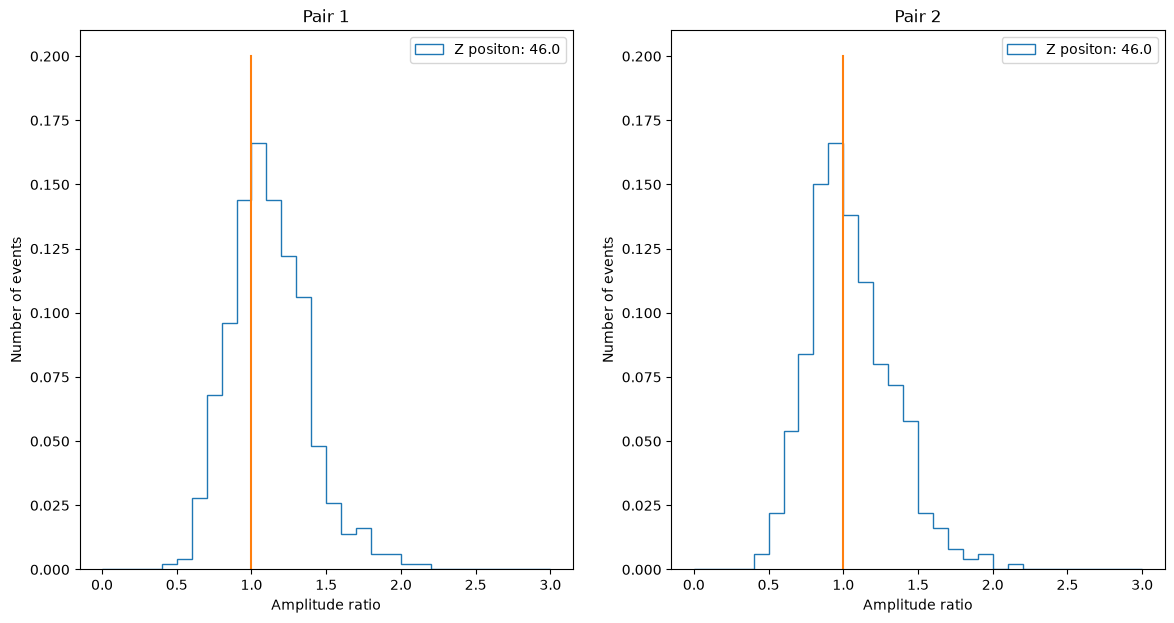

In [35]:
rows = 1
cols = 2
size = 7
nbins = 30

ratio_fraction_1 = []
ratio_fraction_2 = []

for i, z in enumerate(Z_range):
    fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))
    l = f"pos_{z}_41.25_105.0"

    weights = np.ones(len(amp[l][:,3])) * 1.0 / len(amp[l][:,3])

    ratio_1 = amp[l][:,3] / amp[l][:,2]
    ratio_2 = amp[l][:,4] / amp[l][:,5]

    ratio_fraction_1.append(np.sum(ratio_1>1))
    ratio_fraction_2.append(np.sum(ratio_2>1))
    
    ax[0].hist(ratio_1, label = f"Z positon: {z}", range = (0, 3), bins = nbins, histtype = "step", weights = weights)
    ax[1].hist(ratio_2, label = f"Z positon: {z}", range = (0, 3), bins = nbins, histtype = "step", weights = weights)

    ax[0].plot([1.0, 1.0], [0, 0.2])
    ax[0].set_title("Pair 1")
    ax[0].set_xlabel("Amplitude ratio")
    ax[0].set_ylabel("Number of events")
    ax[0].legend()

    ax[1].plot([1.0, 1.0], [0, 0.2])
    ax[1].set_title("Pair 2")
    ax[1].set_xlabel("Amplitude ratio")
    ax[1].set_ylabel("Number of events")
    ax[1].legend()
    
    plt.show()


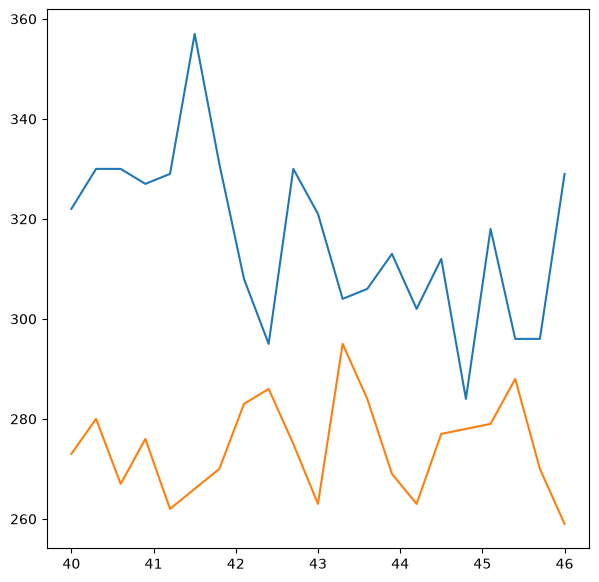

In [38]:
rows = 1
cols = 1
size = 7
nbins = 30

fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

ax.plot(Z_range, ratio_fraction_1)

ax.plot(Z_range, ratio_fraction_2)